# Asistente NLP de ElectriSys — ciclo CRISP-ML(Q)

**Proyecto:** ElectriSys, punto de venta para una tienda de repuestos automotrices y agrícolas.
**Componente:** microservicio `nlp-service/` (FastAPI + scikit-learn + RapidFuzz).
**Qué es este cuaderno:** la evidencia ejecutada de cada fase de CRISP-ML(Q) aplicada al asistente, usando el código y los datos reales del repositorio. El documento que mapea las fases a los archivos es `nlp-service/docs/CRISP-ML.md`.

**Reglas que sigue el cuaderno**

- Importa la lógica del proyecto (`app.preprocessing`, `app.intent.train._construir_pipeline`, `app.intent.classifier.predecir_intencion`, `app.ner.extractor`, `app.recommender`); no la copia ni la reescribe.
- **No modifica ningún archivo del proyecto.** Los modelos se entrenan en memoria. Lo único que escribe va a `notebooks/salida/`: la base de datos SQLite de trabajo y el script SQL para cargar el dataset en Oracle (§2.3). La última celda comprueba con SHA-256 que `models/`, `eval/`, el dataset y los scripts de `oracle/` quedaron intactos.
- Todos los números del texto salen de celdas ejecutadas de este cuaderno.

| # | Fase CRISP-ML(Q) | Sección |
|---|---|---|
| 0 | Configuración y huella de los archivos protegidos | §0 |
| 1 | Comprensión del negocio | §1 |
| 2 | Comprensión de los datos: flujo de entrada y salida, construcción del dataset, base de datos, gráficas, media, mediana y moda | §2 |
| 3 | Preparación de los datos | §3 |
| 4 | Modelado (incluye la tabla de parámetros del modelo) | §4 |
| 5 | Evaluación (incluye las tablas consolidadas de métricas) | §5 |
| 6 | Despliegue (incluye el recorrido de una consulta de la entrada a la salida) | §6 |
| 7 | Monitoreo y mantenimiento | §7 |
| 8 | Conclusiones, problemas encontrados y trabajo futuro | §8 |

## 0. Configuración

El cuaderno vive en `nlp-service/notebooks/`; se agrega `nlp-service/` al `sys.path` para importar `app` y `eval` igual que lo hacen los scripts del proyecto (`python -m eval.eval_intent`). `sys.dont_write_bytecode` evita que Python deje archivos `.pyc` dentro de `eval/` al importar.

In [1]:
import sys
sys.dont_write_bytecode = True

import hashlib, json, platform, re, subprocess, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, rapidfuzz
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

# ── Código del proyecto (importado, no copiado) ───────────────────────
from app.preprocessing import normalizar, preprocesar, STOPWORDS_ES
from app.intent.train import _construir_pipeline, DATASET_PATH, MODEL_PATH, METRICS_PATH
from app.intent.classifier import predecir_intencion, UMBRAL_CONFIANZA, INTENCION_FALLBACK
from app.ner.extractor import extraer_entidades, SINONIMOS_CATEGORIA, UMBRAL_FUZZY, UMBRAL_FUZZY_TYPO
from app.recommender.tfidf_cosine import SimilitudTfidfCoseno
from app.pipeline import _fusionar_entidades, _falta_vehiculo, TOP_K
from app.nlg import templates
from eval.eval_intent import HOLDOUT_PATH as HOLDOUT_INTENT_PATH
from eval.eval_ner import (MARCAS, MODELOS, CATEGORIAS, _coincide,
                           HOLDOUT_PATH as HOLDOUT_NER_PATH)
from eval.eval_recomendador import RESULTADOS_PATH as RESULTADOS_RECO_PATH

SEMILLA = 42
np.random.seed(SEMILLA)

import sqlite3
ORACLE_DIR = RAIZ.parent / "oracle"        # esquema y datos semilla de la base real (Oracle 23ai)
SALIDA = RAIZ / "notebooks" / "salida"     # único lugar donde el cuaderno escribe archivos
SALIDA.mkdir(exist_ok=True)

print(f"Python        {platform.python_version()}")
print(f"scikit-learn  {sklearn.__version__}   (requirements.txt fija 1.5.2)")
print(f"rapidfuzz     {rapidfuzz.__version__}")
print(f"pandas        {pd.__version__}")
print(f"matplotlib    {matplotlib.__version__}")
print(f"SQLite        {sqlite3.sqlite_version}")
print(f"Raíz del servicio: {RAIZ.name}/")

Python        3.12.2
scikit-learn  1.5.2   (requirements.txt fija 1.5.2)
rapidfuzz     3.9.7
pandas        2.2.3
matplotlib    3.11.2
SQLite        3.43.1
Raíz del servicio: nlp-service/


In [2]:
# Huella de los archivos que el cuaderno NO debe modificar (se verifica en la última celda)
PROTEGIDOS = ([MODEL_PATH, METRICS_PATH, DATASET_PATH]
              + sorted(p for p in (RAIZ / "eval").iterdir() if p.is_file())
              + sorted(ORACLE_DIR.glob("*.sql")))

def huella(rutas):
    return {p.relative_to(RAIZ.parent).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
            for p in rutas if p.is_file()}

HUELLA_INICIAL = huella(PROTEGIDOS)
print(f"{len(HUELLA_INICIAL)} archivos protegidos registrados:")
for nombre in HUELLA_INICIAL:
    print("  -", nombre)

25 archivos protegidos registrados:
  - nlp-service/models/intent_classifier.pkl
  - nlp-service/models/metrics_intent.json
  - nlp-service/data/intents_dataset.csv
  - nlp-service/eval/__init__.py
  - nlp-service/eval/eval_intent.py
  - nlp-service/eval/eval_ner.py
  - nlp-service/eval/eval_recomendador.py
  - nlp-service/eval/exportar_feedback.py
  - nlp-service/eval/holdout_intent.csv
  - nlp-service/eval/holdout_ner.json
  - nlp-service/eval/holdout_recomendador.json
  - nlp-service/eval/resultados_intent.json
  - nlp-service/eval/resultados_ner.json
  - nlp-service/eval/resultados_recomendador.json
  - oracle/01_usuario_y_esquema.sql
  - oracle/02_ddl_tablas.sql
  - oracle/03_indices.sql
  - oracle/04_triggers.sql
  - oracle/05_seed.sql
  - oracle/06_packages_plsql.sql
  - oracle/07_vistas.sql
  - oracle/08_roles_privilegios.sql
  - oracle/09_usuarios_demo_sysdba.sql
  - oracle/10_pedidos.sql
  - oracle/11_cotizaciones_estados.sql


In [3]:
# Estilo común de las gráficas (paleta validada para daltonismo; azul = serie única)
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

## 1. Comprensión del negocio

**Problema.** Un vendedor atiende a un cliente que pide un repuesto para su vehículo y el repuesto está agotado. Sin ayuda, el vendedor debe saber de memoria qué otro producto del inventario sirve como sustituto (`docs/asistente-nlp.md`, sección «El problema»).

**Objetivo de negocio.** Que el vendedor escriba la situación en lenguaje natural («No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué recomiendo?») y reciba sustitutos **reales**, con stock y compatibles con el vehículo, sin salir de la pantalla de ventas.

**Objetivo de aprendizaje automático.** Un pipeline de tres piezas, cada una evaluable por separado:

| Pieza | Tarea de ML | Implementación |
|---|---|---|
| Intención | Clasificación de texto en 7 clases | TF-IDF de unigramas + regresión logística (`app/intent/train.py`) |
| Entidades | Extracción de marca, modelo, año, motor, combustible, código y categoría | Reglas + RapidFuzz (`app/ner/extractor.py`) |
| Sustitutos | Ranking por similitud | TF-IDF + coseno (`app/recommender/tfidf_cosine.py`) |

**Restricciones.** Presupuesto cero, **sin modelos de lenguaje externos** (requisito de la materia) y el modelo debe poder explicarse en la sustentación. Técnicamente, el backend PHP corta la llamada al microservicio a los 5 s (`CURLOPT_TIMEOUT => 5` en `backend/src/patterns/observer/GestorAsistente.php`).

### 1.1 Criterios de éxito (fijados antes de modelar)

El repositorio **no tenía criterios de éxito formales**: `docs/evaluacion.md` reporta métricas, pero no metas. Se fijan aquí, antes de las secciones de modelado y evaluación, a partir de tres referencias externas a los resultados de este cuaderno: la línea base documentada (accuracy 0.821 en el holdout, 2026-09-05), el tiempo límite de 5 s del backend y el hecho de que `recomendar_sustituto` es la intención que justifica el proyecto.

| ID | Criterio | Meta | Cómo se mide |
|---|---|---|---|
| C1 | F1 macro de intención en validación cruzada estratificada de 5 partes | ≥ 0.80 | §4, sobre `data/intents_dataset.csv` |
| C2 | Accuracy de intención en frases nunca vistas (holdout limpio, con umbral) | ≥ 0.80 | §5.2, `eval/holdout_intent.csv` sin filas fugadas |
| C3 | Recall de `recomendar_sustituto` en validación cruzada | ≥ 0.90 | §5.3 |
| C4 | Frases fuera de dominio que el modelo trata como consulta de negocio (validación cruzada) | ≤ 15 % | §5.5 |
| C5 | Precisión global del extractor de entidades | ≥ 0.90 | §5.6, `eval/holdout_ner.json` |
| C6 | Precisión@3 del recomendador | ≥ 0.80 | §5.7, `eval/resultados_recomendador.json` |
| C7 | Latencia local de intención + entidades (p95 por consulta) | < 100 ms | §5.8; deja casi todo el presupuesto de 5 s a la consulta al catálogo |
| C8 | Superar con claridad a un clasificador trivial (clase más frecuente) | ≥ +50 puntos de F1 macro | §4 |

### 1.2 Riesgos de calidad (la «Q» de CRISP-ML(Q)) y su mitigación

| # | Riesgo | Impacto en el negocio | Mitigación en el proyecto | Dónde se verifica |
|---|---|---|---|---|
| R1 | Dataset pequeño y escrito por el propio equipo: el modelo aprende la forma de redactar del equipo, no la de los vendedores | Métricas optimistas; fallos con redacción real | Validación cruzada estratificada + holdout redactado aparte + feedback 👍/👎 | §2, §4, §7 |
| R2 | Fuga entre entrenamiento y prueba (frases repetidas o vocabulario del holdout copiado al dataset) | Se sobreestima la calidad | Chequeo automático exacto, tras normalizar y difuso | §3.3 |
| R3 | El modelo «inventa» una intención ante una frase ajena | Respuestas absurdas, pérdida de confianza del vendedor | Umbral de confianza 0.35 → `fuera_de_dominio` | §5.5 |
| R4 | Se pierde la negación («**no** hay filtro») al quitar stopwords | Se confunde `recomendar_sustituto` con `buscar_repuesto` | `STOPWORDS_ES` conserva «no», «sin», «ni», «nunca», «tampoco» | §3.1 |
| R5 | Errores de tipeo en marcas y modelos («toyta») | El NER no encuentra el vehículo y no hay recomendación | Búsqueda difusa con RapidFuzz (umbrales 85 / 88) | §5.6 |
| R6 | Categorías que no se parecen ortográficamente («bujía» → «Encendido») | Se pierde el filtro por categoría | Diccionario `SINONIMOS_CATEGORIA` | §5.6 |
| R7 | El modelo servido no corresponde al dataset actual | Producción funciona peor que lo evaluado | Reentrenar al construir la imagen (propuesta) | §5.1 |
| R8 | Caída del backend o del microservicio | El vendedor queda sin respuesta | Tiempos límite, `BackendNoDisponibleError` y mensaje controlado | §6 |
| R9 | Degradación con el uso (vocabulario nuevo, productos nuevos) | La calidad cae sin que nadie lo note | Registro de consultas, 👍/👎, exportación para curación y alertas | §7 |

## 2. Comprensión de los datos

Esta fase tiene dos partes:

1. **De dónde salen los datos y a dónde van** (§2.1 a §2.5): el flujo completo de entrada y salida, cómo se construyó el dataset, cómo se carga en la base de datos, cómo es la base y qué muestran sus datos.
2. **Análisis del dataset leído desde la base de datos** (§2.6 a §2.11): tamaño, clases, longitudes, medidas de tendencia central (media, mediana y moda), duplicados y vocabulario.

### 2.1 Flujo de entrada y salida de datos

El diagrama resume el recorrido completo de los datos. La columna izquierda es la **entrada** (de dónde vienen las frases), la del centro es el **procesamiento** (lo que hace el modelo) y la derecha es la **salida** (qué se produce y dónde queda guardado). Cada caja indica el archivo o la tabla real que interviene y la sección del cuaderno donde se muestra. Las cajas moradas son los pasos que leen o escriben en la base de datos.

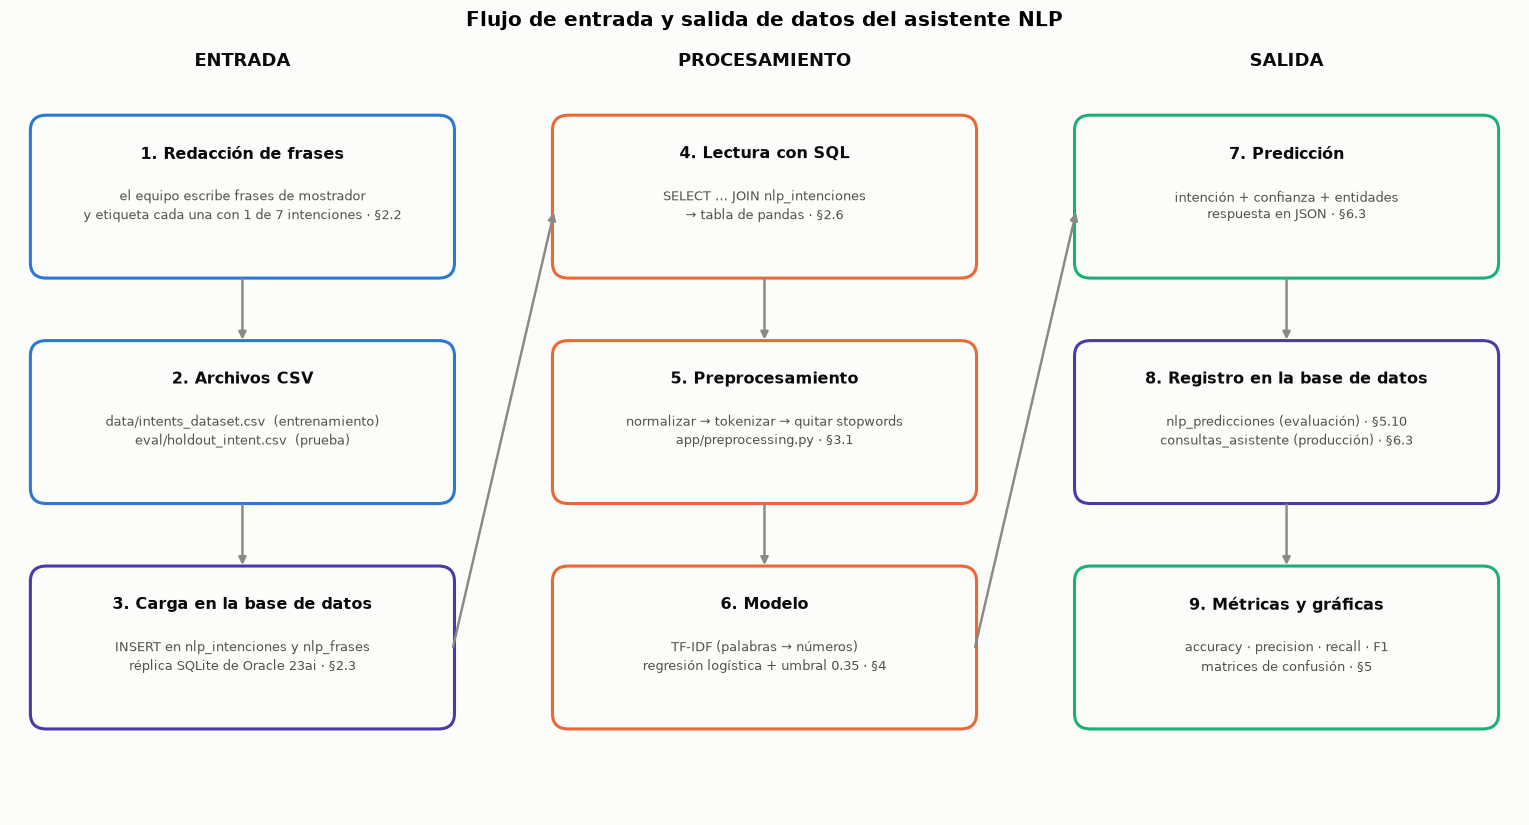

In [4]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 7.6))
ax.set_xlim(0, 14); ax.set_ylim(0, 7.6); ax.axis("off")

def caja_flujo(x, y, titulo, detalle, color, w=3.9, h=1.55):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                facecolor="#fcfcfb", edgecolor=color, linewidth=2))
    ax.text(x + w / 2, y + h - 0.28, titulo, ha="center", va="top", fontsize=10.5, fontweight="bold", color="#0b0b0b")
    ax.text(x + w / 2, y + h - 0.68, detalle, ha="center", va="top", fontsize=8.5, color="#52514e", linespacing=1.45)

def flecha_flujo(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color=GRIS, lw=1.6))

COLUMNAS = [(0.2, "ENTRADA", AZUL), (5.05, "PROCESAMIENTO", NARANJA), (9.9, "SALIDA", AQUA)]
FILAS_Y = [5.25, 3.05, 0.85]
PASOS = [
    [("1. Redacción de frases", "el equipo escribe frases de mostrador\ny etiqueta cada una con 1 de 7 intenciones · §2.2"),
     ("2. Archivos CSV", "data/intents_dataset.csv  (entrenamiento)\neval/holdout_intent.csv  (prueba)"),
     ("3. Carga en la base de datos", "INSERT en nlp_intenciones y nlp_frases\nréplica SQLite de Oracle 23ai · §2.3")],
    [("4. Lectura con SQL", "SELECT … JOIN nlp_intenciones\n→ tabla de pandas · §2.6"),
     ("5. Preprocesamiento", "normalizar → tokenizar → quitar stopwords\napp/preprocessing.py · §3.1"),
     ("6. Modelo", "TF-IDF (palabras → números)\nregresión logística + umbral 0.35 · §4")],
    [("7. Predicción", "intención + confianza + entidades\nrespuesta en JSON · §6.3"),
     ("8. Registro en la base de datos", "nlp_predicciones (evaluación) · §5.10\nconsultas_asistente (producción) · §6.3"),
     ("9. Métricas y gráficas", "accuracy · precision · recall · F1\nmatrices de confusión · §5")],
]
for (x, nombre, color), pasos in zip(COLUMNAS, PASOS):
    ax.text(x + 1.95, 7.3, nombre, ha="center", fontsize=11.5, fontweight="bold", color="#0b0b0b")
    for y, (titulo, detalle) in zip(FILAS_Y, pasos):
        caja_flujo(x, y, titulo, detalle, VIOLETA if "base de datos" in titulo else color)
    for y_arriba, y_abajo in zip(FILAS_Y[:-1], FILAS_Y[1:]):
        flecha_flujo(x + 1.95, y_arriba, x + 1.95, y_abajo + 1.55)
flecha_flujo(4.1, 1.6, 5.05, 5.9)     # base de datos -> lectura con SQL
flecha_flujo(8.95, 1.6, 9.9, 5.9)     # modelo -> predicción
ax.set_title("Flujo de entrada y salida de datos del asistente NLP", fontsize=13)
plt.tight_layout(); plt.show()

### 2.2 Construcción del dataset

**Cómo se construyó.** No existía un registro de consultas reales de vendedores, así que el dataset se **redactó a mano** a partir del caso de uso: un vendedor que atiende a un cliente en el mostrador. El proceso fue:

1. **Definir las intenciones** (las etiquetas): seis acciones que el vendedor le pide al asistente, más la clase `fuera_de_dominio` para lo que no tiene que ver con la tienda.
2. **Redactar frases variadas para cada intención**, con vocabulario de mostrador: marcas y modelos de vehículos (Toyota Hilux, Mazda 3, Chevrolet Spark…), códigos de repuesto (HP-1002, 90915-YZZD4), formas coloquiales («pa», «deme», «chao») y errores de tipeo («toyta»).
3. **Etiquetar cada frase** con su intención en la columna `intencion`.
4. **Equilibrar las clases** (entre 50 y 56 frases cada una) para que ninguna domine el entrenamiento.
5. **Separar un conjunto de prueba** (`eval/holdout_intent.csv`, 4 frases por intención) que nunca se usa para entrenar.
6. **Ampliar el dataset** en una segunda versión con más frases por clase (ver en §3.3 el efecto que esto tuvo sobre el holdout).

**Diccionario de datos** del archivo `data/intents_dataset.csv` (UTF-8, separado por comas):

| Columna | Tipo | Descripción | Ejemplo |
|---|---|---|---|
| `texto` | texto libre | La frase tal como la escribiría el vendedor | ¿Cuánto vale la batería Mac 48D? |
| `intencion` | categórica (7 valores) | Lo que el vendedor quiere hacer | `consultar_precio` |

La tabla siguiente describe las 7 intenciones. La celda de después muestra cómo creció el dataset entre versiones, según el historial de `git`.

In [5]:
df_csv = pd.read_csv(DATASET_PATH)
ho_csv = pd.read_csv(HOLDOUT_INTENT_PATH)

INTENCIONES = {   # nombre: (qué pide el vendedor, cómo responde el asistente según app/pipeline.py)
    "buscar_repuesto":          ("Encontrar un repuesto para un vehículo", "consulta el catálogo"),
    "consultar_precio":         ("Saber cuánto cuesta un repuesto", "consulta el catálogo"),
    "consultar_stock":          ("Saber cuántas unidades quedan", "consulta el catálogo"),
    "consultar_compatibilidad": ("Saber si un repuesto le sirve a un vehículo", "consulta el catálogo"),
    "recomendar_sustituto":     ("Pedir una alternativa a un repuesto agotado (función central)", "consulta el catálogo"),
    "saludo_despedida":         ("Saludar, agradecer o despedirse", "respuesta fija"),
    "fuera_de_dominio":         ("Cualquier cosa ajena a la tienda", "respuesta fija"),
}
assert set(INTENCIONES) == set(df_csv["intencion"]) == set(ho_csv["intencion"])

tabla_intenciones = pd.DataFrame([
    {"intención": k, "qué pide el vendedor": d, "respuesta del asistente": r,
     "frases de entrenamiento": int((df_csv["intencion"] == k).sum()),
     "frases de holdout": int((ho_csv["intencion"] == k).sum()),
     "ejemplo del dataset": df_csv.loc[df_csv["intencion"] == k, "texto"].iloc[0]}
    for k, (d, r) in INTENCIONES.items()]).set_index("intención")
pd.set_option("display.max_colwidth", 90)
display(tabla_intenciones)
print(f"Total: {len(df_csv)} frases de entrenamiento + {len(ho_csv)} de holdout = {len(df_csv) + len(ho_csv)} frases")

listado = RAIZ / "data" / "frases_por_categoria.txt"
if listado.exists():
    conteo_txt = {m.group(1).lower(): int(m.group(2)) for m in
                  re.finditer(r"^([A-Z_]+)\s+\((\d+) frases\)", listado.read_text(encoding="utf-8"), re.M)}
    print(f"data/frases_por_categoria.txt (el mismo dataset agrupado por intención, para revisarlo a mano): "
          f"{sum(conteo_txt.values())} frases; coincide con el CSV: {conteo_txt == df_csv['intencion'].value_counts().to_dict()}")

,qué pide el vendedor,respuesta del asistente,frases de entrenamiento,frases de holdout,ejemplo del dataset
intención,,,,,
buscar_repuesto,Encontrar un repuesto para un vehículo,consulta el catálogo,56,4,¿Tienen filtro de aceite para Toyota Hilux 2.7 2024?
consultar_precio,Saber cuánto cuesta un repuesto,consulta el catálogo,56,4,¿Cuánto cuesta el filtro de aceite original de Toyota?
consultar_stock,Saber cuántas unidades quedan,consulta el catálogo,56,4,¿Cuántas unidades hay del filtro 90915-YZZD4?
consultar_compatibilidad,Saber si un repuesto le sirve a un vehículo,consulta el catálogo,50,4,¿Este filtro le sirve a una Hilux 2.7 gasolina 2024?
recomendar_sustituto,Pedir una alternativa a un repuesto agotado (función central),consulta el catálogo,56,4,"No hay filtro de aceite original de Toyota para una Hilux 2.7 gasolina 2024, ¿qué me r..."
saludo_despedida,"Saludar, agradecer o despedirse",respuesta fija,50,4,Hola
fuera_de_dominio,Cualquier cosa ajena a la tienda,respuesta fija,50,4,¿Cuál es el clima hoy?


Total: 374 frases de entrenamiento + 28 de holdout = 402 frases
data/frases_por_categoria.txt (el mismo dataset agrupado por intención, para revisarlo a mano): 374 frases; coincide con el CSV: True


,2026-09-05 (9d6a3cc),2026-09-28 (98eac1b),actual (en disco)
intencion,,,
buscar_repuesto,12,56,56
consultar_precio,7,56,56
consultar_stock,8,56,56
consultar_compatibilidad,7,50,50
recomendar_sustituto,14,56,56
saludo_despedida,10,50,50
fuera_de_dominio,7,50,50
TOTAL,65,374,374


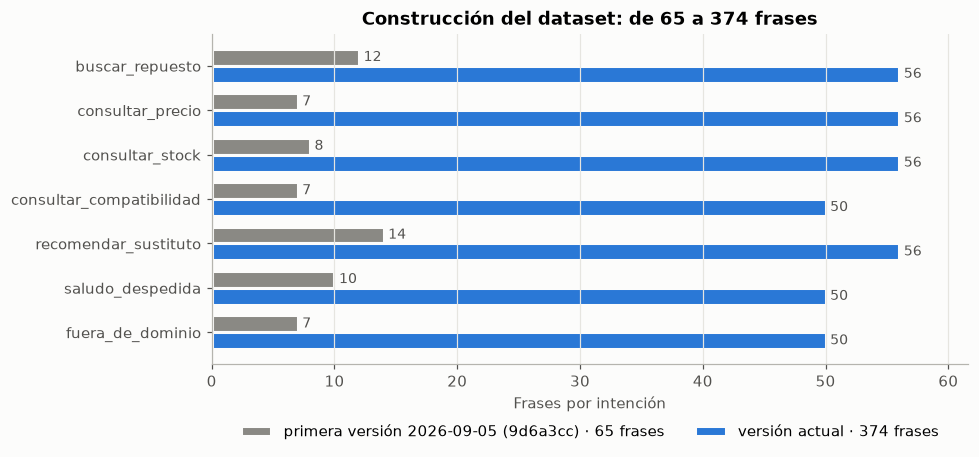

In [6]:
# Evolución del dataset según el historial de git
from io import StringIO

def csv_en_commit(commit, ruta="nlp-service/data/intents_dataset.csv"):
    salida = subprocess.run(["git", "show", f"{commit}:{ruta}"], cwd=RAIZ, capture_output=True, text=True, encoding="utf-8")
    return pd.read_csv(StringIO(salida.stdout)) if salida.returncode == 0 else None

versiones = subprocess.run(["git", "log", "--reverse", "--format=%h|%ad", "--date=short", "--", "data/intents_dataset.csv"],
                           cwd=RAIZ, capture_output=True, text=True, encoding="utf-8").stdout.split()
evolucion = {}
for v in versiones:
    commit, fecha = v.split("|")
    d = csv_en_commit(commit)
    if d is not None:
        evolucion[f"{fecha} ({commit})"] = d["intencion"].value_counts()
evolucion["actual (en disco)"] = df_csv["intencion"].value_counts()
evolucion = pd.DataFrame(evolucion).fillna(0).astype(int).loc[list(INTENCIONES)]
evolucion.loc["TOTAL"] = evolucion.sum()
display(evolucion)

primera, ultima = evolucion.columns[0], evolucion.columns[-1]
datos = evolucion.drop("TOTAL")
fig, ax = plt.subplots(figsize=(9, 4.3))
yy, alto = np.arange(len(datos)), 0.38
b1 = ax.barh(yy - alto / 2, datos[primera], height=alto, color=GRIS, edgecolor="#fcfcfb", linewidth=2,
             label=f"primera versión {primera} · {evolucion.loc['TOTAL', primera]} frases")
b2 = ax.barh(yy + alto / 2, datos[ultima], height=alto, color=AZUL, edgecolor="#fcfcfb", linewidth=2,
             label=f"versión actual · {evolucion.loc['TOTAL', ultima]} frases")
ax.bar_label(b1, padding=3, color="#52514e", fontsize=9); ax.bar_label(b2, padding=3, color="#52514e", fontsize=9)
ax.set_yticks(yy, datos.index); ax.invert_yaxis()
ax.set_xlabel("Frases por intención")
ax.set_title(f"Construcción del dataset: de {evolucion.loc['TOTAL', primera]} a {evolucion.loc['TOTAL', ultima]} frases")
ax.set_xlim(0, datos.values.max() * 1.1)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 2.3 Carga del dataset en la base de datos

La base de datos real de ElectriSys es **Oracle 23ai** (carpeta `oracle/`), que corre en Docker junto al backend. Para que el cuaderno se pueda ejecutar en cualquier equipo sin levantar Oracle, se construye una **réplica local en SQLite** con el mismo esquema y los mismos datos semilla:

1. Se leen los scripts reales `oracle/02_ddl_tablas.sql` (creación de tablas) y `oracle/05_seed.sql` (datos de prueba: categorías, proveedores, repuestos, vehículos y compatibilidades).
2. Se traducen las pocas diferencias de sintaxis entre Oracle y SQLite (columna identidad, `SYSTIMESTAMP`, `FROM dual`, tipo `JSON`) y se ejecutan sentencia por sentencia.
3. Se crean **tres tablas nuevas** para el asistente y se carga el dataset en ellas:
   - `nlp_intenciones`: catálogo de las 7 intenciones.
   - `nlp_frases`: las frases de entrenamiento y las del holdout, cada una con su intención y el conjunto al que pertenece.
   - `nlp_predicciones`: la **salida** del modelo evaluado (se llena en §5.10).
4. Se genera `notebooks/salida/12_dataset_nlp_oracle.sql`, el script equivalente para cargar el dataset en la base **Oracle real**, y se prueba ejecutándolo sobre una base vacía.

La base queda en `notebooks/salida/electrisys_nlp.sqlite` y se reconstruye desde cero en cada ejecución del cuaderno.

In [7]:
# Paso 1 y 2: réplica del esquema y de los datos semilla de Oracle
DB_PATH = SALIDA / "electrisys_nlp.sqlite"
DB_PATH.unlink(missing_ok=True)
con = sqlite3.connect(DB_PATH)
con.execute("PRAGMA foreign_keys = ON")

def oracle_a_sqlite(sql):
    # Traduce las diferencias de sintaxis que usan los scripts de oracle/
    sql = re.sub(r"--[^\n]*", "", sql)                                           # comentarios
    sql = re.sub(r"^\s*(SET|PROMPT|COMMIT)\b[^\n]*\n?", "", sql, flags=re.I | re.M)  # órdenes de SQL*Plus
    sql = re.sub(r"NUMBER\s+GENERATED BY DEFAULT ON NULL AS IDENTITY PRIMARY KEY",
                 "INTEGER PRIMARY KEY AUTOINCREMENT", sql)                        # columna identidad
    sql = re.sub(r"\bJSON\b", "TEXT", sql)                                        # tipo JSON nativo de Oracle
    sql = sql.replace("SYSTIMESTAMP", "CURRENT_TIMESTAMP")
    return re.sub(r"\s+FROM\s+dual\b", "", sql, flags=re.I)                       # tabla dual de Oracle

def sentencias(sql):
    # Separa un script en sentencias completas (respeta los ';' dentro de textos)
    buffer = ""
    for linea in sql.splitlines(keepends=True):
        buffer += linea
        if sqlite3.complete_statement(buffer):
            if buffer.strip():
                yield buffer.strip()
            buffer = ""

carga = []
for nombre in ["02_ddl_tablas.sql", "05_seed.sql"]:
    n = 0
    for s in sentencias(oracle_a_sqlite((ORACLE_DIR / nombre).read_text(encoding="utf-8"))):
        con.execute(s); n += 1
    carga.append({"script": f"oracle/{nombre}", "sentencias ejecutadas": n})
con.commit()
display(pd.DataFrame(carga).set_index("script"))

,sentencias ejecutadas
script,
oracle/02_ddl_tablas.sql,18
oracle/05_seed.sql,109


In [8]:
# Paso 3: tablas nuevas del asistente y carga del dataset
DDL_NLP = """
CREATE TABLE nlp_intenciones (
    id          INTEGER PRIMARY KEY AUTOINCREMENT,
    nombre      VARCHAR2(50)  NOT NULL UNIQUE,
    descripcion VARCHAR2(200) NOT NULL,
    respuesta   VARCHAR2(30)  NOT NULL
);
CREATE TABLE nlp_frases (
    id           INTEGER PRIMARY KEY AUTOINCREMENT,
    texto        VARCHAR2(1000) NOT NULL,
    intencion_id INTEGER NOT NULL REFERENCES nlp_intenciones(id),
    conjunto     VARCHAR2(15)  NOT NULL CHECK (conjunto IN ('entrenamiento', 'holdout')),
    n_caracteres INTEGER NOT NULL,
    n_palabras   INTEGER NOT NULL,
    fuente       VARCHAR2(100) NOT NULL,
    creado_en    TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);
CREATE INDEX idx_nlp_frases_intencion ON nlp_frases(intencion_id);
CREATE TABLE nlp_predicciones (
    id             INTEGER PRIMARY KEY AUTOINCREMENT,
    frase_id       INTEGER NOT NULL REFERENCES nlp_frases(id),
    metodo         VARCHAR2(30)  NOT NULL CHECK (metodo IN ('validacion_cruzada', 'holdout')),
    intencion_pred VARCHAR2(50)  NOT NULL,
    confianza      NUMBER(5,4)   NOT NULL,
    correcta       NUMBER(1)     NOT NULL,
    modelo         VARCHAR2(100) NOT NULL,
    creado_en      TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);
"""
con.executescript(DDL_NLP)

con.executemany("INSERT INTO nlp_intenciones (nombre, descripcion, respuesta) VALUES (?, ?, ?)",
                [(k, d, r) for k, (d, r) in INTENCIONES.items()])
id_intencion = dict(con.execute("SELECT nombre, id FROM nlp_intenciones"))

filas = []
for datos, conjunto, fuente in [(df_csv, "entrenamiento", "data/intents_dataset.csv"),
                                (ho_csv, "holdout", "eval/holdout_intent.csv")]:
    filas += [(t, id_intencion[i], conjunto, len(t), len(t.split()), fuente)
              for t, i in zip(datos["texto"], datos["intencion"])]
con.executemany("INSERT INTO nlp_frases (texto, intencion_id, conjunto, n_caracteres, n_palabras, fuente) "
                "VALUES (?, ?, ?, ?, ?, ?)", filas)
con.commit()
print(f"INSERT en nlp_intenciones: {len(INTENCIONES)} filas")
print(f"INSERT en nlp_frases:      {len(filas)} filas ({len(df_csv)} de entrenamiento + {len(ho_csv)} de holdout)")

INSERT en nlp_intenciones: 7 filas
INSERT en nlp_frases:      402 filas (374 de entrenamiento + 28 de holdout)


In [9]:
# Verificación de la carga: conteo por intención y comparación fila por fila con los CSV
verif = pd.read_sql_query("""
    SELECT i.nombre AS intencion,
           SUM(CASE WHEN f.conjunto = 'entrenamiento' THEN 1 ELSE 0 END) AS entrenamiento,
           SUM(CASE WHEN f.conjunto = 'holdout'       THEN 1 ELSE 0 END) AS holdout,
           COUNT(*) AS total
    FROM nlp_frases f JOIN nlp_intenciones i ON i.id = f.intencion_id
    GROUP BY i.nombre ORDER BY total DESC, i.nombre""", con)
display(verif.set_index("intencion"))

def frases_desde_bd(conjunto):
    return pd.read_sql_query("""
        SELECT f.texto, i.nombre AS intencion
        FROM nlp_frases f JOIN nlp_intenciones i ON i.id = f.intencion_id
        WHERE f.conjunto = ? ORDER BY f.id""", con, params=(conjunto,))

print("¿Entrenamiento en la base == data/intents_dataset.csv, fila por fila?", frases_desde_bd("entrenamiento").equals(df_csv))
print("¿Holdout en la base == eval/holdout_intent.csv, fila por fila?      ", frases_desde_bd("holdout").equals(ho_csv))
print("\nMuestra de la tabla nlp_frases:")
display(pd.read_sql_query("SELECT * FROM nlp_frases WHERE id IN (1, 120, 240, 374, 375, 402)", con).set_index("id"))

,entrenamiento,holdout,total
intencion,,,
buscar_repuesto,56,4,60
consultar_precio,56,4,60
consultar_stock,56,4,60
recomendar_sustituto,56,4,60
consultar_compatibilidad,50,4,54
fuera_de_dominio,50,4,54
saludo_despedida,50,4,54


¿Entrenamiento en la base == data/intents_dataset.csv, fila por fila? True
¿Holdout en la base == eval/holdout_intent.csv, fila por fila?       True

Muestra de la tabla nlp_frases:


,texto,intencion_id,conjunto,n_caracteres,n_palabras,fuente,creado_en
id,,,,,,,
1,"No hay filtro de aceite original de Toyota para una Hilux 2.7 gasolina 2024, ¿qué me r...",5,entrenamiento,96,17,data/intents_dataset.csv,2026-09-29 22:49:00
120,¿Tienen baño para clientes?,7,entrenamiento,27,4,data/intents_dataset.csv,2026-09-29 22:49:00
240,Necesito una bomba de agua para Nissan Frontier,1,entrenamiento,47,8,data/intents_dataset.csv,2026-09-29 22:49:00
374,¿y cuántas unidades del otro código?,3,entrenamiento,36,6,data/intents_dataset.csv,2026-09-29 22:49:00
375,"Ya no me queda el disco de embrague Sachs para un Renault Duster, deme otra opción",5,holdout,82,16,eval/holdout_intent.csv,2026-09-29 22:49:00
402,¿Cuál es tu color favorito?,7,holdout,27,5,eval/holdout_intent.csv,2026-09-29 22:49:00


In [10]:
# Paso 4: script para cargar el dataset en la base Oracle real
def literal(s):
    return "'" + str(s).replace("'", "''") + "'"

DDL_NLP_ORACLE = """
CREATE TABLE nlp_intenciones (
    id          NUMBER GENERATED BY DEFAULT ON NULL AS IDENTITY PRIMARY KEY,
    nombre      VARCHAR2(50)  NOT NULL,
    descripcion VARCHAR2(200) NOT NULL,
    respuesta   VARCHAR2(30)  NOT NULL,
    CONSTRAINT uq_nlp_intenciones_nombre UNIQUE (nombre)
);

CREATE TABLE nlp_frases (
    id           NUMBER GENERATED BY DEFAULT ON NULL AS IDENTITY PRIMARY KEY,
    texto        VARCHAR2(1000) NOT NULL,
    intencion_id NUMBER NOT NULL,
    conjunto     VARCHAR2(15)  NOT NULL,
    n_caracteres NUMBER(4)     NOT NULL,
    n_palabras   NUMBER(3)     NOT NULL,
    fuente       VARCHAR2(100) NOT NULL,
    creado_en    TIMESTAMP DEFAULT SYSTIMESTAMP,
    CONSTRAINT fk_nlp_frases_intencion FOREIGN KEY (intencion_id) REFERENCES nlp_intenciones(id),
    CONSTRAINT ck_nlp_frases_conjunto CHECK (conjunto IN ('entrenamiento', 'holdout'))
);

CREATE INDEX idx_nlp_frases_intencion ON nlp_frases(intencion_id);
"""
lineas_sql = [
    "-- ============================================================",
    "-- ElectriSys — Dataset del asistente NLP para Oracle 23ai",
    "-- Generado por nlp-service/notebooks/asistente_nlp.ipynb (§2.3).",
    f"-- {len(df_csv)} frases de entrenamiento + {len(ho_csv)} de holdout, 7 intenciones.",
    "-- Ejecutar conectado como ELECTRISYS, después de 02_ddl_tablas.sql.",
    "-- El archivo está en UTF-8: usar NLS_LANG=.AL32UTF8 al correr sqlplus.",
    "-- ============================================================",
    "SET DEFINE OFF;", "", DDL_NLP_ORACLE.strip(), ""]
lineas_sql += [f"INSERT INTO nlp_intenciones (nombre, descripcion, respuesta) VALUES "
               f"({literal(k)}, {literal(d)}, {literal(r)});" for k, (d, r) in INTENCIONES.items()]
lineas_sql.append("")
for texto, intencion, conjunto, n_car, n_pal, fuente in con.execute("""
        SELECT f.texto, i.nombre, f.conjunto, f.n_caracteres, f.n_palabras, f.fuente
        FROM nlp_frases f JOIN nlp_intenciones i ON i.id = f.intencion_id ORDER BY f.id"""):
    lineas_sql.append("INSERT INTO nlp_frases (texto, intencion_id, conjunto, n_caracteres, n_palabras, fuente) "
                      f"SELECT {literal(texto)}, id, {literal(conjunto)}, {n_car}, {n_pal}, {literal(fuente)} "
                      f"FROM nlp_intenciones WHERE nombre = {literal(intencion)};")
lineas_sql += ["", "COMMIT;"]
SCRIPT_ORACLE = SALIDA / "12_dataset_nlp_oracle.sql"
SCRIPT_ORACLE.write_text("\n".join(lineas_sql) + "\n", encoding="utf-8")

# Prueba: el script generado se traduce con la misma función y se ejecuta sobre una base vacía
prueba = sqlite3.connect(":memory:")
for s in sentencias(oracle_a_sqlite(SCRIPT_ORACLE.read_text(encoding="utf-8"))):
    prueba.execute(s)
n_prueba = prueba.execute("SELECT COUNT(*) FROM nlp_frases").fetchone()[0]
prueba.close()
print(f"Script generado: notebooks/salida/{SCRIPT_ORACLE.name} ({len(lineas_sql)} líneas, "
      f"{SCRIPT_ORACLE.stat().st_size / 1024:.0f} KB)")
print(f"Prueba sobre una base vacía: {n_prueba} frases cargadas sin errores")
print("\nCómo cargarlo en Oracle (desde la carpeta notebooks/salida):")
print('  sqlplus electrisys/<contraseña>@//localhost:1521/<PDB> @12_dataset_nlp_oracle.sql')
print("\nExtracto del script:")
print("\n".join(l for l in lineas_sql if l.startswith("INSERT"))[:600] + " …")

Script generado: notebooks/salida/12_dataset_nlp_oracle.sql (423 líneas, 105 KB)
Prueba sobre una base vacía: 402 frases cargadas sin errores

Cómo cargarlo en Oracle (desde la carpeta notebooks/salida):
  sqlplus electrisys/<contraseña>@//localhost:1521/<PDB> @12_dataset_nlp_oracle.sql

Extracto del script:
INSERT INTO nlp_intenciones (nombre, descripcion, respuesta) VALUES ('buscar_repuesto', 'Encontrar un repuesto para un vehículo', 'consulta el catálogo');
INSERT INTO nlp_intenciones (nombre, descripcion, respuesta) VALUES ('consultar_precio', 'Saber cuánto cuesta un repuesto', 'consulta el catálogo');
INSERT INTO nlp_intenciones (nombre, descripcion, respuesta) VALUES ('consultar_stock', 'Saber cuántas unidades quedan', 'consulta el catálogo');
INSERT INTO nlp_intenciones (nombre, descripcion, respuesta) VALUES ('consultar_compatibilidad', 'Saber si un repuesto le sirve a un vehículo', 'consu …


### 2.4 Descripción detallada de la base de datos

La base tiene tres grupos de tablas:

- **Punto de venta**: usuarios, clientes, ventas, cotizaciones y auditoría. El asistente no las usa, salvo `usuarios` (quién hizo la consulta).
- **Catálogo**: repuestos, categorías, proveedores, vehículos y la compatibilidad entre repuestos y vehículos. Es lo que el asistente **consulta** para responder (a través del backend).
- **Asistente NLP**: `consultas_asistente`, donde el backend **registra** cada consulta en producción, y las tres tablas nuevas del dataset creadas en §2.3.

La primera tabla lista todas, con su número de columnas y de filas en la réplica. La segunda detalla las columnas de las tablas que usa el asistente. En Oracle, las columnas `id` son `NUMBER` con identidad y las columnas `*_json` son de tipo `JSON`; en la réplica aparecen como `INTEGER` y `TEXT`.

In [11]:
DESCRIPCION_TABLAS = {   # tabla: (grupo, para qué sirve)
    "roles": ("punto de venta", "Roles de negocio: admin, vendedor, dueño"),
    "usuarios": ("punto de venta", "Usuarios del sistema (vendedores y administradores)"),
    "proveedores": ("catálogo", "Proveedores de los repuestos"),
    "categorias": ("catálogo", "Categorías de repuestos (Filtros, Frenos, Baterías…)"),
    "repuestos": ("catálogo", "Productos: código, precios, stock y stock mínimo"),
    "clientes": ("punto de venta", "Clientes de la tienda"),
    "ventas": ("punto de venta", "Encabezado de cada venta"),
    "detalle_ventas": ("punto de venta", "Productos de cada venta"),
    "cotizaciones": ("punto de venta", "Encabezado de cada cotización"),
    "detalle_cotizaciones": ("punto de venta", "Productos de cada cotización"),
    "vehiculos": ("catálogo", "Autos y maquinaria agrícola: marca, modelo, años, motor, combustible"),
    "repuesto_compatibilidad": ("catálogo", "Qué repuesto le sirve a qué vehículo (relación N:N)"),
    "consultas_asistente": ("asistente NLP", "Registro de cada consulta al asistente en producción"),
    "audit_log": ("punto de venta", "Auditoría de acciones de los usuarios"),
    "login_attempts": ("punto de venta", "Intentos de inicio de sesión (límite de intentos)"),
    "nlp_intenciones": ("asistente NLP (nueva)", "Catálogo de las 7 intenciones"),
    "nlp_frases": ("asistente NLP (nueva)", "Dataset: frases de entrenamiento y de holdout"),
    "nlp_predicciones": ("asistente NLP (nueva)", "Predicciones del modelo evaluado (§5.10)"),
}
tablas = [t for (t,) in con.execute("SELECT name FROM sqlite_master WHERE type = 'table' "
                                    "AND name NOT LIKE 'sqlite_%' ORDER BY rowid")]
inventario = pd.DataFrame([
    {"tabla": t, "grupo": DESCRIPCION_TABLAS.get(t, ("otro", ""))[0],
     "para qué sirve": DESCRIPCION_TABLAS.get(t, ("", "—"))[1],
     "columnas": len(con.execute(f"PRAGMA table_info({t})").fetchall()),
     "filas": con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]}
    for t in tablas]).set_index("tabla").sort_values(["grupo", "filas"], ascending=[True, False])
display(inventario)
print(f"{len(tablas)} tablas y {inventario['filas'].sum()} filas en total en la réplica.")

,grupo,para qué sirve,columnas,filas
tabla,,,,
consultas_asistente,asistente NLP,Registro de cada consulta al asistente en producción,8,0
nlp_frases,asistente NLP (nueva),Dataset: frases de entrenamiento y de holdout,8,402
nlp_intenciones,asistente NLP (nueva),Catálogo de las 7 intenciones,4,7
nlp_predicciones,asistente NLP (nueva),Predicciones del modelo evaluado (§5.10),8,0
repuesto_compatibilidad,catálogo,Qué repuesto le sirve a qué vehículo (relación N:N),4,42
vehiculos,catálogo,"Autos y maquinaria agrícola: marca, modelo, años, motor, combustible",8,27
repuestos,catálogo,"Productos: código, precios, stock y stock mínimo",14,23
proveedores,catálogo,Proveedores de los repuestos,10,13
categorias,catálogo,"Categorías de repuestos (Filtros, Frenos, Baterías…)",3,12


18 tablas y 543 filas en total en la réplica.


In [12]:
# Diccionario de datos de las tablas que usa el asistente
TABLAS_ASISTENTE = ["categorias", "repuestos", "vehiculos", "repuesto_compatibilidad",
                    "consultas_asistente", "nlp_intenciones", "nlp_frases", "nlp_predicciones"]
filas = []
for t in TABLAS_ASISTENTE:
    fks = {r[3]: f"{r[2]}.{r[4]}" for r in con.execute(f"PRAGMA foreign_key_list({t})")}
    for _, nombre, tipo, notnull, defecto, pk in con.execute(f"PRAGMA table_info({t})"):
        filas.append({"tabla": t, "columna": nombre, "tipo": tipo,
                      "obligatoria": "sí" if (notnull or pk) else "no",
                      "clave": "PK" if pk else (f"FK → {fks[nombre]}" if nombre in fks else ""),
                      "valor por defecto": defecto or ""})
pd.set_option("display.max_rows", 150)
display(pd.DataFrame(filas).set_index(["tabla", "columna"]))

tipo obligatoria  \
tabla                   columna                                           
categorias              id                          INTEGER          sí   
                        nombre                VARCHAR2(100)          sí   
                        creado_en                 TIMESTAMP          no   
repuestos               id                          INTEGER          sí   
                        codigo                 VARCHAR2(50)          no   
                        nombre                VARCHAR2(200)          sí   
                        descripcion          VARCHAR2(4000)          no   
                        categoria_id                 NUMBER          no   
                        proveedor_id                 NUMBER          no   
                        precio_compra          NUMBER(12,2)          sí   
                        precio_venta           NUMBER(12,2)          sí   
                        stock                    NUMBER(10)          sí   
                        stock_minimo             NUMBER(10)          sí   
                        activo                    NUMBER(1)          no   
                        creado_en                 TIMESTAMP          no   
                        updated_at                TIMESTAMP          no   
                        deleted_at                TIMESTAMP          no   
vehiculos               id                          INTEGER          sí   
                        marca                  VARCHAR2(80)          sí   
                        modelo                 VARCHAR2(80)          sí   
                        anio_desde                NUMBER(4)          sí   
                        anio_hasta                NUMBER(4)          sí   
                        motor                  VARCHAR2(50)          no   
                        combustible            VARCHAR2(20)          sí   
                        creado_en                 TIMESTAMP          no   
repuesto_compatibilidad id                          INTEGER          sí   
                        repuesto_id                  NUMBER          sí   
                        vehiculo_id                  NUMBER          sí   
                        creado_en                 TIMESTAMP          no   
consultas_asistente     id                          INTEGER          sí   
                        usuario_id                   NUMBER          no   
                        texto_consulta       VARCHAR2(4000)          sí   
                        intencion_detectada    VARCHAR2(50)          no   
                        entidades_json                 TEXT          no   
                        respuesta_json                 TEXT          no   
                        util                      NUMBER(1)          no   
                        creado_en                 TIMESTAMP          no   
nlp_intenciones         id                          INTEGER          sí   
                        nombre                 VARCHAR2(50)          sí   
                        descripcion           VARCHAR2(200)          sí   
                        respuesta              VARCHAR2(30)          sí   
nlp_frases              id                          INTEGER          sí   
                        texto                VARCHAR2(1000)          sí   
                        intencion_id                INTEGER          sí   
                        conjunto               VARCHAR2(15)          sí   
                        n_caracteres                INTEGER          sí   
                        n_palabras                  INTEGER          sí   
                        fuente                VARCHAR2(100)          sí   
                        creado_en                 TIMESTAMP          no   
nlp_predicciones        id                          INTEGER          sí   
                        frase_id                    INTEGER          sí   
                        metodo                 VARCHAR2(30)          sí   
     

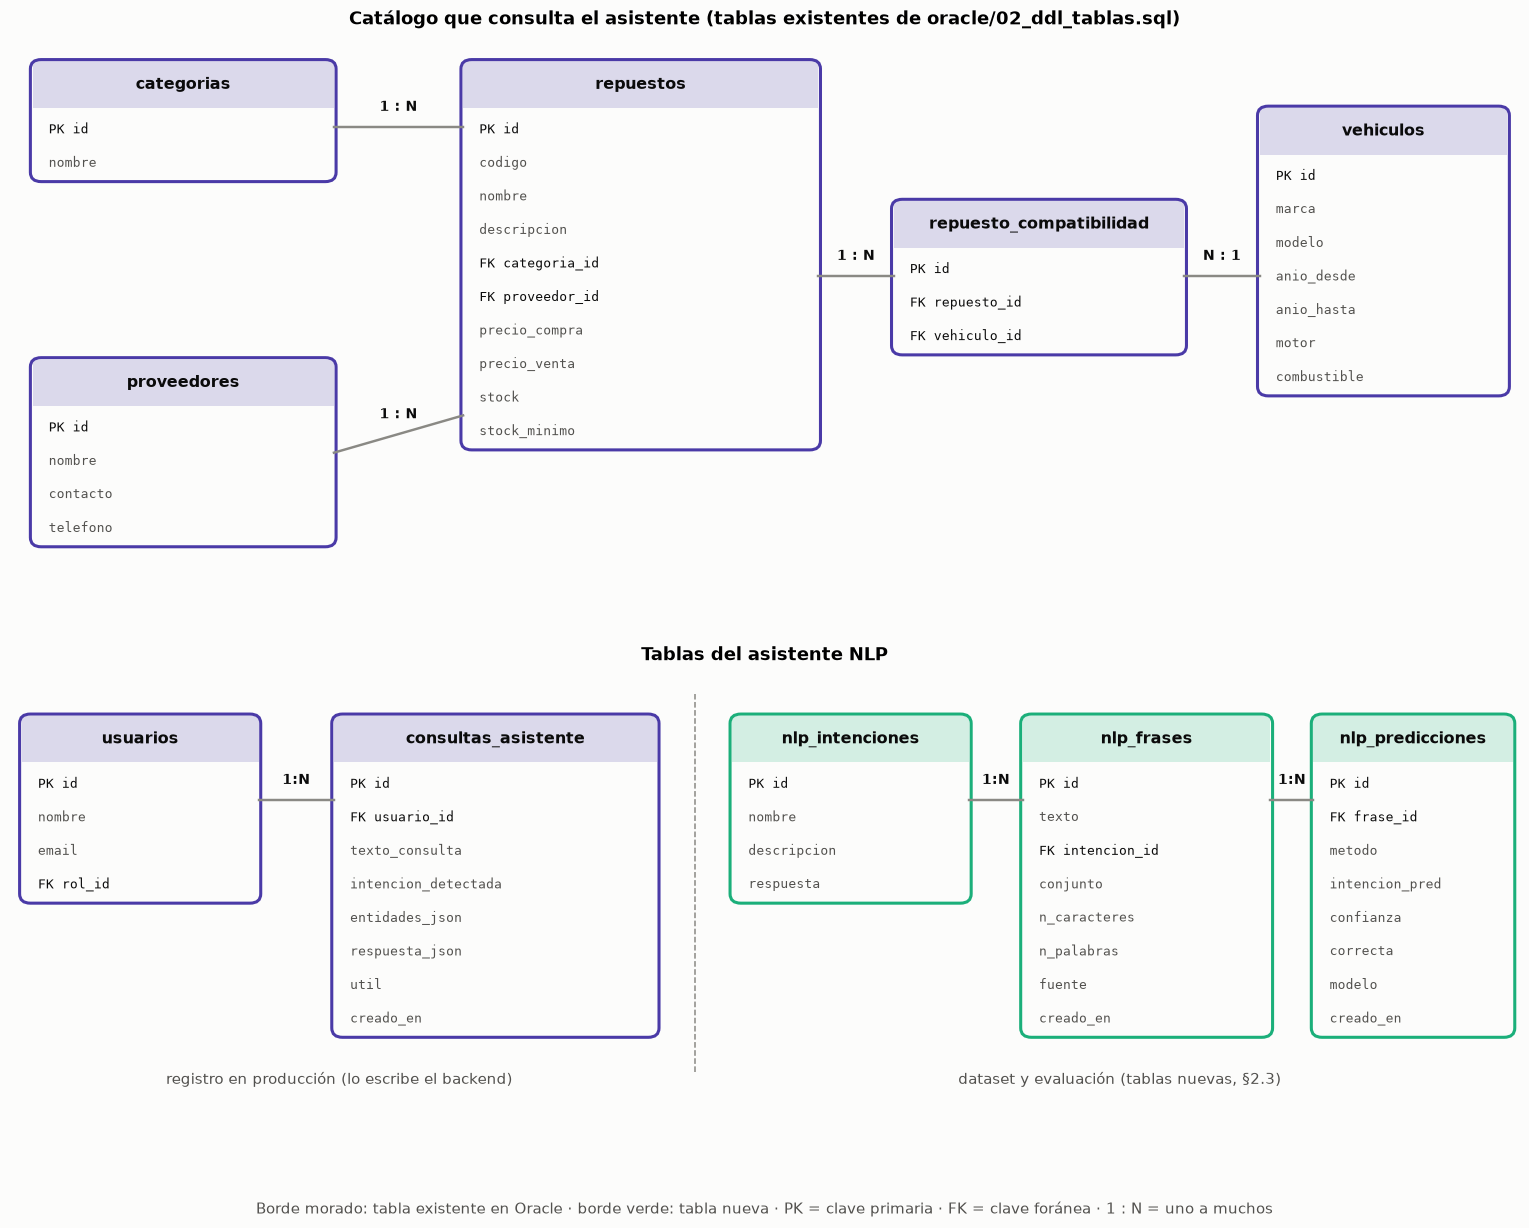

In [13]:
# Diagrama entidad-relación de las tablas que usa el asistente
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 11.2), gridspec_kw={"height_ratios": [6.4, 5.4]})
for ax, alto in [(ax1, 6.4), (ax2, 5.4)]:
    ax.set_xlim(0, 14); ax.set_ylim(0, alto); ax.axis("off")

def tabla_er(ax, x, y_top, w, nombre, columnas, color):
    fila = 0.36
    h = 0.55 + fila * len(columnas)
    ax.add_patch(FancyBboxPatch((x, y_top - h), w, h, boxstyle="round,pad=0.02,rounding_size=0.1",
                                facecolor="#fcfcfb", edgecolor=color, linewidth=2))
    ax.add_patch(plt.Rectangle((x, y_top - 0.5), w, 0.5, facecolor=color, edgecolor="none", alpha=0.18))
    ax.text(x + w / 2, y_top - 0.25, nombre, ha="center", va="center", fontsize=10.5, fontweight="bold", color="#0b0b0b")
    for k, col in enumerate(columnas):
        ax.text(x + 0.15, y_top - 0.55 - fila * (k + 0.5), col, va="center", fontsize=8.8, family="monospace",
                color="#0b0b0b" if col.startswith(("PK", "FK")) else "#52514e")

def relacion(ax, x1, y1, x2, y2, texto):
    ax.plot([x1, x2], [y1, y2], color=GRIS, lw=1.6)
    ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.17, texto, ha="center", fontsize=9, color="#0b0b0b", fontweight="bold")

EXISTENTE, NUEVA = VIOLETA, AQUA
tabla_er(ax1, 0.2, 6.1, 2.8, "categorias", ["PK id", "nombre"], EXISTENTE)
tabla_er(ax1, 0.2, 2.9, 2.8, "proveedores", ["PK id", "nombre", "contacto", "telefono"], EXISTENTE)
tabla_er(ax1, 4.2, 6.1, 3.3, "repuestos", ["PK id", "codigo", "nombre", "descripcion", "FK categoria_id",
                                           "FK proveedor_id", "precio_compra", "precio_venta", "stock", "stock_minimo"], EXISTENTE)
tabla_er(ax1, 8.2, 4.6, 2.7, "repuesto_compatibilidad", ["PK id", "FK repuesto_id", "FK vehiculo_id"], EXISTENTE)
tabla_er(ax1, 11.6, 5.6, 2.3, "vehiculos", ["PK id", "marca", "modelo", "anio_desde", "anio_hasta", "motor", "combustible"], EXISTENTE)
relacion(ax1, 3.0, 5.4, 4.2, 5.4, "1 : N")
relacion(ax1, 3.0, 1.9, 4.2, 2.3, "1 : N")
relacion(ax1, 7.5, 3.8, 8.2, 3.8, "1 : N")
relacion(ax1, 10.9, 3.8, 11.6, 3.8, "N : 1")
ax1.set_title("Catálogo que consulta el asistente (tablas existentes de oracle/02_ddl_tablas.sql)", fontsize=12)

tabla_er(ax2, 0.1, 4.9, 2.2, "usuarios", ["PK id", "nombre", "email", "FK rol_id"], EXISTENTE)
tabla_er(ax2, 3.0, 4.9, 3.0, "consultas_asistente", ["PK id", "FK usuario_id", "texto_consulta", "intencion_detectada",
                                                     "entidades_json", "respuesta_json", "util", "creado_en"], EXISTENTE)
tabla_er(ax2, 6.7, 4.9, 2.2, "nlp_intenciones", ["PK id", "nombre", "descripcion", "respuesta"], NUEVA)
tabla_er(ax2, 9.4, 4.9, 2.3, "nlp_frases", ["PK id", "texto", "FK intencion_id", "conjunto", "n_caracteres",
                                            "n_palabras", "fuente", "creado_en"], NUEVA)
tabla_er(ax2, 12.1, 4.9, 1.85, "nlp_predicciones", ["PK id", "FK frase_id", "metodo", "intencion_pred", "confianza",
                                                    "correcta", "modelo", "creado_en"], NUEVA)
relacion(ax2, 2.3, 4.0, 3.0, 4.0, "1:N")
relacion(ax2, 8.9, 4.0, 9.4, 4.0, "1:N")
relacion(ax2, 11.7, 4.0, 12.1, 4.0, "1:N")
ax2.axvline(6.35, ymin=0.2, ymax=0.95, color=GRIS, linestyle="--", linewidth=1)
ax2.text(3.05, 0.95, "registro en producción (lo escribe el backend)", ha="center", fontsize=9.5, color="#52514e")
ax2.text(10.3, 0.95, "dataset y evaluación (tablas nuevas, §2.3)", ha="center", fontsize=9.5, color="#52514e")
ax2.set_title("Tablas del asistente NLP", fontsize=12)
fig.text(0.5, 0.01, "Borde morado: tabla existente en Oracle · borde verde: tabla nueva · PK = clave primaria · "
         "FK = clave foránea · 1 : N = uno a muchos", ha="center", fontsize=9.5, color="#52514e")
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

**Cómo leer el diagrama**

- Una **categoría** tiene muchos repuestos y un **proveedor** surte muchos repuestos (relaciones 1 : N).
- Un repuesto le sirve a muchos vehículos y un vehículo acepta muchos repuestos. Esa relación muchos-a-muchos se resuelve con la tabla intermedia **`repuesto_compatibilidad`**. Es la que usa el asistente para saber qué sustituto le sirve al vehículo del cliente.
- Cada consulta que un vendedor hace al asistente en producción queda en **`consultas_asistente`**, ligada al usuario que la hizo. Es la **salida real** del sistema: el backend la escribe con el Observer `AsistenteLogObserver.php`.
- En el dataset, cada **frase** pertenece a una **intención** (la clave foránea impide etiquetas inventadas) y cada **predicción** apunta a la frase que se evaluó. El `CHECK` sobre `conjunto` solo admite `entrenamiento` u `holdout`.

### 2.5 Consultas SQL y gráficas sobre la base de datos

Cada gráfica sale de una consulta SQL ejecutada sobre la base; la consulta se imprime encima de la gráfica. La primera describe el dataset ya cargado y las demás describen el catálogo que el asistente consulta para responder.

SQL> SELECT i.nombre AS intencion, SUM(CASE WHEN f.conjunto = 'entrenamiento' THEN 1 ELSE 0 END) AS entrenamiento, SUM(CASE WHEN f.conjunto = 'holdout' THEN 1 ELSE 0 END) AS holdout FROM nlp_frases f JOIN nlp_intenciones i ON i.id = f.intencion_id GROUP BY i.nombre ORDER BY entrenamiento + holdout DESC, i.nombre


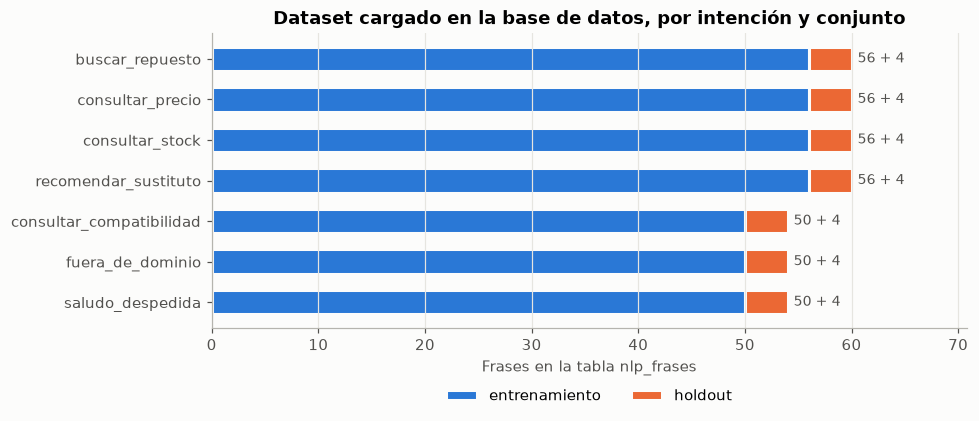

In [14]:
def consultar(sql_texto, params=()):
    print("SQL>", " ".join(sql_texto.split()))
    return pd.read_sql_query(sql_texto, con, params=params)

# Gráfica 1: el dataset en la base, por intención y conjunto
g1 = consultar("""
    SELECT i.nombre AS intencion,
           SUM(CASE WHEN f.conjunto = 'entrenamiento' THEN 1 ELSE 0 END) AS entrenamiento,
           SUM(CASE WHEN f.conjunto = 'holdout'       THEN 1 ELSE 0 END) AS holdout
    FROM nlp_frases f JOIN nlp_intenciones i ON i.id = f.intencion_id
    GROUP BY i.nombre ORDER BY entrenamiento + holdout DESC, i.nombre""")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(g1["intencion"], g1["entrenamiento"], color=AZUL, height=0.6, edgecolor="#fcfcfb", linewidth=2, label="entrenamiento")
b = ax.barh(g1["intencion"], g1["holdout"], left=g1["entrenamiento"], color=NARANJA, height=0.6,
            edgecolor="#fcfcfb", linewidth=2, label="holdout")
ax.bar_label(b, labels=[f"{e} + {h}" for e, h in zip(g1["entrenamiento"], g1["holdout"])], padding=4, color="#52514e", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, g1[["entrenamiento", "holdout"]].sum(axis=1).max() * 1.18)
ax.set_xlabel("Frases en la tabla nlp_frases")
ax.set_title("Dataset cargado en la base de datos, por intención y conjunto")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

SQL> SELECT c.nombre AS categoria, COUNT(r.id) AS repuestos, COALESCE(SUM(r.stock), 0) AS unidades FROM categorias c LEFT JOIN repuestos r ON r.categoria_id = c.id GROUP BY c.nombre ORDER BY repuestos DESC, unidades DESC


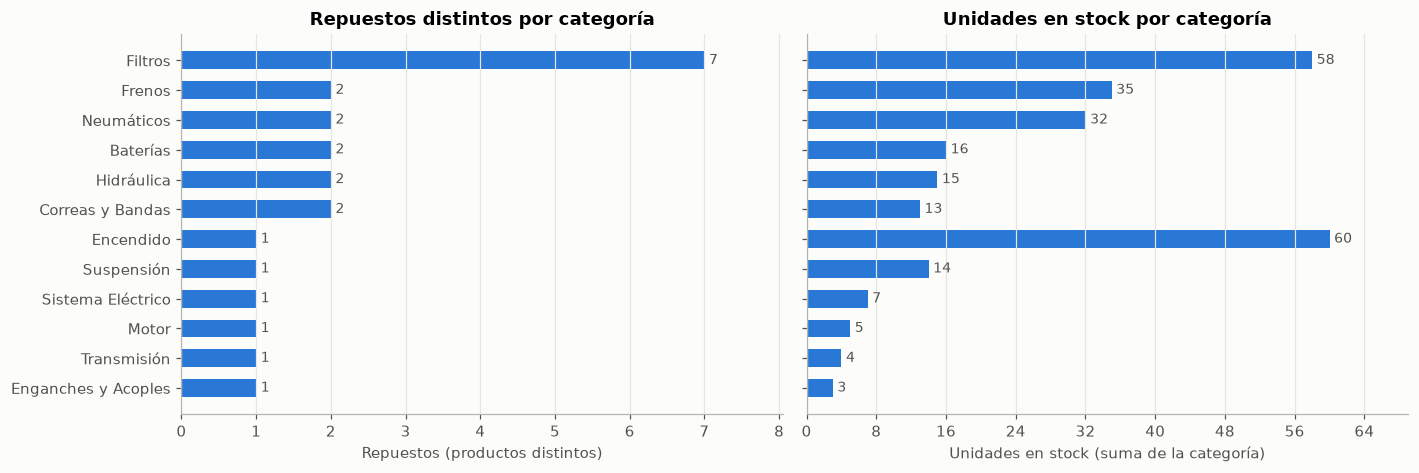

In [15]:
# Gráfica 2: repuestos y unidades en stock por categoría
g2 = consultar("""
    SELECT c.nombre AS categoria, COUNT(r.id) AS repuestos, COALESCE(SUM(r.stock), 0) AS unidades
    FROM categorias c LEFT JOIN repuestos r ON r.categoria_id = c.id
    GROUP BY c.nombre ORDER BY repuestos DESC, unidades DESC""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, col, titulo in [(a1, "repuestos", "Repuestos distintos por categoría"),
                        (a2, "unidades", "Unidades en stock por categoría")]:
    b = ax.barh(g2["categoria"], g2[col], color=AZUL, height=0.6)
    ax.bar_label(b, padding=3, color="#52514e", fontsize=9)
    ax.set_title(titulo); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
a1.set_xlabel("Repuestos (productos distintos)"); a2.set_xlabel("Unidades en stock (suma de la categoría)")
for ax, col in [(a1, "repuestos"), (a2, "unidades")]:
    ax.set_xlim(0, g2[col].max() * 1.15)
a1.invert_yaxis()
plt.tight_layout(); plt.show()

SQL> SELECT r.codigo, c.nombre AS categoria, r.stock, r.stock_minimo, CASE WHEN r.stock = 0 THEN 'agotado' WHEN r.stock < r.stock_minimo THEN 'bajo el mínimo' ELSE 'disponible' END AS estado FROM repuestos r JOIN categorias c ON c.id = r.categoria_id ORDER BY r.stock DESC, r.codigo


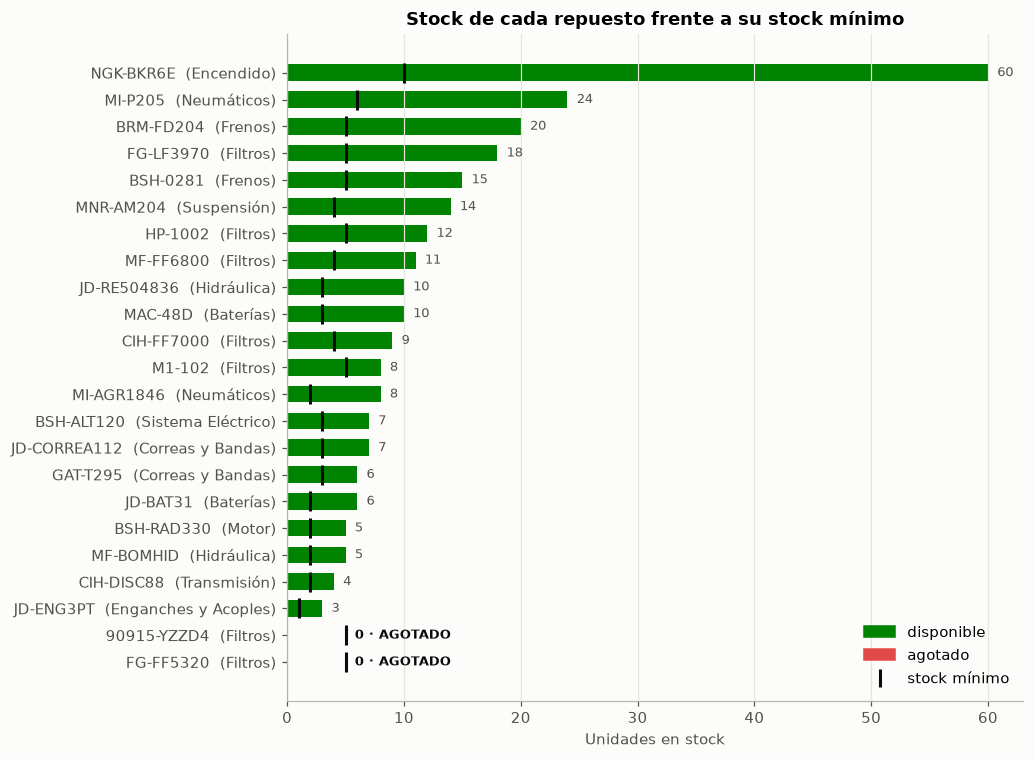

Repuestos agotados: ['90915-YZZD4', 'FG-FF5320'] -> son los casos en que el vendedor necesita recomendar_sustituto.
Repuestos bajo el mínimo (sin estar agotados): []


In [16]:
# Gráfica 3: stock actual frente al stock mínimo de cada repuesto
g3 = consultar("""
    SELECT r.codigo, c.nombre AS categoria, r.stock, r.stock_minimo,
           CASE WHEN r.stock = 0 THEN 'agotado'
                WHEN r.stock < r.stock_minimo THEN 'bajo el mínimo'
                ELSE 'disponible' END AS estado
    FROM repuestos r JOIN categorias c ON c.id = r.categoria_id
    ORDER BY r.stock DESC, r.codigo""")
COLOR_ESTADO = {"disponible": VERDE, "bajo el mínimo": AMARILLO, "agotado": ROJO}
fig, ax = plt.subplots(figsize=(9.5, 7))
etiquetas_y = [f"{c}  ({cat})" for c, cat in zip(g3["codigo"], g3["categoria"])]
ax.barh(etiquetas_y, g3["stock"], color=g3["estado"].map(COLOR_ESTADO), height=0.62)
ax.scatter(g3["stock_minimo"], etiquetas_y, marker="|", s=160, color="#0b0b0b", linewidths=2, zorder=3)
for yy, (stock, minimo, estado) in enumerate(zip(g3["stock"], g3["stock_minimo"], g3["estado"])):
    if estado == "agotado":
        ax.text(minimo + 0.8, yy, "0 · AGOTADO", va="center", fontsize=8.5, color="#0b0b0b", fontweight="bold")
    else:
        ax.text(max(stock, minimo) + 0.8, yy, str(stock), va="center", fontsize=8.5, color="#52514e")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
presentes = [e for e in COLOR_ESTADO if (g3["estado"] == e).any()]
ax.legend(handles=[Patch(color=COLOR_ESTADO[e], label=e) for e in presentes]
          + [Line2D([], [], marker="|", color="#0b0b0b", linestyle="none", markersize=12, markeredgewidth=2, label="stock mínimo")],
          frameon=False, loc="lower right")
ax.set_xlabel("Unidades en stock")
ax.set_title("Stock de cada repuesto frente a su stock mínimo")
plt.tight_layout(); plt.show()
agotados = g3.loc[g3["estado"] == "agotado", "codigo"].tolist()
print(f"Repuestos agotados: {agotados} -> son los casos en que el vendedor necesita recomendar_sustituto.")
print(f"Repuestos bajo el mínimo (sin estar agotados): {g3.loc[g3['estado'] == 'bajo el mínimo', 'codigo'].tolist()}")

SQL> SELECT r.codigo, c.nombre AS categoria, r.precio_compra, r.precio_venta, ROUND(100.0 * (r.precio_venta - r.precio_compra) / r.precio_venta, 1) AS margen_pct FROM repuestos r JOIN categorias c ON c.id = r.categoria_id


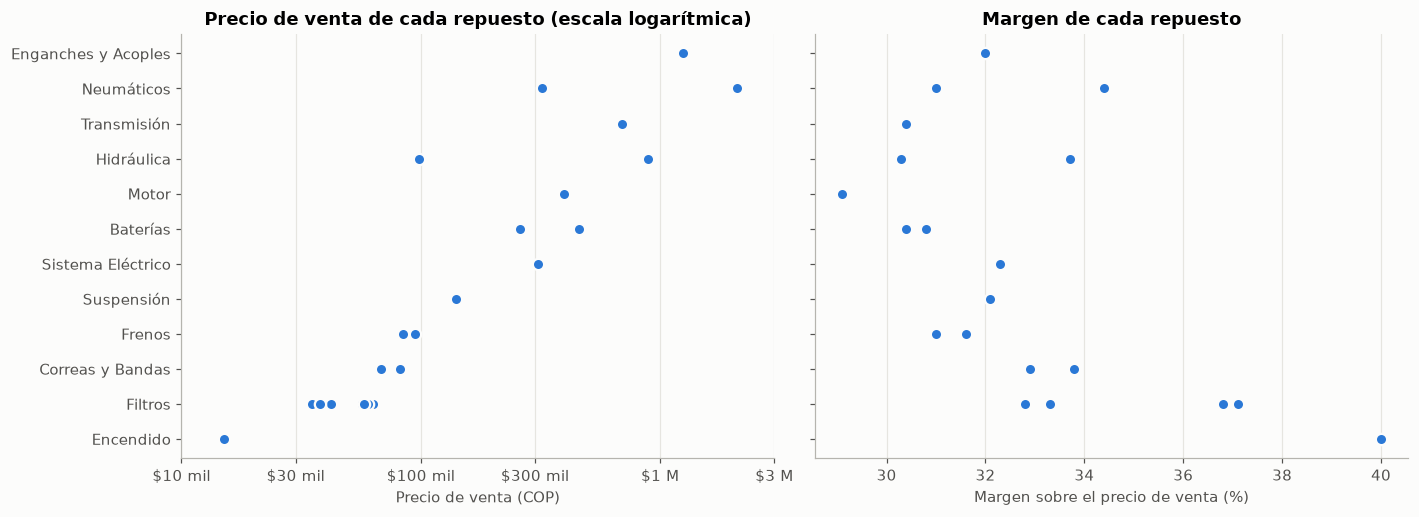

In [17]:
# Gráfica 4: precios de venta y margen por categoría
g4 = consultar("""
    SELECT r.codigo, c.nombre AS categoria, r.precio_compra, r.precio_venta,
           ROUND(100.0 * (r.precio_venta - r.precio_compra) / r.precio_venta, 1) AS margen_pct
    FROM repuestos r JOIN categorias c ON c.id = r.categoria_id""")
orden = g4.groupby("categoria")["precio_venta"].median().sort_values(ascending=False).index.tolist()
posicion = {c: k for k, c in enumerate(orden)}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
a1.scatter(g4["precio_venta"], g4["categoria"].map(posicion), s=55, color=AZUL, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
a1.set_xscale("log")
a1.set_xticks([10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000])
a1.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
a1.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"${v / 1000:,.0f} mil" if v < 1e6 else f"${v / 1e6:,.0f} M"))
a1.set_title("Precio de venta de cada repuesto (escala logarítmica)"); a1.set_xlabel("Precio de venta (COP)")
a2.scatter(g4["margen_pct"], g4["categoria"].map(posicion), s=55, color=AZUL, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
a2.set_title("Margen de cada repuesto"); a2.set_xlabel("Margen sobre el precio de venta (%)")
a1.set_yticks(range(len(orden)), orden); a1.invert_yaxis()
for ax in (a1, a2):
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

SQL> SELECT v.marca, CASE WHEN v.marca IN ('John Deere', 'Case IH', 'Massey Ferguson', 'New Holland') THEN 'maquinaria agrícola' ELSE 'automóvil' END AS tipo, COUNT(*) AS vehiculos FROM vehiculos v GROUP BY v.marca ORDER BY vehiculos DESC, v.marca
SQL> SELECT r.codigo, COUNT(rc.vehiculo_id) AS vehiculos_compatibles FROM repuestos r LEFT JOIN repuesto_compatibilidad rc ON rc.repuesto_id = r.id GROUP BY r.codigo ORDER BY vehiculos_compatibles DESC, r.codigo


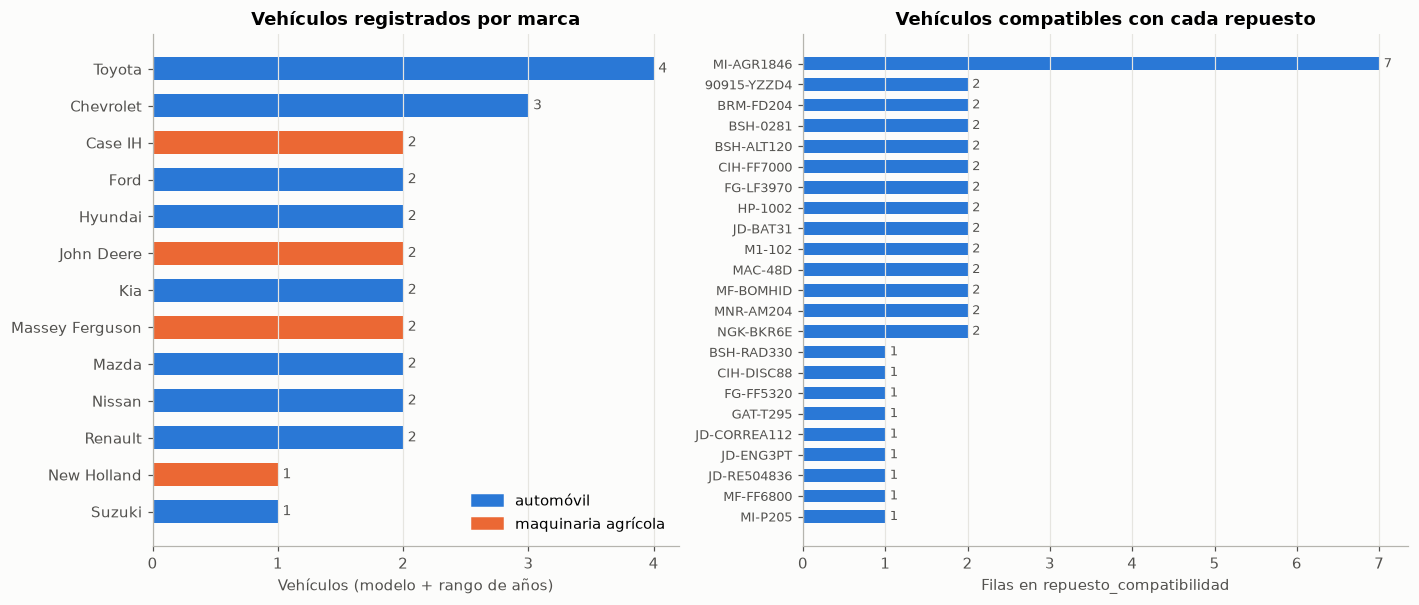

27 vehículos de 13 marcas; 42 relaciones repuesto-vehículo; repuestos sin ningún vehículo compatible: []


In [18]:
# Gráfica 5: vehículos por marca y compatibilidades por repuesto
g5 = consultar("""
    SELECT v.marca,
           CASE WHEN v.marca IN ('John Deere', 'Case IH', 'Massey Ferguson', 'New Holland')
                THEN 'maquinaria agrícola' ELSE 'automóvil' END AS tipo,
           COUNT(*) AS vehiculos
    FROM vehiculos v GROUP BY v.marca ORDER BY vehiculos DESC, v.marca""")
g6 = consultar("""
    SELECT r.codigo, COUNT(rc.vehiculo_id) AS vehiculos_compatibles
    FROM repuestos r LEFT JOIN repuesto_compatibilidad rc ON rc.repuesto_id = r.id
    GROUP BY r.codigo ORDER BY vehiculos_compatibles DESC, r.codigo""")
COLOR_TIPO = {"automóvil": AZUL, "maquinaria agrícola": NARANJA}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1, 1.15]})
b = a1.barh(g5["marca"], g5["vehiculos"], color=g5["tipo"].map(COLOR_TIPO), height=0.62)
a1.bar_label(b, padding=3, color="#52514e", fontsize=9)
a1.invert_yaxis(); a1.grid(axis="y", visible=False)
for ax in (a1, a2):
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
a1.legend(handles=[Patch(color=c, label=t) for t, c in COLOR_TIPO.items()], frameon=False, loc="lower right")
a1.set_title("Vehículos registrados por marca"); a1.set_xlabel("Vehículos (modelo + rango de años)")
b = a2.barh(g6["codigo"], g6["vehiculos_compatibles"], color=AZUL, height=0.62)
a2.bar_label(b, padding=3, color="#52514e", fontsize=8.5)
a2.invert_yaxis(); a2.grid(axis="y", visible=False); a2.tick_params(axis="y", labelsize=8.5)
a2.set_title("Vehículos compatibles con cada repuesto"); a2.set_xlabel("Filas en repuesto_compatibilidad")
plt.tight_layout(); plt.show()
print(f"{int(g5['vehiculos'].sum())} vehículos de {len(g5)} marcas; "
      f"{int(g6['vehiculos_compatibles'].sum())} relaciones repuesto-vehículo; "
      f"repuestos sin ningún vehículo compatible: {g6.loc[g6['vehiculos_compatibles'] == 0, 'codigo'].tolist()}")

**Lectura de las gráficas de la base de datos**

- **El dataset quedó cargado completo**: 402 frases (374 de entrenamiento y 28 de holdout), entre 54 y 60 por intención.
- **El catálogo semilla es pequeño**: 23 repuestos en 12 categorías. *Filtros* concentra 7 repuestos y las demás tienen 1 o 2. En unidades domina *Encendido*, por las 60 bujías de un solo código.
- **Dos repuestos están agotados**: el filtro original Toyota `90915-YZZD4` y el filtro de combustible diésel `FG-FF5320`. Son justo los casos en que el vendedor necesita la intención `recomendar_sustituto`. El primero es el ejemplo central del proyecto (Hilux 2.7 gasolina): sus sustitutos compatibles, `HP-1002` y `M1-102`, sí tienen stock.
- **Los precios van de \$15.000 a \$2.100.000**, por eso se grafican en escala logarítmica. Los repuestos de maquinaria agrícola (llanta de tractor, enganche de tres puntos, bomba hidráulica) cuestan más de 100 veces lo que cuesta una bujía. El margen, en cambio, es parejo: entre 29 % y 40 %.
- **Hay 27 vehículos de 13 marcas**; 4 marcas son de maquinaria agrícola y suman 7 modelos. Todos los repuestos tienen al menos un vehículo compatible. La llanta agrícola `MI-AGR1846` es la más versátil: le sirve a 7 tractores.

### 2.6 El dataset leído desde la base de datos

A partir de aquí el análisis trabaja con el dataset **tal como sale de la base de datos**: una consulta SQL que une `nlp_frases` con `nlp_intenciones`. La celda comprueba que el resultado es idéntico al CSV original.

In [19]:
df = pd.read_sql_query("""
    SELECT f.texto, i.nombre AS intencion
    FROM nlp_frases f JOIN nlp_intenciones i ON i.id = f.intencion_id
    WHERE f.conjunto = 'entrenamiento'
    ORDER BY f.id""", con)
assert df.equals(pd.read_csv(DATASET_PATH)), "La base de datos no coincide con el CSV"
print("Fuente: tabla nlp_frases de la base de datos (idéntica a data/intents_dataset.csv)")
print(f"Filas: {len(df)}   Columnas: {list(df.columns)}")
print(f"Nulos por columna: {df.isna().sum().to_dict()}")
print(f"Textos vacíos: {(df['texto'].str.strip() == '').sum()}")
print(f"Intenciones distintas: {df['intencion'].nunique()}")
df.sample(8, random_state=SEMILLA)

Fuente: tabla nlp_frases de la base de datos (idéntica a data/intents_dataset.csv)
Filas: 374   Columnas: ['texto', 'intencion']
Nulos por columna: {'texto': 0, 'intencion': 0}
Textos vacíos: 0
Intenciones distintas: 7


,texto,intencion
329,"Hola, ¿me puede colaborar con algo?",saludo_despedida
33,¿Cuánto stock queda de bujías NGK?,consultar_stock
15,Busco pastillas de freno para un Chevrolet Onix 2021,buscar_repuesto
325,"Ok gracias, hasta luego",saludo_despedida
57,"Buenas, quisiera hacer una consulta",saludo_despedida
239,Necesito una bomba de agua para Nissan Frontier,buscar_repuesto
76,¿Le sirve esta banda poly-v a un Kia Rio 2017?,consultar_compatibilidad
119,¿Tienen baño para clientes?,fuera_de_dominio


### 2.7 Distribución de clases

,frases,porcentaje
intencion,,
recomendar_sustituto,56,15.0
buscar_repuesto,56,15.0
consultar_stock,56,15.0
consultar_precio,56,15.0
consultar_compatibilidad,50,13.4
saludo_despedida,50,13.4
fuera_de_dominio,50,13.4


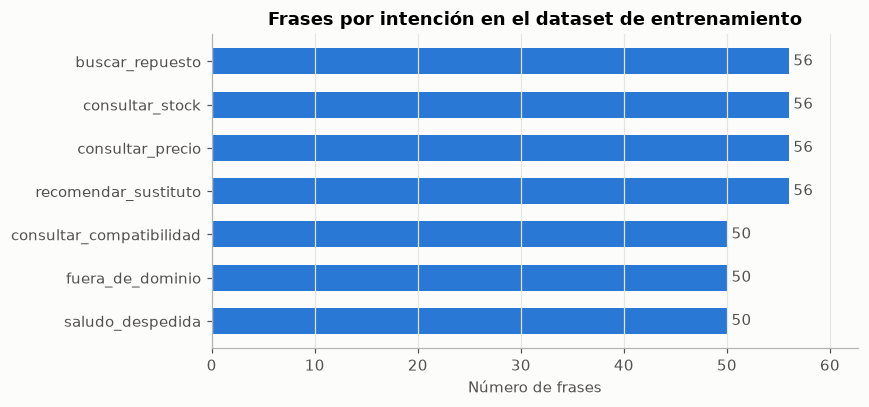

Razón clase mayor / clase menor: 1.12


In [20]:
conteo = df["intencion"].value_counts()
tabla = conteo.to_frame("frases").assign(porcentaje=lambda t: (100 * t["frases"] / t["frases"].sum()).round(1))
display(tabla)

fig, ax = plt.subplots(figsize=(8, 3.8))
orden = conteo.sort_values()
barras = ax.barh(orden.index, orden.values, color=AZUL, height=0.6)
ax.bar_label(barras, padding=3, color="#52514e")
ax.set_title("Frases por intención en el dataset de entrenamiento")
ax.set_xlabel("Número de frases")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, orden.max() * 1.12)
plt.tight_layout(); plt.show()

print(f"Razón clase mayor / clase menor: {conteo.max() / conteo.min():.2f}")

### 2.8 Longitud de las frases

n_palabras         n_tokens_utiles        
                               mean min max            mean min max
intencion                                                          
buscar_repuesto                 7.5   5  10             5.2   2   8
consultar_compatibilidad       10.7   7  15             6.6   5  10
consultar_precio                9.0   4  12             5.3   1   8
consultar_stock                 7.4   4  10             4.7   1   8
fuera_de_dominio                6.2   1  17             3.6   1  12
recomendar_sustituto           11.6   5  18             6.9   2  11
saludo_despedida                4.3   1   7             2.9   1   5

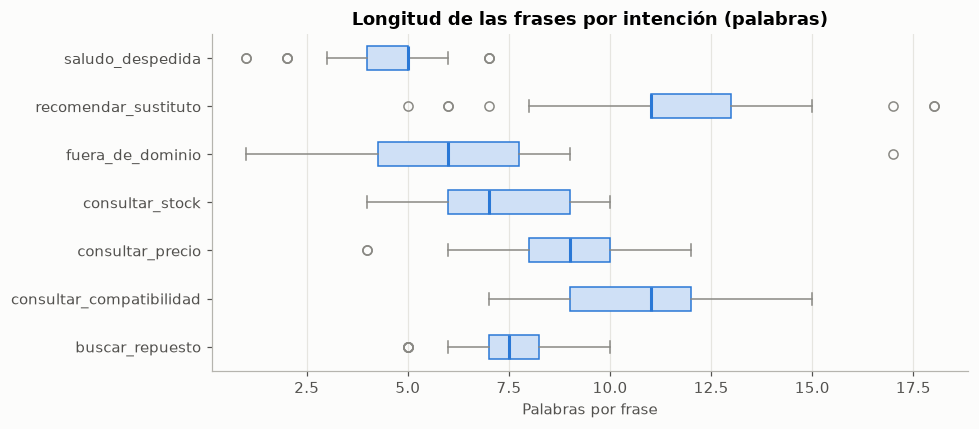

Mediana global: 8 palabras; frases de 1-2 palabras: 8


In [21]:
df["n_palabras"] = df["texto"].str.split().str.len()
df["n_tokens_utiles"] = df["texto"].map(lambda t: len(preprocesar(t)))
resumen_long = df.groupby("intencion")[["n_palabras", "n_tokens_utiles"]].agg(["mean", "min", "max"]).round(1)
display(resumen_long)

clases = sorted(df["intencion"].unique())
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([df.loc[df["intencion"] == c, "n_palabras"] for c in clases], orientation="horizontal",
           tick_labels=clases, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#cfe0f6", edgecolor=AZUL), medianprops=dict(color=AZUL, linewidth=2),
           whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS), flierprops=dict(markeredgecolor=GRIS))
ax.set_title("Longitud de las frases por intención (palabras)")
ax.set_xlabel("Palabras por frase")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"Mediana global: {df['n_palabras'].median():.0f} palabras; "
      f"frases de 1-2 palabras: {(df['n_palabras'] <= 2).sum()}")

### 2.9 Medidas de tendencia central: media, mediana y moda

- **Media** (promedio): la suma de los valores dividida entre cuántos son. Se deja arrastrar por los valores extremos.
- **Mediana**: el valor del medio cuando los datos se ordenan; la mitad queda por debajo y la otra mitad por encima. No le afectan los extremos.
- **Moda**: el valor que más se repite. Es la única de las tres que también sirve para datos que no son números, como la intención o la palabra más usada. Si ningún valor se repite, no hay moda; si varios empatan, hay varias modas.

Se calculan para el dataset (longitud de las frases) y para los datos numéricos de la base (precios, stock, margen y años de los vehículos). Se agregan la desviación estándar, el mínimo y el máximo para ver qué tan dispersos están los valores.

,media,mediana,moda,veces que se repite la moda,desv. estándar,mínimo,máximo
dataset (374 frases),,,,,,,
palabras por frase,8.15,8.0,"7, 9",51,2.99,1,18
caracteres por frase,47.72,48.0,48,20,16.87,4,103
tokens útiles tras preprocesar,5.06,5.0,5,91,1.98,1,12


,media,mediana,moda,desv. estándar,mínimo,máximo
"palabras por frase, por intención",,,,,,
buscar_repuesto,7.48,7.5,7,1.35,5,10
consultar_compatibilidad,10.66,11.0,11,1.93,7,15
consultar_precio,9.0,9.0,9,1.72,4,12
consultar_stock,7.45,7.0,"6, 7",1.51,4,10
fuera_de_dominio,6.18,6.0,7,2.61,1,17
recomendar_sustituto,11.57,11.0,11,2.56,5,18
saludo_despedida,4.34,5.0,5,1.38,1,7


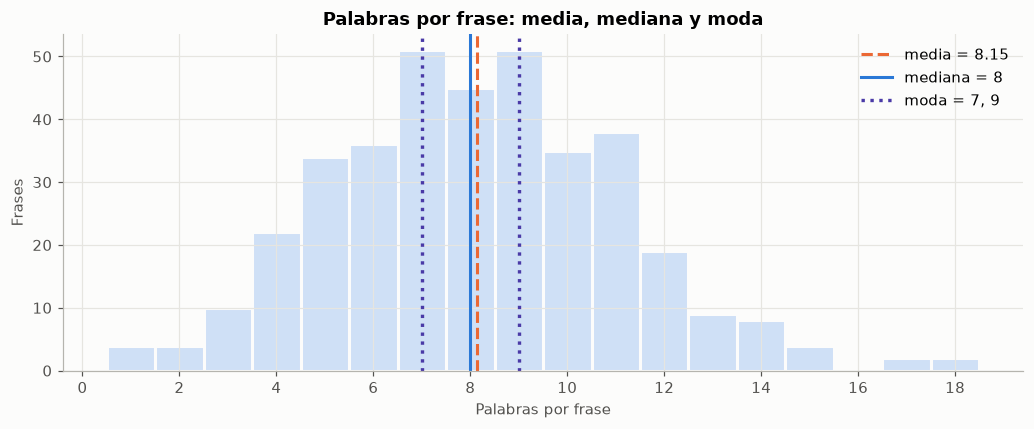

In [22]:
df["n_caracteres"] = df["texto"].str.len()

def tendencia_central(serie):
    frecuencias = serie.value_counts()
    if frecuencias.iloc[0] == 1:
        moda = "sin moda (ningún valor se repite)"
    else:
        moda = ", ".join(str(v) for v in sorted(frecuencias[frecuencias == frecuencias.iloc[0]].index))
    return pd.Series({"media": round(serie.mean(), 2), "mediana": serie.median(), "moda": moda,
                      "veces que se repite la moda": int(frecuencias.iloc[0]),
                      "desv. estándar": round(serie.std(), 2), "mínimo": serie.min(), "máximo": serie.max()})

VARIABLES = {"n_palabras": "palabras por frase", "n_caracteres": "caracteres por frase",
             "n_tokens_utiles": "tokens útiles tras preprocesar"}
tabla_central = pd.DataFrame({nombre: tendencia_central(df[col]) for col, nombre in VARIABLES.items()}).T
display(tabla_central.rename_axis(f"dataset ({len(df)} frases)"))

por_intencion = pd.DataFrame({c: tendencia_central(g["n_palabras"]) for c, g in df.groupby("intencion")}).T
display(por_intencion[["media", "mediana", "moda", "desv. estándar", "mínimo", "máximo"]]
        .rename_axis("palabras por frase, por intención"))

fig, ax = plt.subplots(figsize=(9.5, 4))
bins = np.arange(df["n_palabras"].min() - 0.5, df["n_palabras"].max() + 1.5, 1)
ax.hist(df["n_palabras"], bins=bins, color="#cfe0f6", edgecolor="#fcfcfb", linewidth=2)
media, mediana = df["n_palabras"].mean(), df["n_palabras"].median()
modas = df["n_palabras"].mode().tolist()
ax.axvline(media, color=NARANJA, linestyle="--", linewidth=2, label=f"media = {media:.2f}")
ax.axvline(mediana, color=AZUL, linestyle="-", linewidth=2, label=f"mediana = {mediana:.0f}")
for k, m in enumerate(modas):
    ax.axvline(m, color=VIOLETA, linestyle=":", linewidth=2.2, label=f"moda = {', '.join(map(str, modas))}" if k == 0 else None)
ax.legend(frameon=False)
ax.set_xticks(range(0, int(df["n_palabras"].max()) + 2, 2))
ax.set_title("Palabras por frase: media, mediana y moda")
ax.set_xlabel("Palabras por frase"); ax.set_ylabel("Frases")
plt.tight_layout(); plt.show()

In [23]:
# Moda de variables categóricas (no numéricas), del dataset y de la base de datos
def moda_sql(consulta):
    t = pd.read_sql_query(consulta, con)
    maximo = t["n"].max()
    return ", ".join(t.loc[t["n"] == maximo].iloc[:, 0].astype(str)), int(maximo)

conteo_int = df["intencion"].value_counts()
tokens_todos = Counter(t for s in df["texto"] for t in preprocesar(s))
modas_cat = [
    {"variable": "intención (dataset)", "moda": ", ".join(conteo_int[conteo_int == conteo_int.max()].index),
     "frecuencia": int(conteo_int.max())},
    {"variable": "palabra útil más usada (dataset)", "moda": tokens_todos.most_common(1)[0][0],
     "frecuencia": tokens_todos.most_common(1)[0][1]},
]
for variable, consulta in [
        ("marca de vehículo (base de datos)", "SELECT marca, COUNT(*) AS n FROM vehiculos GROUP BY marca"),
        ("combustible (base de datos)", "SELECT combustible, COUNT(*) AS n FROM vehiculos GROUP BY combustible"),
        ("categoría de repuesto (base de datos)",
         "SELECT c.nombre, COUNT(*) AS n FROM repuestos r JOIN categorias c ON c.id = r.categoria_id GROUP BY c.nombre")]:
    moda, n = moda_sql(consulta)
    modas_cat.append({"variable": variable, "moda": moda, "frecuencia": n})
display(pd.DataFrame(modas_cat).set_index("variable"))
print("Las 8 palabras útiles más frecuentes del dataset:",
      ", ".join(f"{t} ({n})" for t, n in tokens_todos.most_common(8)))

,moda,frecuencia
variable,,
intención (dataset),"recomendar_sustituto, buscar_repuesto, consultar_stock, consultar_precio",56
palabra útil más usada (dataset),no,36
marca de vehículo (base de datos),Toyota,4
combustible (base de datos),gasolina,19
categoría de repuesto (base de datos),Filtros,7


Las 8 palabras útiles más frecuentes del dataset: no (36), filtro (26), cuanto (26), original (25), kit (21), sirve (20), 2019 (18), precio (18)


,media,mediana,moda,veces que se repite la moda,desv. estándar,mínimo,máximo
"base de datos (23 repuestos, 27 vehículos)",,,,,,,
precio de venta (COP),330869.57,95000.0,sin moda (ningún valor se repite),1,496898.59,15000,2100000
precio de compra (COP),227173.91,65000.0,"65000, 210000",2,343005.39,9000,1450000
stock (unidades),11.39,8.0,"0, 5, 6, 7, 8, 10",2,12.16,0,60
margen (%),32.86,32.8,33.3,4,2.49,29.1,40.0
año inicial del vehículo,2016.67,2017.0,2016,7,1.71,2013,2020
años que cubre cada vehículo,6.89,7.0,6,10,1.15,4,9


Comprobación con SQL: AVG(precio_venta) = 330,869.57   AVG(stock) = 11.39
SQLite no trae MEDIAN ni moda; en la base Oracle real las tres medidas salen en una sola consulta:
  SELECT AVG(precio_venta), MEDIAN(precio_venta), STATS_MODE(precio_venta) FROM repuestos;


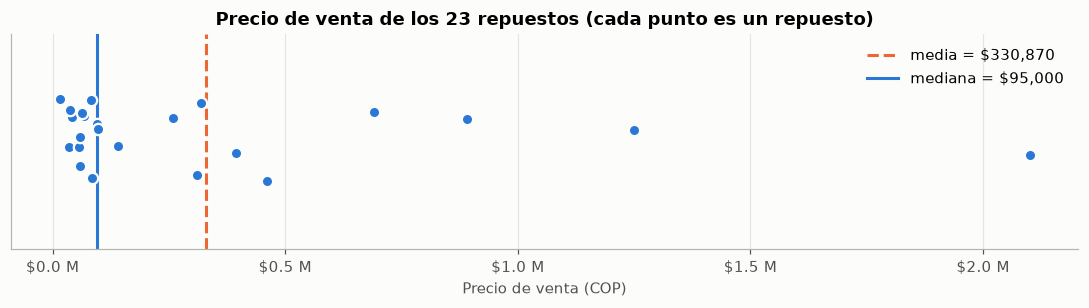

Repuestos por encima de la media: 6 de 23


In [24]:
# Media, mediana y moda de los datos numéricos de la base de datos
rep = pd.read_sql_query("""
    SELECT precio_compra, precio_venta, stock,
           ROUND(100.0 * (precio_venta - precio_compra) / precio_venta, 1) AS margen_pct
    FROM repuestos""", con)
veh = pd.read_sql_query("SELECT anio_desde, anio_hasta - anio_desde + 1 AS anios_cubiertos FROM vehiculos", con)
tabla_bd = pd.DataFrame({
    "precio de venta (COP)": tendencia_central(rep["precio_venta"]),
    "precio de compra (COP)": tendencia_central(rep["precio_compra"]),
    "stock (unidades)": tendencia_central(rep["stock"]),
    "margen (%)": tendencia_central(rep["margen_pct"]),
    "año inicial del vehículo": tendencia_central(veh["anio_desde"]),
    "años que cubre cada vehículo": tendencia_central(veh["anios_cubiertos"]),
}).T
display(tabla_bd.rename_axis(f"base de datos ({len(rep)} repuestos, {len(veh)} vehículos)"))

avg_venta, avg_stock = con.execute("SELECT AVG(precio_venta), AVG(stock) FROM repuestos").fetchone()
print(f"Comprobación con SQL: AVG(precio_venta) = {avg_venta:,.2f}   AVG(stock) = {avg_stock:.2f}")
print("SQLite no trae MEDIAN ni moda; en la base Oracle real las tres medidas salen en una sola consulta:")
print("  SELECT AVG(precio_venta), MEDIAN(precio_venta), STATS_MODE(precio_venta) FROM repuestos;")

fig, ax = plt.subplots(figsize=(10, 2.9))
rng = np.random.default_rng(SEMILLA)
ax.scatter(rep["precio_venta"], rng.uniform(-0.25, 0.25, len(rep)), s=55, color=AZUL, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
m_venta, md_venta = rep["precio_venta"].mean(), rep["precio_venta"].median()
ax.axvline(m_venta, color=NARANJA, linestyle="--", linewidth=2, label=f"media = ${m_venta:,.0f}")
ax.axvline(md_venta, color=AZUL, linestyle="-", linewidth=2, label=f"mediana = ${md_venta:,.0f}")
ax.set_ylim(-0.6, 0.6); ax.set_yticks([]); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"${v / 1e6:,.1f} M"))
ax.legend(frameon=False, loc="upper right")
ax.set_title("Precio de venta de los 23 repuestos (cada punto es un repuesto)")
ax.set_xlabel("Precio de venta (COP)")
plt.tight_layout(); plt.show()
print(f"Repuestos por encima de la media: {(rep['precio_venta'] > m_venta).sum()} de {len(rep)}")

**Lectura de las medidas de tendencia central**

- **Longitud de las frases:** media 8.15, mediana 8 y dos modas, 7 y 9 palabras (51 frases cada una). Las tres medidas casi coinciden, lo que indica una distribución **simétrica**, sin frases extremas que la deformen. Con los caracteres pasa lo mismo: media 47.7, mediana 48 y moda 48.
- **Por intención:** las frases más largas son las de `recomendar_sustituto` (media 11.6) y `consultar_compatibilidad` (10.7), porque describen el repuesto **y** el vehículo. Las más cortas son los saludos (4.3).
- **Moda de datos no numéricos:** la intención tiene **cuatro modas**, las cuatro clases con 56 frases, lo que confirma que el dataset está balanceado. La palabra útil más frecuente es «no» (36 apariciones), la señal principal de `recomendar_sustituto` (§2.11).
- **Precios del catálogo:** aquí la media y la mediana **se separan mucho**: media \$330.870 frente a mediana \$95.000. Unos pocos repuestos agrícolas muy caros arrastran la media hacia arriba; solo 6 de los 23 repuestos la superan. Cuando hay valores extremos, la **mediana** describe mejor el repuesto típico. El precio de venta no tiene moda, porque ningún precio se repite.
- **Stock:** media 11.4 y mediana 8 unidades; hay seis modas empatadas (0, 5, 6, 7, 8 y 10 unidades, con dos repuestos cada una). La media sube por las 60 bujías NGK.
- **Margen:** media 32.9 % y mediana 32.8 %, con una desviación de solo 2.5 puntos. La tienda aplica un margen muy parecido a todos los repuestos.

### 2.10 Duplicados

Se revisan tres niveles: texto idéntico, texto idéntico **después de normalizar** (sin tildes, mayúsculas ni puntuación) y frases que quedan con los **mismos tokens** después del preprocesamiento completo (lo que realmente ve el modelo). También se buscan casi-duplicados con RapidFuzz (`fuzz.ratio ≥ 90` sobre el texto normalizado).

In [25]:
from rapidfuzz import fuzz, process

norm = df["texto"].map(normalizar)
tokens = df["texto"].map(lambda t: " ".join(preprocesar(t)))
print(f"Duplicados exactos:              {df['texto'].duplicated().sum()}")
print(f"Duplicados tras normalizar:      {norm.duplicated().sum()}")
print(f"Duplicados tras preprocesar:     {tokens.duplicated().sum()}")
conflictos = df.assign(tok=tokens).groupby("tok")["intencion"].nunique()
print(f"Mismos tokens con distinta etiqueta (contradicciones): {(conflictos > 1).sum()}")

display(df.assign(tokens=tokens)[tokens.duplicated(keep=False)].sort_values("tokens")[["texto", "intencion", "tokens"]])

# Casi-duplicados dentro del dataset
matriz = process.cdist(norm.tolist(), norm.tolist(), scorer=fuzz.ratio, workers=-1)
i, j = np.where(np.triu(matriz, k=1) >= 90)
casi = pd.DataFrame({"frase_a": df["texto"].values[i], "frase_b": df["texto"].values[j],
                     "similitud": matriz[i, j].round(1),
                     "misma_intencion": df["intencion"].values[i] == df["intencion"].values[j]})
print(f"Pares casi duplicados (ratio >= 90): {len(casi)}")
display(casi.sort_values("similitud", ascending=False).head(10))

Duplicados exactos:              0
Duplicados tras normalizar:      0
Duplicados tras preprocesar:     2
Mismos tokens con distinta etiqueta (contradicciones): 0


,texto,intencion,tokens
310,Buenas,saludo_despedida,buenas
315,buenas como estas,saludo_despedida,buenas
20,¿Tienen la correa poly-v para un Kia Sportage 2020?,buscar_repuesto,tienen correa poly v kia sportage 2020
240,¿Tienen correa poly-v para Kia Sportage 2020?,buscar_repuesto,tienen correa poly v kia sportage 2020


Pares casi duplicados (ratio >= 90): 2


,frase_a,frase_b,similitud,misma_intencion
0,¿Tienen la correa poly-v para un Kia Sportage 2020?,¿Tienen correa poly-v para Kia Sportage 2020?,93.500000,True
1,"Buenas tardes, necesito ayuda",buenas tardes senor necesito ayuda,90.300003,True


### 2.11 Palabras características por intención

Se usa la prueba χ² (chi-cuadrado) sobre conteos de tokens ya preprocesados: mide qué tanto la presencia de una palabra depende de la clase. Es la vista «qué palabras delatan cada intención» antes de entrenar nada.

In [26]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

cv_conteo = CountVectorizer(tokenizer=preprocesar, token_pattern=None, binary=True)
Xc = cv_conteo.fit_transform(df["texto"])
vocab = np.array(cv_conteo.get_feature_names_out())
print(f"Vocabulario tras preprocesar: {len(vocab)} tokens distintos")

filas = {}
for c in clases:
    puntaje, _ = chi2(Xc, (df["intencion"] == c).astype(int))
    en_clase = np.asarray(Xc[(df["intencion"] == c).values].sum(axis=0)).ravel()
    puntaje = np.where(en_clase > 0, np.nan_to_num(puntaje), 0)   # solo palabras que aparecen EN la clase
    top = np.argsort(puntaje)[::-1][:8]
    filas[c] = [f"{vocab[k]} ({en_clase[k]})" for k in top]
display(pd.DataFrame(filas).T.rename(columns=lambda k: f"#{k+1}"))
print("Entre paréntesis: en cuántas frases de esa intención aparece la palabra.")

Vocabulario tras preprocesar: 502 tokens distintos


,#1,#2,#3,#4,#5,#6,#7,#8
buscar_repuesto,manejan (11),busco (10),tienen (12),buscando (3),necesito (8),quiero (4),sistema (2),estoy (3)
consultar_compatibilidad,aplica (14),sirve (16),compatible (12),funciona (7),motores (4),parte (3),modelos (3),1 (5)
consultar_precio,precio (18),cuanto (20),cuesta (7),vale (7),tiene (5),valor (5),sale (4),venta (2)
consultar_stock,cuantas (16),quedan (9),stock (10),inventario (6),unidades (7),bodega (5),queda (9),disponibles (4)
fuera_de_dominio,opinas (3),aca (2),cuentame (2),colombia (2),hacen (2),ustedes (2),hora (2),recomiendame (2)
recomendar_sustituto,no (33),original (22),deme (13),tenemos (8),recomienda (6),alternativa (6),acabo (5),opcion (5)
saludo_despedida,gracias (13),buenas (12),hola (9),dia (4),luego (4),ayuda (4),era (3),muchas (3)


Entre paréntesis: en cuántas frases de esa intención aparece la palabra.


In [27]:
# ¿Cuánto depende el dataset de la negación? (justifica conservar "no" en preprocessing.py)
NEGACIONES = {"no", "sin", "ni", "nunca", "tampoco"}
con_neg = df["texto"].map(lambda t: bool(NEGACIONES & set(normalizar(t).split())))
tabla_neg = (con_neg.groupby(df["intencion"]).mean() * 100).round(1).sort_values(ascending=False)
display(tabla_neg.to_frame("% de frases con negación"))
print("Negaciones que STOPWORDS_ES elimina:", sorted(NEGACIONES & STOPWORDS_ES) or "ninguna")

,% de frases con negación
intencion,
recomendar_sustituto,58.9
consultar_stock,3.6
fuera_de_dominio,2.0
consultar_precio,0.0
consultar_compatibilidad,0.0
buscar_repuesto,0.0
saludo_despedida,0.0


Negaciones que STOPWORDS_ES elimina: ninguna


**Hallazgos de la fase de datos** (los números están en las salidas de arriba)

- 374 frases sin nulos, sin textos vacíos, sin duplicados exactos ni contradicciones de etiqueta. Las clases tienen entre 50 y 56 frases (razón 1.12), así que no es obligatorio reponderar; igual se prueba `class_weight="balanced"` en §4.
- Dos pares de frases quedan **idénticos** para el modelo tras el preprocesamiento («Buenas» / «buenas como estas» y las dos variantes de «¿Tienen (la) correa poly-v…?»). Son pocos, pero dentro de la validación cruzada inflan levemente la métrica: si una cae en entrenamiento y su gemela en validación, el acierto es «gratis». **Corrección propuesta:** dejar una sola frase de cada par en `data/intents_dataset.csv`. (Ojo: `tests/test_dataset.py` solo detecta duplicados exactos, por eso no los marcó.)
- Las palabras características son las esperadas por el negocio (precio → «cuanto», «precio», «cuesta»; stock → «cuantas», «quedan», «stock»; compatibilidad → «aplica», «sirve», «compatible»). La negación aparece en el 58.9 % de las frases de `recomendar_sustituto` y en menos del 4 % de las demás clases: quitar «no» habría borrado la señal principal de esa clase.
- `fuera_de_dominio` **no tiene palabras propias**: sus términos más característicos aparecen en 2 o 3 frases cada uno. Es esperable (lo «ajeno al negocio» es muy variado), pero anticipa que será la clase más difícil (§5.3).
- Límite: las 374 frases fueron escritas por el mismo equipo. No hay todavía consultas reales de vendedores en el dataset (riesgo R1).

## 3. Preparación de los datos

### 3.1 Preprocesamiento: antes y después

`app/preprocessing.py` aplica `normalizar()` (minúsculas, sin tildes, sin puntuación, espacios colapsados), `tokenizar()` y `quitar_stopwords()`. `preprocesar()` es el tokenizador que usa el `TfidfVectorizer` de `_construir_pipeline()`.

In [28]:
ejemplos = [
    "No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recomienda?",
    "¿Hay filtro de aceite para Hilux?",
    "¿Cuánto vale la batería Mac 48D?",
    "¿Esta correa es compatible con motores diésel?",
    "ya no hay terminal de direccion pa golf, que me recomienda",
    "Chao, que tenga buen día",
]
display(pd.DataFrame({
    "original": ejemplos,
    "normalizar()": [normalizar(t) for t in ejemplos],
    "preprocesar() → tokens": [preprocesar(t) for t in ejemplos],
}))

,original,normalizar(),preprocesar() → tokens
0,"No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recom...",no hay filtro de aceite original de toyota para hilux 2 7 gasolina 2024 que me recomienda,"[no, filtro, aceite, original, toyota, hilux, 2, 7, gasolina, 2024, recomienda]"
1,¿Hay filtro de aceite para Hilux?,hay filtro de aceite para hilux,"[filtro, aceite, hilux]"
2,¿Cuánto vale la batería Mac 48D?,cuanto vale la bateria mac 48d,"[cuanto, vale, bateria, mac, 48d]"
3,¿Esta correa es compatible con motores diésel?,esta correa es compatible con motores diesel,"[correa, compatible, motores, diesel]"
4,"ya no hay terminal de direccion pa golf, que me recomienda",ya no hay terminal de direccion pa golf que me recomienda,"[no, terminal, direccion, pa, golf, recomienda]"
5,"Chao, que tenga buen día",chao que tenga buen dia,"[chao, tenga, buen, dia]"


Dos observaciones que salen de la tabla:

1. **La negación sobrevive**: «no hay filtro…» conserva `no`, mientras que en «¿Hay filtro…?» la palabra «hay» es stopword y desaparece. La diferencia entre pedir un sustituto y buscar un repuesto queda en el token `no`.
2. `normalizar()` convierte «2.7» en «2 7». Para la **intención** no importa, pero rompería la regex de motor; por eso el extractor de entidades usa el texto original para año, motor y código (comentado en `app/ner/extractor.py`).

### 3.2 Partición de los datos

| Conjunto | Archivo | Uso |
|---|---|---|
| Entrenamiento / validación | `data/intents_dataset.csv` | Validación cruzada estratificada de 5 partes para comparar configuraciones (§4). El modelo final se entrena con todo el archivo, como hace `train.py`. |
| Prueba independiente (holdout) | `eval/holdout_intent.csv` | Solo se usa una vez, en §5, con la configuración ya elegida. |
| Prueba del NER | `eval/holdout_ner.json` | El NER no se entrena: todo el archivo es prueba. |
| Prueba del recomendador | `eval/holdout_recomendador.json` + `eval/resultados_recomendador.json` | Requiere el backend; se usan los resultados guardados. |

Los dos conjuntos de intención se leen de la tabla `nlp_frases` (columna `conjunto`), que se cargó en §2.3 desde esos archivos.

No se hace un `train_test_split` adicional: con 374 frases, la validación cruzada aprovecha mejor los datos y el holdout ya cumple el papel de prueba final.

In [29]:
ho = frases_desde_bd("holdout")
assert ho.equals(pd.read_csv(HOLDOUT_INTENT_PATH)), "El holdout de la base no coincide con el CSV"
print(f"Holdout de intención (tabla nlp_frases, conjunto = 'holdout'): {len(ho)} frases")
display(ho["intencion"].value_counts().to_frame("frases"))

Holdout de intención (tabla nlp_frases, conjunto = 'holdout'): 28 frases


,frases
intencion,
recomendar_sustituto,4
buscar_repuesto,4
consultar_stock,4
consultar_precio,4
consultar_compatibilidad,4
saludo_despedida,4
fuera_de_dominio,4


### 3.3 Chequeo automático de fuga entre entrenamiento y holdout

Tres niveles: (a) frase idéntica tras `normalizar()`; (b) mismos tokens tras `preprocesar()`; (c) casi idéntica (`fuzz.ratio ≥ 85`). Además (d) se revisa si el dataset **se amplió con el vocabulario de los errores del holdout**, comparando la versión del dataset que existía cuando se generó `eval/resultados_intent.json` con la actual (vía `git`).

In [30]:
tr_norm = set(df["texto"].map(normalizar))
tr_tok = set(df["texto"].map(lambda t: " ".join(preprocesar(t))))
lista_norm = df["texto"].map(normalizar).tolist()

filas = []
for texto, etiqueta in zip(ho["texto"], ho["intencion"]):
    n, t = normalizar(texto), " ".join(preprocesar(texto))
    mejor = process.extractOne(n, lista_norm, scorer=fuzz.ratio)
    filas.append({"texto_holdout": texto, "intencion": etiqueta,
                  "exacta_normalizada": n in tr_norm, "mismos_tokens": t in tr_tok,
                  "similitud_max": round(mejor[1], 1), "frase_mas_parecida_en_train": df["texto"].iloc[mejor[2]]})
fuga = pd.DataFrame(filas)

fugadas = fuga[fuga["exacta_normalizada"] | fuga["mismos_tokens"]]
sospechosas = fuga[(fuga["similitud_max"] >= 85) & ~fuga.index.isin(fugadas.index)]
print(f"(a/b) Fuga exacta o por tokens: {len(fugadas)} frase(s)")
display(fugadas[["texto_holdout", "intencion", "frase_mas_parecida_en_train"]])
print(f"(c) Casi idénticas (ratio >= 85, sin contar las anteriores): {len(sospechosas)}")
display(sospechosas[["texto_holdout", "similitud_max", "frase_mas_parecida_en_train"]])

(a/b) Fuga exacta o por tokens: 1 frase(s)


,texto_holdout,intencion,frase_mas_parecida_en_train
27,¿Cuál es tu color favorito?,fuera_de_dominio,¿Cuál es tu color favorito?


(c) Casi idénticas (ratio >= 85, sin contar las anteriores): 0


,texto_holdout,similitud_max,frase_mas_parecida_en_train


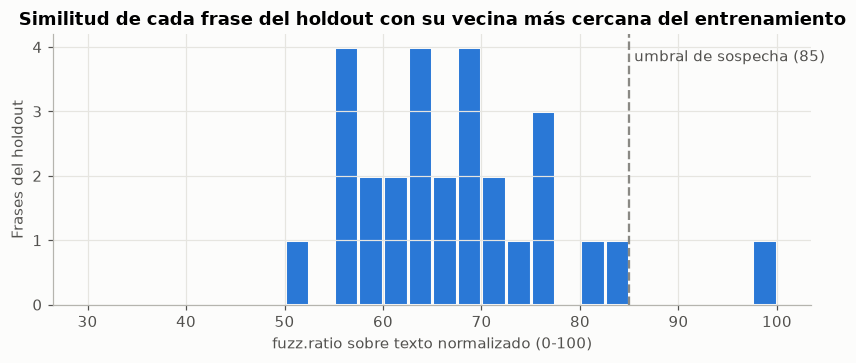

In [31]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(fuga["similitud_max"], bins=np.arange(30, 102.5, 2.5), color=AZUL, edgecolor="#fcfcfb", linewidth=2)
ax.axvline(85, color=GRIS, linestyle="--", linewidth=1.5)
ax.text(85.5, ax.get_ylim()[1] * 0.9, "umbral de sospecha (85)", color="#52514e")
ax.set_title("Similitud de cada frase del holdout con su vecina más cercana del entrenamiento")
ax.set_xlabel("fuzz.ratio sobre texto normalizado (0-100)"); ax.set_ylabel("Frases del holdout")
plt.tight_layout(); plt.show()

In [32]:
# (d) ¿El dataset se amplió con el vocabulario de los errores del holdout?
def dataset_en_commit(commit):
    salida = subprocess.run(["git", "show", f"{commit}:nlp-service/data/intents_dataset.csv"],
                            cwd=RAIZ, capture_output=True, text=True, encoding="utf-8")
    if salida.returncode != 0:
        return None
    from io import StringIO
    return pd.read_csv(StringIO(salida.stdout))

historial = subprocess.run(["git", "log", "--format=%h|%ad|%s", "--date=short", "--", "data/intents_dataset.csv"],
                           cwd=RAIZ, capture_output=True, text=True, encoding="utf-8").stdout.strip().splitlines()
print("Commits que modificaron data/intents_dataset.csv:")
for linea in historial:
    print("  ", linea)

commit_viejo = historial[-1].split("|")[0] if historial else None
df_viejo = dataset_en_commit(commit_viejo) if commit_viejo else None
errores_previos = json.loads((RAIZ / "eval" / "resultados_intent.json").read_text(encoding="utf-8"))["errores"]

if df_viejo is None:
    print("git no disponible: no se puede comparar con la versión anterior del dataset.")
else:
    vocab_viejo = {t for s in df_viejo["texto"] for t in preprocesar(s)}
    vocab_nuevo = {t for s in df["texto"] for t in preprocesar(s)}
    print(f"\nDataset en {commit_viejo}: {len(df_viejo)} frases, {len(vocab_viejo)} tokens | actual: {len(df)} frases, {len(vocab_nuevo)} tokens")
    filas = []
    for e in errores_previos:
        toks = preprocesar(e["texto"])
        nuevos = [t for t in toks if t not in vocab_viejo and t in vocab_nuevo]
        filas.append({"error documentado en resultados_intent.json": e["texto"], "esperado": e["esperado"],
                      "tokens ausentes antes y presentes ahora": ", ".join(nuevos) or "—"})
    display(pd.DataFrame(filas))
    cob = lambda vocab: np.mean([t in vocab for s in ho["texto"] for t in preprocesar(s)])
    print(f"Cobertura del vocabulario del holdout: {cob(vocab_viejo):.1%} con el dataset viejo -> {cob(vocab_nuevo):.1%} con el actual")

Commits que modificaron data/intents_dataset.csv:
   98eac1b|2026-09-28|Ignora claves de despliegue de Azure, reordena rutas de ventas y suma ejemplos al dataset de intents
   9d6a3cc|2026-09-05|Estado inicial del proyecto + asistente NLP (Sprints 0-2)

Dataset en 9d6a3cc: 65 frases, 194 tokens | actual: 374 frases, 502 tokens


,error documentado en resultados_intent.json,esperado,tokens ausentes antes y presentes ahora
0,Dime si hay suficientes bujías Bosch en bodega,consultar_stock,suficientes
1,¿Está por agotarse el disco de embrague Sachs?,consultar_stock,agotarse
2,"Qué tal, necesito una mano con un cliente",saludo_despedida,"tal, mano"
3,"Chao, que estés bien",saludo_despedida,"chao, bien"
4,¿Tienen wifi para clientes?,fuera_de_dominio,"wifi, clientes"


Cobertura del vocabulario del holdout: 75.8% con el dataset viejo -> 91.4% con el actual


In [33]:
# Decisión: el holdout "limpio" excluye las frases con fuga exacta o por tokens
ho_limpio = ho[~ho["texto"].isin(fugadas["texto_holdout"])].reset_index(drop=True)
print(f"Holdout original: {len(ho)} frases -> holdout limpio: {len(ho_limpio)} frases")

Holdout original: 28 frases -> holdout limpio: 27 frases


**Conclusión del chequeo de fuga**

- Hay fuga **exacta**: la(s) frase(s) de la tabla (a/b) están en el entrenamiento y en el holdout. Se excluyen del holdout «limpio» que se usa en §5. **Corrección propuesta (no aplicada):** borrar esa fila de `eval/holdout_intent.csv` o reemplazarla por una frase nueva.
- Hay además **contaminación de vocabulario**: los errores documentados el 2026-09-05 (en `eval/resultados_intent.json` y `docs/evaluacion.md`) contenían palabras que el dataset no tenía («bodega», «chao», «wifi», «agotarse», «mano»…), y el commit que amplió el dataset las agregó. No es un error de programación —fue la mejora que el propio `docs/evaluacion.md` recomendaba—, pero tiene una consecuencia metodológica: **el holdout dejó de ser independiente**, porque se usó para decidir qué datos agregar. Sus métricas en §5 son optimistas y deben leerse junto con la validación cruzada. **Corrección propuesta:** redactar un holdout nuevo (idealmente con frases de vendedores reales) y congelarlo antes de volver a tocar el dataset.

## 4. Modelado

### 4.1 Protocolo

- Validación cruzada **estratificada de 5 partes**, repetida 10 veces con barajados distintos (`RepeatedStratifiedKFold`, 50 evaluaciones por configuración). Repetir no cambia el número de partes; solo reduce la dependencia de un único barajado, importante con ~11 frases por clase en cada parte de validación.
- Todas las configuraciones parten de `_construir_pipeline()` del proyecto y cambian **un solo parámetro** con `set_params`, así la comparación aísla el efecto de ese parámetro.
- Además de accuracy y F1 macro se mide la **confianza media** (probabilidad máxima) y la accuracy **con el umbral de 0.35 aplicado**, porque en producción las predicciones con confianza baja se convierten en `fuera_de_dominio`.

In [34]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

X, y = df["texto"], df["intencion"]
CV_REP = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEMILLA)
CV_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # el mismo que usa train.py

def variante(**params):
    p = _construir_pipeline()
    p.set_params(**params)
    return p

CONFIGS = {
    "A · Proyecto (unigramas, C=15)":      variante(),
    "B · Unigramas + bigramas":            variante(tfidf__ngram_range=(1, 2)),
    "C · C=1 (más regularización)":        variante(clf__C=1),
    "D · C=100 (menos regularización)":    variante(clf__C=100),
    "E · class_weight='balanced'":         variante(clf__class_weight="balanced"),
    "F · Naive Bayes multinomial":         variante(clf=MultinomialNB()),
    "G · Bigramas + balanced (descartada en train.py)": variante(tfidf__ngram_range=(1, 2), clf__class_weight="balanced"),
    "Línea base · clase más frecuente":    variante(clf=DummyClassifier(strategy="most_frequent")),
}
print(_construir_pipeline())

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(token_pattern=None,
                                 tokenizer=<function preprocesar at 0x000002ADB20C4180>)),
                ('clf',
                 LogisticRegression(C=15, max_iter=2000, solver='liblinear'))])


In [35]:
def aplicar_umbral(probas, clases_modelo, umbral=UMBRAL_CONFIANZA):
    # Misma regla que predecir_intencion(), vectorizada para evaluar muchas frases a la vez
    pred = clases_modelo[probas.argmax(axis=1)]
    return np.where(probas.max(axis=1) < umbral, INTENCION_FALLBACK, pred)

resultados, puntajes_por_fold, oof = [], {}, {}
t0 = time.perf_counter()
for nombre, modelo in CONFIGS.items():
    r = cross_validate(modelo, X, y, cv=CV_REP, scoring=["accuracy", "f1_macro"], n_jobs=None)
    probas = cross_val_predict(modelo, X, y, cv=CV_5, method="predict_proba", n_jobs=None)
    clases_m = np.array(sorted(y.unique()))
    oof[nombre] = probas
    puntajes_por_fold[nombre] = r["test_f1_macro"]
    resultados.append({
        "configuración": nombre,
        "accuracy": r["test_accuracy"].mean(), "± accuracy": r["test_accuracy"].std(),
        "F1 macro": r["test_f1_macro"].mean(), "± F1": r["test_f1_macro"].std(),
        "confianza media": probas.max(axis=1).mean(),
        "accuracy con umbral 0.35": accuracy_score(y, aplicar_umbral(probas, clases_m)),
        "% enviado a fallback por el umbral": 100 * (probas.max(axis=1) < UMBRAL_CONFIANZA).mean(),
        "% fuera de dominio tratadas como negocio": 100 * (aplicar_umbral(probas, clases_m)[(y == INTENCION_FALLBACK).values]
                                                            != INTENCION_FALLBACK).mean(),
    })
tabla_modelos = pd.DataFrame(resultados).set_index("configuración")
print(f"Tiempo total: {time.perf_counter() - t0:.1f} s")
display(tabla_modelos.round(3))

Tiempo total: 14.8 s


,accuracy,± accuracy,F1 macro,± F1,confianza media,accuracy con umbral 0.35,% enviado a fallback por el umbral,% fuera de dominio tratadas como negocio
configuración,,,,,,,,
"A · Proyecto (unigramas, C=15)",0.823,0.037,0.820,0.037,0.647,0.807,4.545,32.0
B · Unigramas + bigramas,0.731,0.041,0.731,0.040,0.579,0.706,12.299,34.0
C · C=1 (más regularización),0.787,0.033,0.787,0.032,0.300,0.358,72.995,16.0
D · C=100 (menos regularización),0.832,0.036,0.829,0.037,0.803,0.826,1.337,32.0
E · class_weight='balanced',0.826,0.037,0.824,0.037,0.648,0.807,4.813,32.0
F · Naive Bayes multinomial,0.644,0.045,0.631,0.047,0.290,0.337,76.738,10.0
G · Bigramas + balanced (descartada en train.py),0.732,0.042,0.733,0.041,0.579,0.711,11.765,34.0
Línea base · clase más frecuente,0.147,0.001,0.037,0.000,1.000,0.147,0.000,100.0


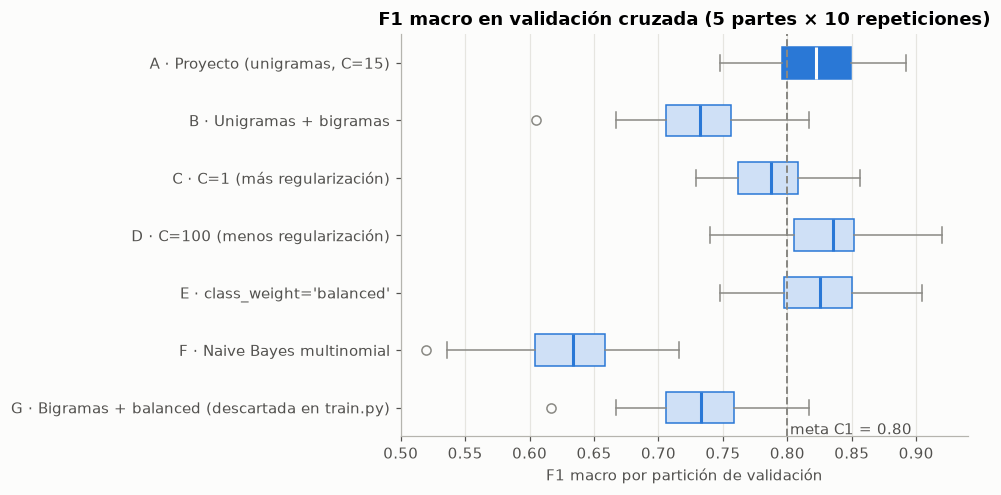

In [36]:
fig, ax = plt.subplots(figsize=(9, 4.6))
nombres = [n for n in CONFIGS if not n.startswith("Línea base")]
datos = [puntajes_por_fold[n] for n in nombres]
bp = ax.boxplot(datos, orientation="horizontal", tick_labels=nombres, widths=0.55, patch_artist=True,
                boxprops=dict(facecolor="#cfe0f6", edgecolor=AZUL), medianprops=dict(color=AZUL, linewidth=2),
                whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS), flierprops=dict(markeredgecolor=GRIS))
bp["boxes"][0].set_facecolor(AZUL); bp["medians"][0].set_color("#fcfcfb")
ax.axvline(0.80, color=GRIS, linestyle="--", linewidth=1.3)
ax.text(0.802, 0.005, "meta C1 = 0.80", color="#52514e", transform=ax.get_xaxis_transform())
ax.invert_yaxis()
ax.set_title("F1 macro en validación cruzada (5 partes × 10 repeticiones)")
ax.set_xlabel("F1 macro por partición de validación")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [37]:
# Comparación pareada contra la configuración del proyecto: mismas 50 particiones para todas
base = puntajes_por_fold["A · Proyecto (unigramas, C=15)"]
filas = []
for n in nombres[1:]:
    d = puntajes_por_fold[n] - base
    filas.append({"configuración": n, "diferencia media de F1 vs A": d.mean(),
                  "desv. de la diferencia": d.std(), "particiones en que gana a A": f"{(d > 0).sum()}/{len(d)}"})
comparacion = pd.DataFrame(filas).set_index("configuración")
display(comparacion.round(3))
f1_dummy = tabla_modelos.loc["Línea base · clase más frecuente", "F1 macro"]
f1_a = tabla_modelos.loc["A · Proyecto (unigramas, C=15)", "F1 macro"]
print(f"Ventaja de A sobre la línea base trivial: {100 * (f1_a - f1_dummy):.1f} puntos de F1 macro (criterio C8)")

,diferencia media de F1 vs A,desv. de la diferencia,particiones en que gana a A
configuración,,,
B · Unigramas + bigramas,-0.089,0.036,0/50
C · C=1 (más regularización),-0.034,0.026,5/50
D · C=100 (menos regularización),0.009,0.015,31/50
E · class_weight='balanced',0.003,0.007,12/50
F · Naive Bayes multinomial,-0.189,0.043,0/50
G · Bigramas + balanced (descartada en train.py),-0.088,0.035,0/50


Ventaja de A sobre la línea base trivial: 78.4 puntos de F1 macro (criterio C8)


### 4.2 Lectura de la comparación y decisión

Lo que muestran las tablas de arriba (F1 macro medio en 50 particiones):

- **A, la configuración del proyecto**, obtiene F1 0.820 ± 0.037, unos 78 puntos por encima de la línea base trivial (0.037).
- **Bigramas (B) empeoran** el F1 en 0.089 y pierden frente a A en las 50 particiones. Con 374 frases la mayoría de los bigramas aparecen una sola vez: agregan dimensiones sin evidencia y diluyen el peso de los unigramas. Esto confirma, con el dataset actual, la decisión documentada en `train.py`.
- **`class_weight="balanced"` (E)** no cambia nada relevante (+0.003): el dataset ya está balanceado.
- **C=1 (C)** baja el F1 en 0.034, pero lo grave es su **confianza media de 0.30**: con el umbral de 0.35, el 73 % de las predicciones se van a `fuera_de_dominio` y la accuracy efectiva cae a 0.358. El umbral y la regularización **no son independientes**: si se cambia C hay que recalibrar el umbral.
- **Naive Bayes (F)** queda muy por debajo: F1 0.631 y confianza media 0.29.
- **C=100 (D)** da +0.009 de F1 y gana en 31 de 50 particiones: una ventaja menor que la desviación de la diferencia (0.015). **No es concluyente.** Además sube la confianza media a 0.80, de modo que el umbral casi nunca se activa (1.3 % de fallback); aun así trata como negocio el mismo 32 % de frases fuera de dominio que A.
- La última columna parece favorecer a C=1 (16 %) y a Naive Bayes (10 %), pero es un espejismo: lo logran porque mandan al fallback el 73 % y el 77 % de **todas** las consultas, incluidas las de negocio.

**Decisión:** se mantiene la configuración del proyecto (A). Ninguna alternativa la supera de forma consistente, y A ya está desplegada, probada (`tests/test_intent.py`) y documentada. C=100 queda como candidata a revisar cuando haya más datos.

**Comentario desactualizado en el código.** `_construir_pipeline()` dice que bigramas + `balanced` daban «probabilidades demasiado planas (~0.20 para la clase correcta)» con «~60 ejemplos». Con el dataset actual, G tiene una confianza media de 0.58, no ~0.20; lo que sigue siendo cierto es que G rinde peor que A (−0.088 de F1). **Corrección propuesta:** actualizar ese comentario (y los de `tests/test_intent.py`, que hablan de ~60 ejemplos y accuracy ~0.30-0.35).

### 4.3 Interpretabilidad: palabras que más pesan por clase

La regresión logística tiene un vector de coeficientes por clase (esquema uno-contra-resto de `liblinear`). Un coeficiente positivo alto significa que la palabra empuja la frase hacia esa intención. Es la explicación que se puede dar en la sustentación: *el modelo es una suma ponderada de palabras*.

Modelo en memoria: 502 términos, 7 clases


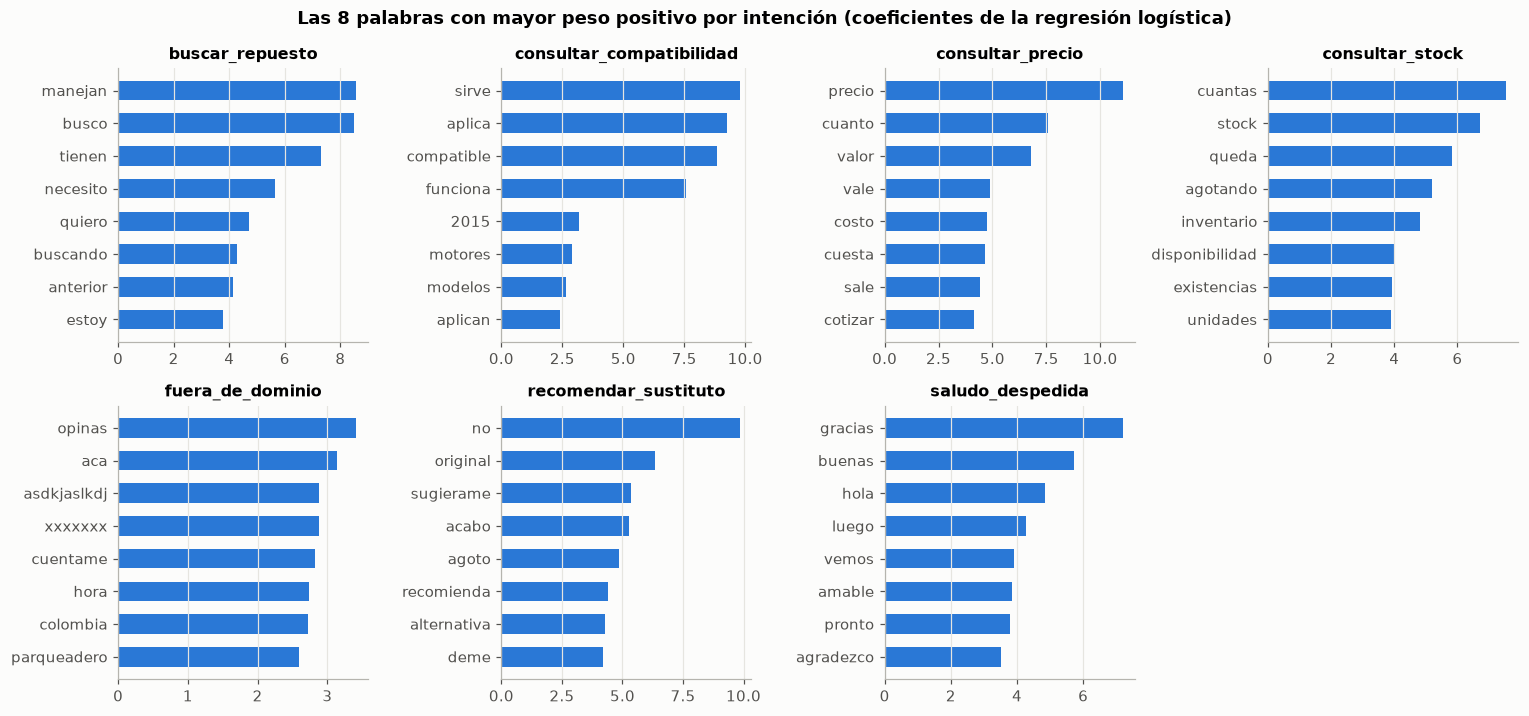

In [38]:
modelo = _construir_pipeline().fit(X, y)      # copia en memoria: NO se guarda en models/
tfidf, clf = modelo.named_steps["tfidf"], modelo.named_steps["clf"]
vocab_m = np.array(tfidf.get_feature_names_out())
print(f"Modelo en memoria: {len(vocab_m)} términos, {len(clf.classes_)} clases")

fig, ejes = plt.subplots(2, 4, figsize=(14, 6.6))
for ax, (k, c) in zip(ejes.ravel(), enumerate(clf.classes_)):
    top = np.argsort(clf.coef_[k])[::-1][:8]
    ax.barh(vocab_m[top][::-1], clf.coef_[k][top][::-1], color=AZUL, height=0.6)
    ax.set_title(c, fontsize=10.5)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=9.5)
ejes.ravel()[-1].axis("off")
fig.suptitle("Las 8 palabras con mayor peso positivo por intención (coeficientes de la regresión logística)",
             fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()

Lectura de la gráfica: las palabras de cada intención son las que usaría un vendedor («precio», «cuanto», «sirve», «aplica», «cuantas», «stock», «gracias»), y `no` es la más fuerte de `recomendar_sustituto`. Dos señales de alerta: `fuera_de_dominio` tiene pesos máximos cerca de 3, frente a 7-11 en las demás clases (el modelo casi no tiene evidencia positiva para ella, y sus palabras son accidentales, como «colombia» o «parqueadero»), y un año, `2015`, aparece como señal de `consultar_compatibilidad`, lo cual es un artefacto del dataset y no una regla del negocio.

In [39]:
def explicar(texto, n=6):
    # Contribución de cada token a la clase predicha = valor TF-IDF × coeficiente
    v = tfidf.transform([texto])
    probas = modelo.predict_proba([texto])[0]
    k = probas.argmax()
    idx = v.nonzero()[1]
    contrib = sorted(((vocab_m[i], v[0, i] * clf.coef_[k][i]) for i in idx), key=lambda x: -abs(x[1]))
    print(f"«{texto}»")
    print(f"  -> {clf.classes_[k]} (probabilidad {probas[k]:.2f})")
    for tok, c in contrib[:n]:
        print(f"     {tok:>14}  {c:+.2f}")

explicar("No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recomienda?")
explicar("¿Hay filtro de aceite para Hilux 2.7?")

«No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recomienda?»
  -> recomendar_sustituto (probabilidad 0.88)
                 no  +2.13
           original  +1.52
         recomienda  +1.43
              hilux  +1.18
             toyota  -0.33
             aceite  +0.20
«¿Hay filtro de aceite para Hilux 2.7?»
  -> recomendar_sustituto (probabilidad 0.37)
              hilux  +1.76
             aceite  +0.30
             filtro  +0.30
                  7  -0.26
                  2  -0.03


El primer ejemplo muestra el papel de la negación: `no` es el token que más empuja la frase hacia `recomendar_sustituto`.

El segundo ejemplo revela un **sesgo que no se esperaba**: sin «no», la consulta *sigue* clasificándose como `recomendar_sustituto`, con una confianza apenas por encima del umbral, y el token que más pesa es `hilux`. El modelo aprendió que «Hilux» aparece sobre todo en frases de sustitutos (es el vehículo del caso del enunciado). Es una correlación espuria: el nombre de un vehículo no debería decidir la intención. La celda siguiente mide cuánto pesan los nombres de vehículos del catálogo semilla.

In [40]:
tokens_vehiculo = sorted({t for v in MARCAS + MODELOS for t in preprocesar(v)} & set(vocab_m))
filas = []
for tok in tokens_vehiculo:
    j = np.where(vocab_m == tok)[0][0]
    k = clf.coef_[:, j].argmax()
    frases = df[df["texto"].map(lambda s: tok in preprocesar(s))]["intencion"].value_counts()
    filas.append({"token": tok, "clase a la que más empuja": clf.classes_[k], "coeficiente": round(clf.coef_[k, j], 2),
                  "frases con el token": int(frases.sum()), "reparto en el dataset": dict(frases)})
sesgo = pd.DataFrame(filas).sort_values("coeficiente", ascending=False).set_index("token")
display(sesgo.head(10))
print(f"Tokens de vehículo en el vocabulario: {len(sesgo)}; con coeficiente > 1 hacia alguna clase: {(sesgo['coeficiente'] > 1).sum()}")

,clase a la que más empuja,coeficiente,frases con el token,reparto en el dataset
token,,,,
hilux,recomendar_sustituto,3.91,9,"{'recomendar_sustituto': 4, 'buscar_repuesto': 2, 'consultar_compatibilidad': 2, 'cons..."
renault,recomendar_sustituto,2.87,8,"{'consultar_compatibilidad': 3, 'recomendar_sustituto': 2, 'buscar_repuesto': 2, 'cons..."
3,recomendar_sustituto,2.75,5,"{'consultar_compatibilidad': 3, 'recomendar_sustituto': 2}"
sentra,buscar_repuesto,2.74,11,"{'buscar_repuesto': 4, 'recomendar_sustituto': 3, 'consultar_stock': 2, 'consultar_com..."
rio,recomendar_sustituto,2.37,5,"{'recomendar_sustituto': 2, 'consultar_compatibilidad': 1, 'consultar_precio': 1, 'bus..."
duster,recomendar_sustituto,2.25,10,"{'buscar_repuesto': 3, 'recomendar_sustituto': 3, 'consultar_compatibilidad': 2, 'cons..."
hyundai,consultar_compatibilidad,2.05,6,"{'consultar_compatibilidad': 3, 'recomendar_sustituto': 1, 'buscar_repuesto': 1, 'cons..."
nissan,buscar_repuesto,1.95,7,"{'buscar_repuesto': 4, 'consultar_compatibilidad': 2, 'consultar_precio': 1}"
mazda,recomendar_sustituto,1.93,13,"{'recomendar_sustituto': 4, 'buscar_repuesto': 3, 'consultar_compatibilidad': 3, 'cons..."


Tokens de vehículo en el vocabulario: 29; con coeficiente > 1 hacia alguna clase: 24


### 4.4 Tabla de parámetros del modelo final

Hay dos tipos de parámetros:

- **Hiperparámetros**: los fija el equipo **antes** de entrenar (en `_construir_pipeline()` de `app/intent/train.py` y en `app/intent/classifier.py`). Son las «perillas» del modelo.
- **Parámetros aprendidos**: los calcula el algoritmo **a partir de los datos** durante el entrenamiento. Son lo que el modelo «sabe».

Al final se resume en una tabla el modelado de §4.1 y §4.2: cada configuración probada y la decisión que se tomó.

In [41]:
p = modelo.get_params()
EXPLICACION = {
    "tfidf__tokenizer": "función que limpia el texto y lo parte en palabras (app/preprocessing.py)",
    "tfidf__ngram_range": "(1, 1): se usan palabras sueltas, no pares de palabras",
    "tfidf__min_df": "una palabra entra al vocabulario si aparece al menos en 1 frase",
    "tfidf__max_df": "1.0: no se descartan palabras por ser demasiado frecuentes",
    "tfidf__use_idf": "las palabras raras pesan más que las comunes (IDF)",
    "tfidf__smooth_idf": "suaviza el IDF para no dividir por cero",
    "tfidf__sublinear_tf": "False: las repeticiones dentro de una frase cuentan de forma lineal",
    "tfidf__norm": "cada frase se normaliza a longitud 1 (norma L2)",
    "clf__C": "inverso de la regularización: con 15 el modelo se ajusta bastante a los datos",
    "clf__penalty": "tipo de regularización",
    "clf__solver": "algoritmo de optimización (uno contra el resto)",
    "clf__max_iter": "máximo de iteraciones del optimizador",
    "clf__class_weight": "None: todas las clases pesan igual (el dataset ya está balanceado)",
    "clf__fit_intercept": "cada clase tiene su propio término independiente (sesgo)",
    "clf__tol": "tolerancia para detener el optimizador",
}
PASO = {"tfidf": "1. TF-IDF", "clf": "2. Regresión logística"}
filas = [{"paso": PASO[k.split("__")[0]], "hiperparámetro": k.split("__")[1],
          "valor": getattr(p[k], "__name__", str(p[k])), "qué controla": v} for k, v in EXPLICACION.items()]
filas += [
    {"paso": "3. Decisión final", "hiperparámetro": "UMBRAL_CONFIANZA", "valor": str(UMBRAL_CONFIANZA),
     "qué controla": f"si la probabilidad máxima es menor, la respuesta es {INTENCION_FALLBACK}"},
    {"paso": "4. Validación", "hiperparámetro": "n_splits × n_repeats", "valor": "5 × 10",
     "qué controla": "validación cruzada estratificada repetida (§4.1)"},
    {"paso": "4. Validación", "hiperparámetro": "random_state", "valor": str(SEMILLA),
     "qué controla": "semilla para que los resultados se puedan reproducir"},
]
display(pd.DataFrame(filas).set_index(["paso", "hiperparámetro"]))

valor  \
paso                   hiperparámetro                      
1. TF-IDF              tokenizer             preprocesar   
                       ngram_range                (1, 1)   
                       min_df                          1   
                       max_df                        1.0   
                       use_idf                      True   
                       smooth_idf                   True   
                       sublinear_tf                False   
                       norm                           l2   
2. Regresión logística C                              15   
                       penalty                        l2   
                       solver                  liblinear   
                       max_iter                     2000   
                       class_weight                 None   
                       fit_intercept                True   
                       tol                        0.0001   
3. Decisión final      UMBRAL_CONFIANZA             0.35   
4. Validación          n_splits × n_repeats       5 × 10   
                       random_state                   42   

                                                                                                              qué controla  
paso                   hiperparámetro                                                                                       
1. TF-IDF              tokenizer                 función que limpia el texto y lo parte en palabras (app/preprocessing.py)  
                       ngram_range                                  (1, 1): se usan palabras sueltas, no pares de palabras  
                       min_df                              una palabra entra al vocabulario si aparece al menos en 1 frase  
                       max_df                                   1.0: no se descartan palabras por ser demasiado frecuentes  
                       use_idf                                          las palabras raras pesan más que las comunes (IDF)  
                       smooth_idf                                                  suaviza el IDF para no dividir por cero  
                       sublinear_tf                    False: las repeticiones dentro de una frase cuentan de forma lineal  
                       norm                                                cada frase se normaliza a longitud 1 (norma L2)  
2. Regresión logística C                     inverso de la regularización: con 15 el modelo se ajusta bastante a los datos  
                       penalty                                                                      tipo de regularización  
                       solver                                              algoritmo de optimización (uno contra el resto)  
                       max_iter                                                      máximo de iteraciones del optimizador  
                       class_weight                     None: todas las clases pesan igual (el dataset ya está balanceado)  
                       fit_intercept                              cada clase tiene su propio término independiente (sesgo)  
                       tol                                                          tolerancia para detener el optimizador  
3. Decisión final      UMBRAL_CONFIANZA               si la probabilidad máxima es menor, la respuesta es fuera_de_dominio  
4. Validación          n_splits × n_repeats                               validación cruzada estratificada repetida (§4.1)  
                       random_state                                   semilla para que los resultados se puedan reproducir

In [42]:
idf = tfidf.idf_
aprendidos = pd.DataFrame([
    {"parámetro aprendido": "vocabulario (términos distintos)", "cantidad": len(vocab_m),
     "detalle": "cada término es una columna de la matriz TF-IDF"},
    {"parámetro aprendido": "pesos IDF (uno por término)", "cantidad": len(idf),
     "detalle": f"de {idf.min():.2f} (el término más común, «{vocab_m[idf.argmin()]}») a {idf.max():.2f} (términos de una sola frase)"},
    {"parámetro aprendido": "coeficientes (peso de cada término en cada clase)", "cantidad": clf.coef_.size,
     "detalle": f"matriz de {clf.coef_.shape[0]} clases × {clf.coef_.shape[1]} términos"},
    {"parámetro aprendido": "interceptos (sesgo de cada clase)", "cantidad": clf.intercept_.size,
     "detalle": "uno por intención"},
]).set_index("parámetro aprendido")
display(aprendidos)
print(f"Parámetros numéricos que aprendió la regresión logística: {clf.coef_.size + clf.intercept_.size:,} "
      f"(coeficientes + interceptos), a partir de {len(df)} frases.")
display(pd.DataFrame({"intercepto": clf.intercept_.round(3),
                      "términos con peso positivo": (clf.coef_ > 0).sum(axis=1),
                      "término de mayor peso": vocab_m[clf.coef_.argmax(axis=1)],
                      "peso máximo": clf.coef_.max(axis=1).round(2)},
                     index=pd.Index(clf.classes_, name="intención")))

,cantidad,detalle
parámetro aprendido,,
vocabulario (términos distintos),502,cada término es una columna de la matriz TF-IDF
pesos IDF (uno por término),502,"de 3.32 (el término más común, «no») a 6.23 (términos de una sola frase)"
coeficientes (peso de cada término en cada clase),3514,matriz de 7 clases × 502 términos
interceptos (sesgo de cada clase),7,uno por intención


Parámetros numéricos que aprendió la regresión logística: 3,521 (coeficientes + interceptos), a partir de 374 frases.


,intercepto,términos con peso positivo,término de mayor peso,peso máximo
intención,,,,
buscar_repuesto,-3.224,130,manejan,8.57
consultar_compatibilidad,-3.435,144,sirve,9.77
consultar_precio,-3.013,134,precio,11.06
consultar_stock,-2.816,114,cuantas,7.54
fuera_de_dominio,-1.441,142,opinas,3.42
recomendar_sustituto,-3.313,121,no,9.84
saludo_despedida,-2.699,67,gracias,7.20


In [43]:
# Tabla resumen del modelado: configuraciones probadas y decisión
def decision(nombre):
    # Usa la comparación pareada de §4.1 (misma partición para todas las configuraciones)
    if nombre.startswith("A ·"):
        return "ELEGIDA (configuración del proyecto)"
    if nombre.startswith("Línea base"):
        return "referencia mínima (adivinar siempre la misma clase)"
    d = comparacion.loc[nombre, "diferencia media de F1 vs A"]
    gana = comparacion.loc[nombre, "particiones en que gana a A"]
    fallback = tabla_modelos.loc[nombre, "% enviado a fallback por el umbral"]
    if fallback > 50:
        return f"descartada: el umbral manda el {fallback:.0f} % de las frases a fallback (F1 {d:+.3f})"
    if abs(d) < 0.01:
        return f"no concluyente: F1 {d:+.3f} frente a A, le gana en {gana} particiones"
    return f"descartada: F1 {d:+.3f} frente a A, le gana en {gana} particiones"

resumen_modelado = tabla_modelos[["F1 macro", "± F1", "accuracy", "accuracy con umbral 0.35", "confianza media"]].copy()
resumen_modelado["decisión"] = [decision(n) for n in resumen_modelado.index]
display(resumen_modelado.sort_values("F1 macro", ascending=False).round(3))

,F1 macro,± F1,accuracy,accuracy con umbral 0.35,confianza media,decisión
configuración,,,,,,
D · C=100 (menos regularización),0.829,0.037,0.832,0.826,0.803,"no concluyente: F1 +0.009 frente a A, le gana en 31/50 particiones"
E · class_weight='balanced',0.824,0.037,0.826,0.807,0.648,"no concluyente: F1 +0.003 frente a A, le gana en 12/50 particiones"
"A · Proyecto (unigramas, C=15)",0.820,0.037,0.823,0.807,0.647,ELEGIDA (configuración del proyecto)
C · C=1 (más regularización),0.787,0.032,0.787,0.358,0.300,descartada: el umbral manda el 73 % de las frases a fallback (F1 -0.034)
G · Bigramas + balanced (descartada en train.py),0.733,0.041,0.732,0.711,0.579,"descartada: F1 -0.088 frente a A, le gana en 0/50 particiones"
B · Unigramas + bigramas,0.731,0.040,0.731,0.706,0.579,"descartada: F1 -0.089 frente a A, le gana en 0/50 particiones"
F · Naive Bayes multinomial,0.631,0.047,0.644,0.337,0.290,descartada: el umbral manda el 77 % de las frases a fallback (F1 -0.189)
Línea base · clase más frecuente,0.037,0.000,0.147,0.147,1.000,referencia mínima (adivinar siempre la misma clase)


**Lectura.** El modelo es pequeño y explicable: aprende 3.521 números, que son un peso por palabra y por intención más un sesgo por intención, a partir de 374 frases. La palabra de mayor peso de cada clase coincide con la intuición del negocio:

- «precio» para `consultar_precio`
- «sirve» para `consultar_compatibilidad`
- «cuantas» para `consultar_stock`
- «no» para `recomendar_sustituto`
- «gracias» para `saludo_despedida`

`fuera_de_dominio` tiene el peso máximo más bajo (3.42, «opinas»): no tiene palabras propias, como ya se vio en §2.11. La tabla del modelado confirma la decisión de §4.2: ninguna configuración supera a A de forma consistente.

## 5. Evaluación

### 5.1 ¿El modelo guardado corresponde al dataset actual?

Antes de evaluar se compara el modelo en memoria (entrenado ahora con el dataset actual, igual que haría `python -m app.intent.train`) con `models/intent_classifier.pkl`, que se **lee** sin modificarlo.

In [44]:
import joblib, datetime
guardado = joblib.load(MODEL_PATH)
metricas_guardadas = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
fecha_pkl = datetime.datetime.fromtimestamp(MODEL_PATH.stat().st_mtime).strftime("%Y-%m-%d %H:%M")
comparar = pd.DataFrame({
    "models/intent_classifier.pkl": [fecha_pkl, len(guardado.named_steps["tfidf"].vocabulary_),
                                     metricas_guardadas["n_ejemplos"], round(metricas_guardadas["accuracy"], 3)],
    "modelo en memoria (dataset actual)": ["ahora", len(vocab_m), len(df), "ver §4"],
}, index=["fecha del archivo", "términos del vocabulario", "frases de entrenamiento (según metrics_intent.json)", "accuracy CV guardada"])
display(comparar)
coinciden = (guardado.predict(ho["texto"]) == modelo.predict(ho["texto"])).mean()
print(f"Coincidencia de predicciones en el holdout entre ambos modelos: {coinciden:.1%}")

,models/intent_classifier.pkl,modelo en memoria (dataset actual)
fecha del archivo,2026-09-21 12:30,ahora
términos del vocabulario,194,502
frases de entrenamiento (según metrics_intent.json),65,374
accuracy CV guardada,0.338,ver §4


Coincidencia de predicciones en el holdout entre ambos modelos: 75.0%


**Hallazgo importante.** El `.pkl` local fue entrenado con la versión anterior del dataset (el vocabulario y `metrics_intent.json` no corresponden a las 374 frases actuales). Como `app/main.py` solo reentrena si el archivo **no existe**, y el `Dockerfile` hace `COPY models ./models`, una imagen construida desde esta carpeta serviría el modelo viejo. No se sobrescribe aquí (regla del cuaderno).

**Corrección propuesta:** ejecutar `python -m app.intent.train` antes de construir la imagen, o mejor agregar `RUN python -m app.intent.train` al `Dockerfile` después de `COPY data ./data`, para que el modelo servido siempre salga del dataset versionado. Toda la evaluación de abajo usa el modelo **en memoria**, que es el que se obtendría al reentrenar.

### 5.2 Métricas en el holdout

Se evalúa con `predecir_intencion(texto, pipeline=modelo)`, la misma función que usa producción (umbral incluido), pasándole el modelo en memoria.

In [45]:
def evaluar_holdout(datos):
    pares = [predecir_intencion(t, pipeline=modelo) for t in datos["texto"]]
    out = datos.copy()
    out["predicho"] = [p for p, _ in pares]
    out["confianza"] = [c for _, c in pares]
    return out

def intervalo_wilson(aciertos, n, z=1.96):
    p = aciertos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen

res_limpio = evaluar_holdout(ho_limpio)
res_completo = evaluar_holdout(ho)
filas = []
for nombre, r in [("Holdout limpio", res_limpio), ("Holdout completo (con la fila fugada)", res_completo)]:
    acc = accuracy_score(r["intencion"], r["predicho"])
    lo, hi = intervalo_wilson((r["intencion"] == r["predicho"]).sum(), len(r))
    filas.append({"conjunto": nombre, "n": len(r), "aciertos": int((r["intencion"] == r["predicho"]).sum()),
                  "accuracy": acc, "IC 95 % (Wilson)": f"[{lo:.2f}, {hi:.2f}]",
                  "F1 macro": f1_score(r["intencion"], r["predicho"], average="macro"),
                  "confianza media": r["confianza"].mean()})
tabla_holdout = pd.DataFrame(filas).set_index("conjunto")
display(tabla_holdout.round(3))
ACC_HOLDOUT = tabla_holdout.loc["Holdout limpio", "accuracy"]
print(f"Cada frase del holdout limpio vale {100 / len(res_limpio):.1f} puntos de accuracy.")
print(classification_report(res_limpio["intencion"], res_limpio["predicho"], zero_division=0, digits=3))

,n,aciertos,accuracy,IC 95 % (Wilson),F1 macro,confianza media
conjunto,,,,,,
Holdout limpio,27,25,0.926,"[0.77, 0.98]",0.923,0.742
Holdout completo (con la fila fugada),28,26,0.929,"[0.77, 0.98]",0.927,0.745


Cada frase del holdout limpio vale 3.7 puntos de accuracy.
                          precision    recall  f1-score   support

         buscar_repuesto      1.000     0.750     0.857         4
consultar_compatibilidad      1.000     1.000     1.000         4
        consultar_precio      0.800     1.000     0.889         4
         consultar_stock      1.000     1.000     1.000         4
        fuera_de_dominio      0.750     1.000     0.857         3
    recomendar_sustituto      1.000     0.750     0.857         4
        saludo_despedida      1.000     1.000     1.000         4

                accuracy                          0.926        27
               macro avg      0.936     0.929     0.923        27
            weighted avg      0.943     0.926     0.925        27



In [46]:
acc_cv = tabla_modelos.loc["A · Proyecto (unigramas, C=15)", "accuracy con umbral 0.35"]
print(f"Accuracy con umbral — validación cruzada (374 frases): {acc_cv:.3f}")
print(f"Accuracy con umbral — holdout limpio ({len(res_limpio)} frases):     {ACC_HOLDOUT:.3f}")
print(f"Accuracy documentada en docs/evaluacion.md (2026-09-05, dataset viejo): 0.821")
acc_sin_umbral = accuracy_score(ho_limpio["intencion"], modelo.predict(ho_limpio["texto"]))
print(f"Holdout limpio SIN umbral (solo argmax): {acc_sin_umbral:.3f}")

Accuracy con umbral — validación cruzada (374 frases): 0.807
Accuracy con umbral — holdout limpio (27 frases):     0.926
Accuracy documentada en docs/evaluacion.md (2026-09-05, dataset viejo): 0.821
Holdout limpio SIN umbral (solo argmax): 0.963


**Lectura honesta.**

- El holdout limpio da 0.926 (25 de 27), **más** que la validación cruzada (0.807). Lo normal sería lo contrario, porque el holdout se redactó con otro estilo; la explicación más probable es la de §3.3: el dataset se amplió con el vocabulario de los errores del holdout.
- Con 27 frases, cada una vale 3.7 puntos y el intervalo de Wilson al 95 % va de 0.77 a 0.98: **su límite inferior queda por debajo de la meta de 0.80**. El criterio C2 se cumple en la estimación puntual, no con certeza estadística.
- Sin el umbral la accuracy del holdout sería mayor (ver la última línea): una de las dos fallas es una frase de negocio bien clasificada que el umbral mandó a `fuera_de_dominio` (§5.4).
- **Conclusión:** el holdout confirma que el modelo funciona, pero la estimación más confiable de su desempeño es la de **validación cruzada**.

### 5.3 Matrices de confusión

Se muestran las dos: la del holdout (pocas frases, pero nunca vistas) y la de validación cruzada con las 374 frases (predicciones fuera de la partición, `cross_val_predict`, con umbral), que tiene suficientes casos para ver patrones.

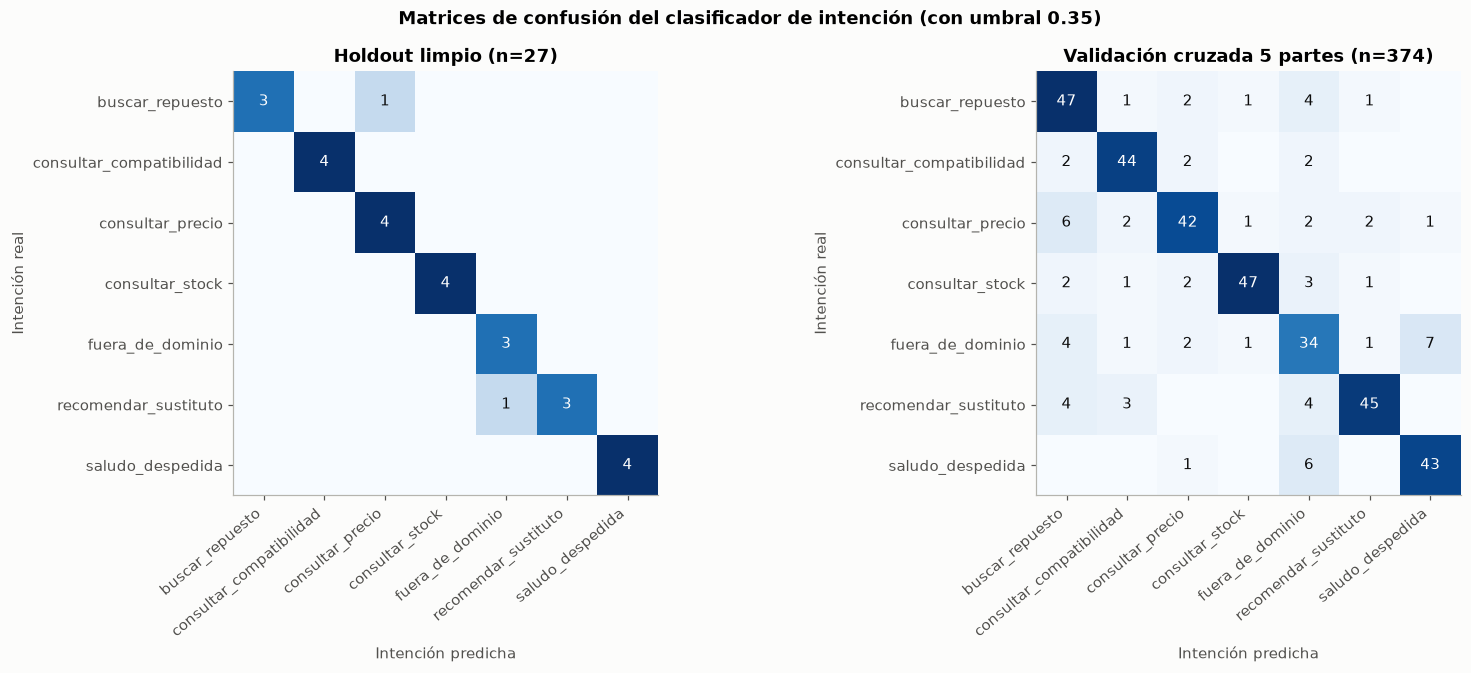

,precision,recall,F1,frases
buscar_repuesto,0.723,0.839,0.777,56
consultar_compatibilidad,0.846,0.880,0.863,50
consultar_precio,0.824,0.750,0.785,56
consultar_stock,0.940,0.839,0.887,56
fuera_de_dominio,0.618,0.680,0.648,50
recomendar_sustituto,0.900,0.804,0.849,56
saludo_despedida,0.843,0.860,0.851,50


Recall de recomendar_sustituto en validación cruzada: 0.804 (criterio C3)


In [47]:
etiquetas = sorted(y.unique())
pred_cv = aplicar_umbral(oof["A · Proyecto (unigramas, C=15)"], np.array(etiquetas))

fig, ejes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, (titulo, real, pred) in zip(ejes, [
        (f"Holdout limpio (n={len(res_limpio)})", res_limpio["intencion"], res_limpio["predicho"]),
        (f"Validación cruzada 5 partes (n={len(y)})", y, pred_cv)]):
    cm = confusion_matrix(real, pred, labels=etiquetas)
    ax.imshow(cm, cmap="Blues")
    ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=10,
                    color="white" if v > cm.max() * 0.55 else "#0b0b0b")
    ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=40, ha="right")
    ax.set_yticks(range(len(etiquetas)), etiquetas)
    ax.set_xlabel("Intención predicha"); ax.set_ylabel("Intención real")
    ax.set_title(titulo)
fig.suptitle("Matrices de confusión del clasificador de intención (con umbral 0.35)", fontweight="bold")
plt.tight_layout(); plt.show()

p, r, f, s = precision_recall_fscore_support(y, pred_cv, labels=etiquetas, zero_division=0)
por_clase_cv = pd.DataFrame({"precision": p, "recall": r, "F1": f, "frases": s}, index=etiquetas).round(3)
display(por_clase_cv)
RECALL_SUSTITUTO = por_clase_cv.loc["recomendar_sustituto", "recall"]
print(f"Recall de recomendar_sustituto en validación cruzada: {RECALL_SUSTITUTO:.3f} (criterio C3)")

**Lectura.** En validación cruzada, `fuera_de_dominio` es la clase más débil (F1 0.648), como anticipaba §2.11. La intención central, `recomendar_sustituto`, tiene buena precisión (0.900: cuando el modelo dice «sustituto», casi siempre lo es) pero un recall de 0.804, **por debajo de la meta C3 de 0.90**: una de cada cinco consultas de sustituto se va a otra clase o al fallback. Para el vendedor eso significa recibir una búsqueda normal, o un «no entendí», cuando pedía una alternativa.

### 5.4 Errores concretos

In [48]:
err_ho = res_limpio[res_limpio["intencion"] != res_limpio["predicho"]]
print(f"Errores en el holdout limpio: {len(err_ho)} de {len(res_limpio)}")
display(err_ho[["texto", "intencion", "predicho", "confianza"]].round(3))

conf_cv = oof["A · Proyecto (unigramas, C=15)"].max(axis=1)
err_cv = df.assign(predicho=pred_cv, confianza=conf_cv.round(3))[lambda t: t["intencion"] != t["predicho"]]
print(f"\nErrores en validación cruzada: {len(err_cv)} de {len(df)}")
pares_err = err_cv.groupby(["intencion", "predicho"]).size().sort_values(ascending=False).head(8)
display(pares_err.to_frame("errores"))
print("Los 10 errores con MÁS confianza (los más peligrosos: el modelo estaba seguro y se equivocó):")
display(err_cv.sort_values("confianza", ascending=False)[["texto", "intencion", "predicho", "confianza"]].head(10))

Errores en el holdout limpio: 2 de 27


,texto,intencion,predicho,confianza
2,"Se me acabaron las bujías Bosch para un Kia Sportage, cuál le doy en cambio",recomendar_sustituto,fuera_de_dominio,0.308
5,Necesito cotizar un alternador para Kia Sportage,buscar_repuesto,consultar_precio,0.485



Errores en validación cruzada: 72 de 374


,,errores
intencion,predicho,
fuera_de_dominio,saludo_despedida,7
consultar_precio,buscar_repuesto,6
saludo_despedida,fuera_de_dominio,6
fuera_de_dominio,buscar_repuesto,4
recomendar_sustituto,fuera_de_dominio,4
buscar_repuesto,fuera_de_dominio,4
recomendar_sustituto,buscar_repuesto,4
consultar_stock,fuera_de_dominio,3


Los 10 errores con MÁS confianza (los más peligrosos: el modelo estaba seguro y se equivocó):


,texto,intencion,predicho,confianza
146,¿Cuánto falta para navidad?,fuera_de_dominio,consultar_precio,0.884
112,¿Qué signo del zodiaco es más compatible con Escorpio?,fuera_de_dominio,consultar_compatibilidad,0.874
116,¿Cuánto es 458 multiplicado por 12?,fuera_de_dominio,consultar_precio,0.821
118,necesito el numero de whatsapp del jefe,fuera_de_dominio,buscar_repuesto,0.817
133,¿Cómo se dice buenos días en inglés?,fuera_de_dominio,saludo_despedida,0.807
135,¿Tienen parqueadero disponible?,fuera_de_dominio,buscar_repuesto,0.804
314,"Qué tal, ¿cómo va todo?",saludo_despedida,fuera_de_dominio,0.783
139,"buenas, aca vive alguien de apellido gomez",fuera_de_dominio,saludo_despedida,0.783
186,¿Qué tan caro está el radiador original comparado con el genérico?,consultar_precio,recomendar_sustituto,0.777
119,¿Tienen baño para clientes?,fuera_de_dominio,buscar_repuesto,0.771


**Qué dicen los errores**

- **Holdout:** «Se me acabaron las bujías Bosch para un Kia Sportage, cuál le doy en cambio» es un `recomendar_sustituto` que el modelo sí ponía primero, pero con 0.308 de confianza: **el umbral lo descartó**. «Necesito cotizar un alternador…» se clasificó como `consultar_precio`; es un error discutible, porque «cotizar» sí es pedir un precio.
- **Validación cruzada:** los errores más confiados son casi todos frases **fuera de dominio que contienen palabras del negocio**: «¿**Cuánto** falta para navidad?» → `consultar_precio` (0.88), «¿Qué signo del zodiaco es más **compatible**…?» → `consultar_compatibilidad`, «¿**Tienen** parqueadero disponible?» → `buscar_repuesto`. Un modelo de bolsa de palabras no entiende que «cuánto» se refiere a otra cosa: ve la palabra y la asocia a la clase. Ningún umbral de confianza corrige esto, porque el modelo está *seguro*.

### 5.5 Efecto del umbral de confianza

Se barre el umbral de 0 a 0.8 sobre las predicciones de validación cruzada (374 frases) y se miden tres cosas: la accuracy final, qué fracción de las frases **de negocio** se descarta por error a `fuera_de_dominio` y qué fracción de las frases **fuera de dominio** se atrapa.

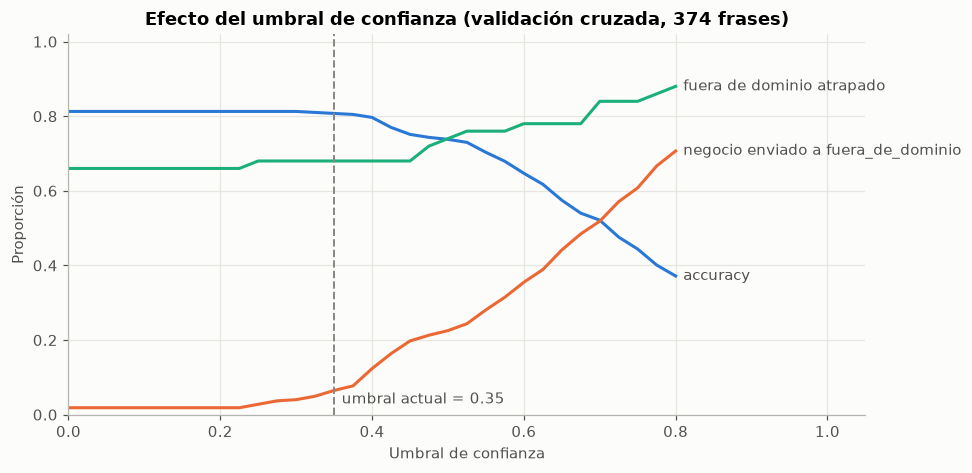

,accuracy,negocio enviado a fuera_de_dominio,fuera de dominio atrapado
umbral,,,
0.00,0.813,0.019,0.66
0.20,0.813,0.019,0.66
0.30,0.813,0.040,0.68
0.35,0.807,0.065,0.68
0.40,0.797,0.123,0.68
0.50,0.738,0.225,0.74
0.60,0.647,0.355,0.78


Umbral con mayor accuracy en CV: 0.0 (accuracy 0.813); con 0.35: 0.807


In [49]:
probas_cv = oof["A · Proyecto (unigramas, C=15)"]
clases_arr = np.array(etiquetas)
es_fdd = (y == INTENCION_FALLBACK).values
umbrales = np.round(np.arange(0.0, 0.81, 0.025), 3)
filas = []
for u in umbrales:
    pred = aplicar_umbral(probas_cv, clases_arr, u)
    filas.append({"umbral": u,
                  "accuracy": accuracy_score(y, pred),
                  "negocio enviado a fuera_de_dominio": ((pred == INTENCION_FALLBACK) & ~es_fdd).sum() / (~es_fdd).sum(),
                  "fuera de dominio atrapado": (pred[es_fdd] == INTENCION_FALLBACK).mean()})
barrido = pd.DataFrame(filas).set_index("umbral")

fig, ax = plt.subplots(figsize=(9, 4.4))
for col, color in [("accuracy", AZUL), ("fuera de dominio atrapado", AQUA), ("negocio enviado a fuera_de_dominio", NARANJA)]:
    ax.plot(barrido.index, barrido[col], color=color, linewidth=2)
    ax.text(barrido.index[-1] + 0.01, barrido[col].iloc[-1], col, color="#52514e", va="center")
ax.axvline(UMBRAL_CONFIANZA, color=GRIS, linestyle="--", linewidth=1.3)
ax.text(UMBRAL_CONFIANZA + 0.01, 0.03, f"umbral actual = {UMBRAL_CONFIANZA}", color="#52514e")
ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.02)
ax.set_title("Efecto del umbral de confianza (validación cruzada, 374 frases)")
ax.set_xlabel("Umbral de confianza"); ax.set_ylabel("Proporción")
plt.tight_layout(); plt.show()

display(barrido.loc[[0.0, 0.2, 0.3, 0.35, 0.4, 0.5, 0.6]].round(3))
mejor_u = barrido["accuracy"].idxmax()
print(f"Umbral con mayor accuracy en CV: {mejor_u} (accuracy {barrido['accuracy'].max():.3f}); "
      f"con 0.35: {barrido.loc[0.35, 'accuracy']:.3f}")

Fuera de dominio tratadas como negocio: 32.0% de 50 frases (criterio C4)


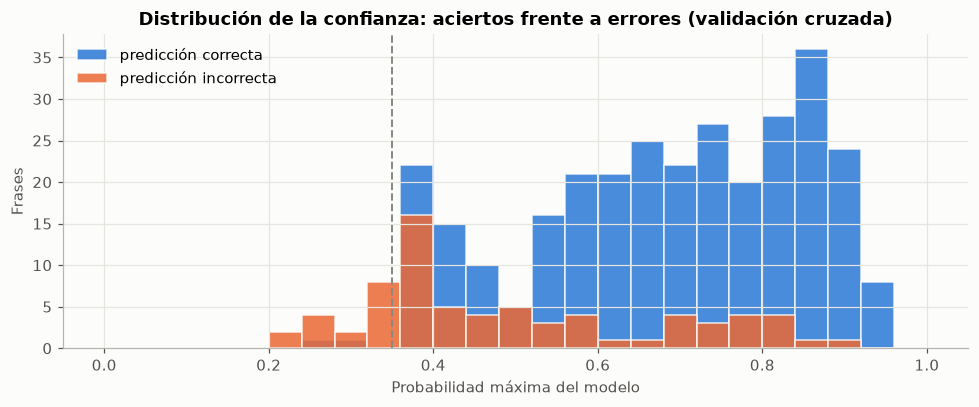

Confianza mediana — aciertos: 0.71 | errores: 0.44


In [50]:
# C4: frases fuera de dominio que el modelo trata como consulta de negocio (con el umbral actual)
pred_035 = aplicar_umbral(probas_cv, clases_arr, UMBRAL_CONFIANZA)
FDD_COMO_NEGOCIO = (pred_035[es_fdd] != INTENCION_FALLBACK).mean()
print(f"Fuera de dominio tratadas como negocio: {FDD_COMO_NEGOCIO:.1%} de {es_fdd.sum()} frases (criterio C4)")

fig, ax = plt.subplots(figsize=(9, 3.8))
acierto = pred_cv == y.values
bins = np.linspace(0, 1, 26)
ax.hist(conf_cv[acierto], bins=bins, color=AZUL, alpha=0.85, label="predicción correcta", edgecolor="#fcfcfb")
ax.hist(conf_cv[~acierto], bins=bins, color=NARANJA, alpha=0.85, label="predicción incorrecta", edgecolor="#fcfcfb")
ax.axvline(UMBRAL_CONFIANZA, color=GRIS, linestyle="--", linewidth=1.3)
ax.legend(frameon=False)
ax.set_title("Distribución de la confianza: aciertos frente a errores (validación cruzada)")
ax.set_xlabel("Probabilidad máxima del modelo"); ax.set_ylabel("Frases")
plt.tight_layout(); plt.show()
print(f"Confianza mediana — aciertos: {np.median(conf_cv[acierto]):.2f} | errores: {np.median(conf_cv[~acierto]):.2f}")

**Lectura.** El umbral de 0.35 hace **menos de lo que se esperaba**:

- Entre umbral 0 y 0.35, la fracción de frases fuera de dominio atrapadas solo pasa de 0.66 a 0.68 (**una frase de 50**), mientras que las consultas de negocio enviadas a `fuera_de_dominio` pasan de 1.9 % a 6.5 %. La accuracy global baja de 0.813 a 0.807. Casi todo lo que se atrapa fuera de dominio lo atrapa la propia clase `fuera_de_dominio`, no el umbral.
- Subirlo más no compensa: con 0.6 se atrapa el 78 % de lo ajeno, pero se descarta el 35.5 % de las consultas de negocio y la accuracy cae a 0.647.
- El umbral sí tiene sentido como red de seguridad (los errores tienen confianza mediana 0.44 frente a 0.71 de los aciertos), pero **no resuelve el criterio C4**: el 32 % de las frases fuera de dominio se tratan como consultas de negocio, y los casos más graves tienen confianza alta (§5.4).
- **Recomendación:** mantener 0.35 (no hay evidencia para moverlo con estos datos) y atacar C4 con datos: agregar a `fuera_de_dominio` frases ajenas que usen palabras del negocio («¿cuánto falta para…?», «¿tienen parqueadero?»). Con el holdout (3-4 frases por clase) no se puede afinar este valor.

### 5.6 Evaluación del extractor de entidades (NER), campo por campo

Se reproduce el bucle de `eval/eval_ner.py` con las mismas listas fijas del catálogo semilla (`MARCAS`, `MODELOS`, `CATEGORIAS`, importadas del script) y la misma función de comparación `_coincide`, pero **sin escribir** `eval/resultados_ner.json`.

,evaluados,aciertos,precisión
marca,11,11,1.0
modelo,11,11,1.0
categoria,6,6,1.0
anio,5,5,1.0
combustible,3,3,1.0
motor,2,2,1.0
codigo,2,2,1.0


Casos: 12 | campos evaluados: 40 | precisión global: 1.000 (criterio C5)
Errores: 0


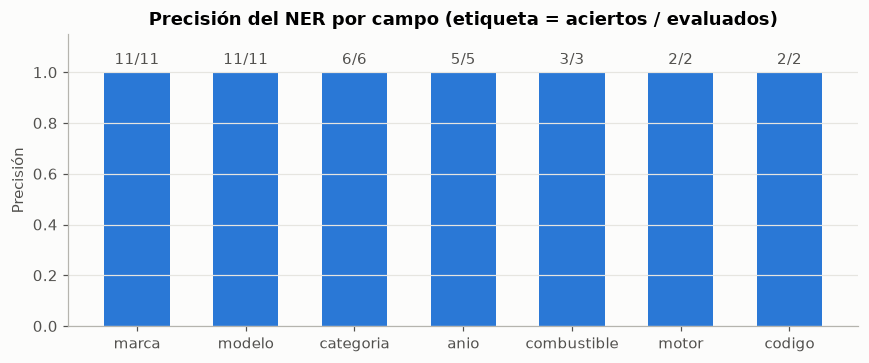

In [51]:
casos_ner = json.loads(HOLDOUT_NER_PATH.read_text(encoding="utf-8"))
aciertos, totales, errores_ner, t_ner = Counter(), Counter(), [], []
for caso in casos_ner:
    t0 = time.perf_counter()
    ent = extraer_entidades(caso["texto"], marcas_conocidas=MARCAS, modelos_conocidos=MODELOS,
                            categorias_conocidas=CATEGORIAS)
    t_ner.append(time.perf_counter() - t0)
    for campo, esperado in caso["esperado"].items():
        totales[campo] += 1
        if _coincide(esperado, ent.get(campo)):
            aciertos[campo] += 1
        else:
            errores_ner.append({"texto": caso["texto"], "campo": campo, "esperado": esperado, "obtenido": ent.get(campo)})

ner_tabla = pd.DataFrame({"evaluados": totales, "aciertos": aciertos}).fillna(0).astype(int)
ner_tabla["precisión"] = (ner_tabla["aciertos"] / ner_tabla["evaluados"]).round(3)
ner_tabla = ner_tabla.sort_values("evaluados", ascending=False)
PREC_NER = sum(aciertos.values()) / sum(totales.values())
display(ner_tabla)
print(f"Casos: {len(casos_ner)} | campos evaluados: {sum(totales.values())} | precisión global: {PREC_NER:.3f} (criterio C5)")
print(f"Errores: {len(errores_ner)}"); display(pd.DataFrame(errores_ner)) if errores_ner else None

fig, ax = plt.subplots(figsize=(8, 3.4))
b = ax.bar(ner_tabla.index, ner_tabla["precisión"], color=AZUL, width=0.6)
ax.bar_label(b, labels=[f"{a}/{e}" for a, e in zip(ner_tabla["aciertos"], ner_tabla["evaluados"])], padding=3, color="#52514e")
ax.set_ylim(0, 1.15); ax.set_ylabel("Precisión")
ax.set_title("Precisión del NER por campo (etiqueta = aciertos / evaluados)")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [52]:
# ¿Qué parte del resultado depende del diccionario de sinónimos, agregado DESPUÉS de ver este holdout?
print("SINONIMOS_CATEGORIA:", SINONIMOS_CATEGORIA)
casos_cat = [c for c in casos_ner if "categoria" in c["esperado"]]
sin_sinonimo = []
for c in casos_cat:
    usa_sinonimo = any(p in normalizar(c["texto"]) for p in SINONIMOS_CATEGORIA)
    sin_sinonimo.append({"texto": c["texto"], "categoría esperada": c["esperado"]["categoria"],
                         "resuelta por sinónimo": usa_sinonimo})
display(pd.DataFrame(sin_sinonimo))
n_sin = sum(1 for s in sin_sinonimo if s["resuelta por sinónimo"])
print(f"{n_sin} de {len(casos_cat)} casos de categoría dependen del diccionario de sinónimos.")

SINONIMOS_CATEGORIA: {'bujia': 'Encendido', 'bujias': 'Encendido', 'correa': 'Correas y Bandas', 'correas': 'Correas y Bandas'}


,texto,categoría esperada,resuelta por sinónimo
0,no hay filtro de aceite original de toyota para hilux 2.7 gasolina 2024,Filtros,False
1,necesito pastillas de freno para mazda 3 2020,Frenos,False
2,bateria para chevrolet spark 2019,Baterías,False
3,correa de distribucion gates para nissan sentra,Correas y Bandas,True
4,bujias ngk para un hyundai accent 2016,Encendido,True
5,filtro para kia sportage diesel,Filtros,False


2 de 6 casos de categoría dependen del diccionario de sinónimos.


**Lectura.** Marca, modelo, año, motor, combustible y código se extraen bien en todos los casos evaluados, incluido el error de tipeo «toyta» → Toyota. Pero hay que decir tres cosas:

1. **El conjunto es muy chico**: 12 frases; motor y código se evalúan con 2 casos cada uno. Un 100 % sobre 2 casos no es evidencia fuerte.
2. **La categoría está sobreajustada al holdout.** `docs/evaluacion.md` documenta que `SINONIMOS_CATEGORIA` se creó para corregir justamente los dos errores de este holdout. La mejora es real, pero la precisión perfecta en categoría no mide generalización: un sinónimo no anticipado («platinos», «faja») seguiría fallando.
3. La evaluación usa una **foto fija** del catálogo (`eval_ner.py`), no el diccionario dinámico que el servicio pide al backend.

### 5.7 Recomendador de sustitutos

`eval/eval_recomendador.py` necesita el backend PHP con el catálogo semilla cargado, así que aquí se **leen** los resultados guardados en `eval/resultados_recomendador.json`.

In [53]:
reco = json.loads(RESULTADOS_RECO_PATH.read_text(encoding="utf-8"))
fecha_reco = subprocess.run(["git", "log", "-1", "--format=%ad", "--date=short", "--", "eval/resultados_recomendador.json"],
                            cwd=RAIZ, capture_output=True, text=True).stdout.strip() or "desconocida"
filas = []
for d in reco["detalle"]:
    filas.append({"consulta": d["texto"][:60], "candidatos con stock": len(d.get("codigos_rankeados", [])),
                  "top-3 devuelto": ", ".join(d.get("codigos_rankeados", [])[:3]),
                  "correctos": ", ".join(d.get("codigos_correctos", [])),
                  "acierto@1": d.get("top1_ok"), "acierto@3": d.get("top3_ok")})
tabla_reco = pd.DataFrame(filas)
display(tabla_reco)
P1, P3 = reco["precision_top1"], reco["precision_top3"]
triviales = (tabla_reco["candidatos con stock"] <= 3).sum()
print(f"Fecha de los resultados (último commit): {fecha_reco}")
print(f"Precisión@1 = {P1:.3f} | Precisión@3 = {P3:.3f} | casos = {reco['n_casos']} (criterio C6)")
print(f"Casos con 3 candidatos o menos (donde precisión@3 no puede fallar si hay candidatos): {triviales} de {len(tabla_reco)}")

,consulta,candidatos con stock,top-3 devuelto,correctos,acierto@1,acierto@3
0,No hay filtro de aceite original de Toyota para Hilux 2.7 ga,2,"HP-1002, M1-102","HP-1002, M1-102",True,True
1,tienen pastillas de freno para mazda 3 2020,2,"BRM-FD204, BSH-0281","BRM-FD204, BSH-0281",True,True
2,necesito bujias para kia rio 2017,1,NGK-BKR6E,NGK-BKR6E,True,True
3,hay bateria para chevrolet spark 2019,1,MAC-48D,MAC-48D,True,True
4,correa de distribucion para nissan sentra,1,GAT-T295,GAT-T295,True,True
5,tienen filtro de aceite para toyota fortuner,2,"HP-1002, M1-102","90915-YZZD4, HP-1002, M1-102",True,True


Fecha de los resultados (último commit): 2026-09-05
Precisión@1 = 1.000 | Precisión@3 = 1.000 | casos = 6 (criterio C6)
Casos con 3 candidatos o menos (donde precisión@3 no puede fallar si hay candidatos): 6 de 6


**Lectura.** La precisión@3 guardada es perfecta, pero en **todos** los casos el backend devolvió como mucho tres candidatos con stock, así que la métrica mide «¿encontró algún candidato compatible?» y no «¿lo ordenó mejor que las alternativas?». Además los resultados son anteriores al cambio de dataset (el recomendador no usa el clasificador de intención, así que eso no los invalida, pero sí la fecha: el catálogo real ahora está en Oracle).

Para ver el **ranking** en sí, sin backend, abajo se usa `SimilitudTfidfCoseno` (la clase del proyecto) sobre los repuestos reales de la categoría *Filtros* del archivo semilla `database/seed_vehiculos.sql`, con stock > 0. No es la cadena de producción (no filtra por compatibilidad de vehículo); es una prueba del ordenamiento con distractores reales.

In [54]:
semilla = (RAIZ.parent / "database" / "seed_vehiculos.sql")
if semilla.exists():
    sql = semilla.read_text(encoding="utf-8")
    patron = re.compile(r"SELECT '([^']+)','([^']+)','([^']+)',\s*\(SELECT id FROM categorias WHERE nombre='([^']+)'\).*?,\s*[\d.]+,\s*[\d.]+,\s*(\d+),\s*\d+;", re.S)
    catalogo = pd.DataFrame(patron.findall(sql), columns=["codigo", "nombre", "descripcion", "categoria", "stock"]).astype({"stock": int})
    print(f"Repuestos leídos del seed: {len(catalogo)}")
    filtros = catalogo[(catalogo["categoria"] == "Filtros") & (catalogo["stock"] > 0)].to_dict("records")
    consulta = "No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, que recomiendo"
    ranking = SimilitudTfidfCoseno().rankear(consulta, filtros)
    print(f"Consulta: «{consulta}»  ({len(filtros)} filtros con stock como candidatos)")
    display(pd.DataFrame(ranking)[["codigo", "nombre", "descripcion", "similitud"]].round(3))
    esperados = {"HP-1002", "M1-102"}
    top2 = {r["codigo"] for r in ranking[:2]}
    print(f"¿Los dos sustitutos esperados (HP-1002, M1-102) ocupan los dos primeros puestos? {top2 == esperados}")
else:
    print("No se encontró database/seed_vehiculos.sql; se omite la prueba de ranking.")

Repuestos leídos del seed: 23
Consulta: «No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, que recomiendo»  (5 filtros con stock como candidatos)


,codigo,nombre,descripcion,similitud
0,HP-1002,Filtro de aceite K&N HP-1002,"Filtro de aceite de alto flujo, compatible con motores 2.7L gasolina",0.207
1,M1-102,Filtro de aceite Mobil 1 M1-102,Filtro de aceite sintético de larga duración para motores 2.7L gasolina,0.207
2,FG-LF3970,Filtro de aceite de motor Fleetguard,Filtro de aceite para motores diésel de tractores e implementos,0.143
3,CIH-FF7000,Filtro de combustible Case IH,Filtro de combustible diésel equivalente para tractores serie Puma,0.045
4,MF-FF6800,Filtro de combustible Massey Ferguson,Filtro de combustible diésel equivalente para tractores serie 4700,0.045


¿Los dos sustitutos esperados (HP-1002, M1-102) ocupan los dos primeros puestos? True


### 5.8 Latencia local

In [55]:
consultas_lat = pd.concat([df["texto"], ho["texto"]]).tolist()
tiempos = []
for t in consultas_lat:
    t0 = time.perf_counter()
    predecir_intencion(t, pipeline=modelo)
    extraer_entidades(t, marcas_conocidas=MARCAS, modelos_conocidos=MODELOS, categorias_conocidas=CATEGORIAS)
    tiempos.append((time.perf_counter() - t0) * 1000)
tiempos = np.array(tiempos)
P95_MS = np.percentile(tiempos, 95)
print(f"{len(tiempos)} consultas | mediana {np.median(tiempos):.2f} ms | p95 {P95_MS:.2f} ms | máx {tiempos.max():.2f} ms (criterio C7)")
print("No incluye la consulta HTTP al backend (catálogo), que es la parte dominante en producción.")

402 consultas | mediana 1.40 ms | p95 2.87 ms | máx 4.70 ms (criterio C7)
No incluye la consulta HTTP al backend (catálogo), que es la parte dominante en producción.


### 5.9 Resumen frente a los criterios de éxito

In [56]:
f1_cv = tabla_modelos.loc["A · Proyecto (unigramas, C=15)", "F1 macro"]
criterios = [
    ("C1", "F1 macro CV (5 partes)", f"{f1_cv:.3f}", ">= 0.80", f1_cv >= 0.80, "374 frases, 50 particiones"),
    ("C2", "Accuracy holdout limpio (con umbral)", f"{ACC_HOLDOUT:.3f}", ">= 0.80", ACC_HOLDOUT >= 0.80,
     f"n={len(res_limpio)}; holdout contaminado (§3.3): optimista"),
    ("C3", "Recall recomendar_sustituto (CV)", f"{RECALL_SUSTITUTO:.3f}", ">= 0.90", RECALL_SUSTITUTO >= 0.90, "56 frases"),
    ("C4", "Fuera de dominio tratadas como negocio (CV)", f"{FDD_COMO_NEGOCIO:.1%}", "<= 15 %", FDD_COMO_NEGOCIO <= 0.15, f"{es_fdd.sum()} frases"),
    ("C5", "Precisión global NER", f"{PREC_NER:.3f}", ">= 0.90", PREC_NER >= 0.90, "12 casos; categoría ajustada al holdout"),
    ("C6", "Precisión@3 recomendador", f"{P3:.3f}", ">= 0.80", P3 >= 0.80, f"{reco['n_casos']} casos, todos con <= 3 candidatos: no concluyente"),
    ("C7", "Latencia p95 intención + NER", f"{P95_MS:.1f} ms", "< 100 ms", P95_MS < 100, "sin contar el backend"),
    ("C8", "Ventaja sobre la línea base trivial (F1)", f"+{100 * (f1_cv - f1_dummy):.1f} pts", ">= +50 pts", (f1_cv - f1_dummy) >= 0.50, ""),
]
resumen = pd.DataFrame(criterios, columns=["ID", "criterio", "resultado", "meta", "cumple", "confiabilidad de la evidencia"]).set_index("ID")
resumen["cumple"] = resumen["cumple"].map({True: "sí", False: "NO"})
display(resumen)

,criterio,resultado,meta,cumple,confiabilidad de la evidencia
ID,,,,,
C1,F1 macro CV (5 partes),0.820,>= 0.80,sí,"374 frases, 50 particiones"
C2,Accuracy holdout limpio (con umbral),0.926,>= 0.80,sí,n=27; holdout contaminado (§3.3): optimista
C3,Recall recomendar_sustituto (CV),0.804,>= 0.90,NO,56 frases
C4,Fuera de dominio tratadas como negocio (CV),32.0%,<= 15 %,NO,50 frases
C5,Precisión global NER,1.000,>= 0.90,sí,12 casos; categoría ajustada al holdout
C6,Precisión@3 recomendador,1.000,>= 0.80,sí,"6 casos, todos con <= 3 candidatos: no concluyente"
C7,Latencia p95 intención + NER,2.9 ms,< 100 ms,sí,sin contar el backend
C8,Ventaja sobre la línea base trivial (F1),+78.4 pts,>= +50 pts,sí,


### 5.10 Tablas consolidadas de métricas y registro de las predicciones en la base de datos

Esta sección reúne en tablas las métricas que arriba aparecen repartidas y guarda cada predicción del modelo en la tabla `nlp_predicciones`, que es la **salida** del proceso de evaluación. Las últimas tablas y la gráfica se calculan con SQL sobre esa tabla.

Las cifras de validación cruzada de esta sección salen de **una** pasada de 5 partes **con** umbral (la misma de §5.3 a §5.5). Por eso difieren un poco del F1 0.820 de §4, que es el promedio de 50 particiones **sin** umbral.

In [57]:
from sklearn.metrics import precision_score, recall_score

def metricas_globales(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    return {"accuracy": accuracy_score(real, pred),
            "precision macro": precision_score(real, pred, average="macro", zero_division=0),
            "recall macro": recall_score(real, pred, average="macro", zero_division=0),
            "F1 macro": f1_score(real, pred, average="macro"),
            "F1 ponderado": f1_score(real, pred, average="weighted"),
            "aciertos": int((real == pred).sum()), "errores": int((real != pred).sum()), "frases": len(real)}

tabla_global = pd.DataFrame({
    f"Validación cruzada 5 partes, con umbral (n={len(y)})": metricas_globales(y, pred_cv),
    f"Holdout limpio, con umbral (n={len(res_limpio)})": metricas_globales(res_limpio["intencion"], res_limpio["predicho"]),
}).T
display(Markdown("**Tabla 1. Métricas globales**"))
display(tabla_global.round(3))

def por_clase(real, pred):
    p, r, f, s = precision_recall_fscore_support(real, pred, labels=etiquetas, zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "F1": f, "frases": s}, index=etiquetas)

tabla_clases = pd.concat({"Validación cruzada": por_clase(y, pred_cv),
                          "Holdout limpio": por_clase(res_limpio["intencion"], res_limpio["predicho"])}, axis=1)
display(Markdown("**Tabla 2. Métricas por intención**"))
display(tabla_clases.round(3))

**Tabla 1. Métricas globales**

,accuracy,precision macro,recall macro,F1 macro,F1 ponderado,aciertos,errores,frases
"Validación cruzada 5 partes, con umbral (n=374)",0.807,0.813,0.807,0.809,0.810,302.0,72.0,374.0
"Holdout limpio, con umbral (n=27)",0.926,0.936,0.929,0.923,0.925,25.0,2.0,27.0


**Tabla 2. Métricas por intención**

Validación cruzada                       \
                                  precision recall     F1 frases   
buscar_repuesto                       0.723  0.839  0.777     56   
consultar_compatibilidad              0.846  0.880  0.863     50   
consultar_precio                      0.824  0.750  0.785     56   
consultar_stock                       0.940  0.839  0.887     56   
fuera_de_dominio                      0.618  0.680  0.648     50   
recomendar_sustituto                  0.900  0.804  0.849     56   
saludo_despedida                      0.843  0.860  0.851     50   

                         Holdout limpio                       
                              precision recall     F1 frases  
buscar_repuesto                    1.00   0.75  0.857      4  
consultar_compatibilidad           1.00   1.00  1.000      4  
consultar_precio                   0.80   1.00  0.889      4  
consultar_stock                    1.00   1.00  1.000      4  
fuera_de_dominio                   0.75   1.00  0.857      3  
recomendar_sustituto               1.00   0.75  0.857      4  
saludo_despedida                   1.00   1.00  1.000      4

In [58]:
# Matrices de confusión como tablas numéricas (filas = intención real, columnas = intención predicha)
for numero, titulo, real, pred in [
        (3, f"Validación cruzada (n={len(y)})", y, pred_cv),
        (4, f"Holdout limpio (n={len(res_limpio)})", res_limpio["intencion"], res_limpio["predicho"])]:
    cm = pd.DataFrame(confusion_matrix(real, pred, labels=etiquetas),
                      index=pd.Index(etiquetas, name="real ↓"), columns=pd.Index(etiquetas, name="predicha →"))
    cm["total"] = cm.sum(axis=1)
    cm.loc["total"] = cm.sum(axis=0)
    display(Markdown(f"**Tabla {numero}. Matriz de confusión: {titulo}** (la diagonal son los aciertos)"))
    display(cm)

**Tabla 3. Matriz de confusión: Validación cruzada (n=374)** (la diagonal son los aciertos)

predicha →,buscar_repuesto,consultar_compatibilidad,consultar_precio,consultar_stock,fuera_de_dominio,recomendar_sustituto,saludo_despedida,total
real ↓,,,,,,,,
buscar_repuesto,47,1,2,1,4,1,0,56
consultar_compatibilidad,2,44,2,0,2,0,0,50
consultar_precio,6,2,42,1,2,2,1,56
consultar_stock,2,1,2,47,3,1,0,56
fuera_de_dominio,4,1,2,1,34,1,7,50
recomendar_sustituto,4,3,0,0,4,45,0,56
saludo_despedida,0,0,1,0,6,0,43,50
total,65,52,51,50,55,50,51,374


**Tabla 4. Matriz de confusión: Holdout limpio (n=27)** (la diagonal son los aciertos)

predicha →,buscar_repuesto,consultar_compatibilidad,consultar_precio,consultar_stock,fuera_de_dominio,recomendar_sustituto,saludo_despedida,total
real ↓,,,,,,,,
buscar_repuesto,3,0,1,0,0,0,0,4
consultar_compatibilidad,0,4,0,0,0,0,0,4
consultar_precio,0,0,4,0,0,0,0,4
consultar_stock,0,0,0,4,0,0,0,4
fuera_de_dominio,0,0,0,0,3,0,0,3
recomendar_sustituto,0,0,0,0,1,3,0,4
saludo_despedida,0,0,0,0,0,0,4,4
total,3,4,5,4,4,3,4,27


In [59]:
# SALIDA: cada predicción se guarda en la tabla nlp_predicciones
con.execute("DELETE FROM nlp_predicciones")
MODELO_DESC = f"TF-IDF unigramas + regresión logística C=15, umbral {UMBRAL_CONFIANZA}"
ids_entrenamiento = [i for (i,) in con.execute("SELECT id FROM nlp_frases WHERE conjunto = 'entrenamiento' ORDER BY id")]
id_holdout = dict(con.execute("SELECT texto, id FROM nlp_frases WHERE conjunto = 'holdout'"))
filas = [(fid, "validacion_cruzada", str(p), float(c), int(p == r), MODELO_DESC)
         for fid, p, c, r in zip(ids_entrenamiento, pred_cv, conf_cv, y)]
filas += [(id_holdout[t], "holdout", str(p), float(c), int(p == r), MODELO_DESC)
          for t, p, c, r in zip(res_limpio["texto"], res_limpio["predicho"], res_limpio["confianza"], res_limpio["intencion"])]
con.executemany("INSERT INTO nlp_predicciones (frase_id, metodo, intencion_pred, confianza, correcta, modelo) "
                "VALUES (?, ?, ?, ?, ?, ?)", filas)
con.commit()
print(f"INSERT en nlp_predicciones: {len(filas)} filas "
      f"({len(ids_entrenamiento)} de validación cruzada + {len(res_limpio)} del holdout limpio)")
display(pd.read_sql_query("""
    SELECT p.id, f.texto, i.nombre AS real, p.intencion_pred, p.confianza, p.correcta, p.metodo
    FROM nlp_predicciones p JOIN nlp_frases f ON f.id = p.frase_id JOIN nlp_intenciones i ON i.id = f.intencion_id
    WHERE p.id IN (1, 2, 3, 375, 376)""", con).set_index("id"))

INSERT en nlp_predicciones: 401 filas (374 de validación cruzada + 27 del holdout limpio)


,texto,real,intencion_pred,confianza,correcta,metodo
id,,,,,,
1,"No hay filtro de aceite original de Toyota para una Hilux 2.7 gasolina 2024, ¿qué me r...",recomendar_sustituto,recomendar_sustituto,0.803909,1,validacion_cruzada
2,"Se me acabaron las balatas Brembo para un Mazda 3 2020, ¿hay algo parecido?",recomendar_sustituto,consultar_compatibilidad,0.537401,0,validacion_cruzada
3,"El cliente pide una batería Mac original para un Chevrolet Spark 2019 pero no tenemos,...",recomendar_sustituto,recomendar_sustituto,0.911392,1,validacion_cruzada
375,"Ya no me queda el disco de embrague Sachs para un Renault Duster, deme otra opción",recomendar_sustituto,recomendar_sustituto,0.898587,1,holdout
376,"El cliente necesita una correa de accesorios pero la que pide está agotada, sugiérame ...",recomendar_sustituto,recomendar_sustituto,0.752967,1,holdout


SQL> SELECT i.nombre AS intencion, p.metodo, ROUND(AVG(p.correcta), 3) AS accuracy, COUNT(*) AS frases, ROUND(AVG(p.confianza), 3) AS confianza_media FROM nlp_predicciones p JOIN nlp_frases f ON f.id = p.frase_id JOIN nlp_intenciones i ON i.id = f.intencion_id GROUP BY i.nombre, p.metodo


**Tabla 5. Accuracy por intención, calculada con SQL**

accuracy                     frases  \
metodo                    holdout validacion_cruzada holdout   
intencion                                                      
buscar_repuesto              0.75              0.839     4.0   
consultar_compatibilidad     1.00              0.880     4.0   
consultar_precio             1.00              0.750     4.0   
consultar_stock              1.00              0.839     4.0   
fuera_de_dominio             1.00              0.680     3.0   
recomendar_sustituto         0.75              0.804     4.0   
saludo_despedida             1.00              0.860     4.0   

                                            confianza_media                     
metodo                   validacion_cruzada         holdout validacion_cruzada  
intencion                                                                       
buscar_repuesto                        56.0           0.609              0.631  
consultar_compatibilidad               50.0           0.772              0.624  
consultar_precio                       56.0           0.867              0.653  
consultar_stock                        56.0           0.770              0.662  
fuera_de_dominio                       50.0           0.784              0.542  
recomendar_sustituto                   56.0           0.702              0.668  
saludo_despedida                       50.0           0.700              0.748

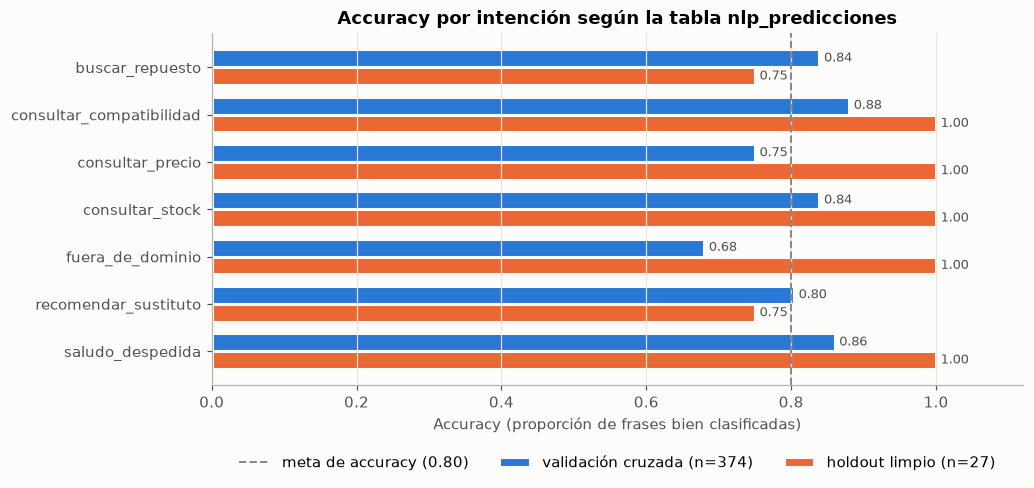

**Tabla 6. Confusiones más frecuentes en validación cruzada, calculadas con SQL**

SQL> SELECT i.nombre AS real, p.intencion_pred AS predicha, COUNT(*) AS errores, ROUND(AVG(p.confianza), 3) AS confianza_media FROM nlp_predicciones p JOIN nlp_frases f ON f.id = p.frase_id JOIN nlp_intenciones i ON i.id = f.intencion_id WHERE p.correcta = 0 AND p.metodo = 'validacion_cruzada' GROUP BY i.nombre, p.intencion_pred ORDER BY errores DESC, confianza_media DESC LIMIT 8


,real,predicha,errores,confianza_media
0,fuera_de_dominio,saludo_despedida,7,0.588
1,saludo_despedida,fuera_de_dominio,6,0.531
2,consultar_precio,buscar_repuesto,6,0.517
3,fuera_de_dominio,buscar_repuesto,4,0.771
4,recomendar_sustituto,buscar_repuesto,4,0.386
5,buscar_repuesto,fuera_de_dominio,4,0.341
6,recomendar_sustituto,fuera_de_dominio,4,0.273
7,recomendar_sustituto,consultar_compatibilidad,3,0.593


**Tabla 7. Confianza del modelo en aciertos y errores, calculada con SQL**

SQL> SELECT metodo, CASE correcta WHEN 1 THEN 'acierto' ELSE 'error' END AS resultado, COUNT(*) AS frases, ROUND(AVG(confianza), 3) AS confianza_media, ROUND(MIN(confianza), 3) AS minima, ROUND(MAX(confianza), 3) AS maxima FROM nlp_predicciones GROUP BY metodo, correcta ORDER BY metodo DESC, correcta DESC


,metodo,resultado,frases,confianza_media,minima,maxima
0,validacion_cruzada,acierto,302,0.683,0.248,0.941
1,validacion_cruzada,error,72,0.495,0.231,0.884
2,holdout,acierto,25,0.770,0.502,0.918
3,holdout,error,2,0.397,0.308,0.485


In [60]:
# Métricas calculadas con SQL sobre la tabla de salida
acc_bd = consultar("""
    SELECT i.nombre AS intencion, p.metodo,
           ROUND(AVG(p.correcta), 3) AS accuracy, COUNT(*) AS frases, ROUND(AVG(p.confianza), 3) AS confianza_media
    FROM nlp_predicciones p
    JOIN nlp_frases f ON f.id = p.frase_id
    JOIN nlp_intenciones i ON i.id = f.intencion_id
    GROUP BY i.nombre, p.metodo""")
pivote = acc_bd.pivot(index="intencion", columns="metodo", values="accuracy").loc[etiquetas]
display(Markdown("**Tabla 5. Accuracy por intención, calculada con SQL**"))
display(acc_bd.pivot(index="intencion", columns="metodo", values=["accuracy", "frases", "confianza_media"]).loc[etiquetas])

fig, ax = plt.subplots(figsize=(9.5, 4.6))
yy, alto = np.arange(len(pivote)), 0.38
b1 = ax.barh(yy - alto / 2, pivote["validacion_cruzada"], height=alto, color=AZUL, edgecolor="#fcfcfb", linewidth=2,
             label=f"validación cruzada (n={len(y)})")
b2 = ax.barh(yy + alto / 2, pivote["holdout"], height=alto, color=NARANJA, edgecolor="#fcfcfb", linewidth=2,
             label=f"holdout limpio (n={len(res_limpio)})")
ax.bar_label(b1, fmt="%.2f", padding=3, color="#52514e", fontsize=8.5)
ax.bar_label(b2, fmt="%.2f", padding=3, color="#52514e", fontsize=8.5)
ax.set_yticks(yy, pivote.index); ax.invert_yaxis(); ax.set_xlim(0, 1.12)
ax.axvline(0.80, color=GRIS, linestyle="--", linewidth=1.3, label="meta de accuracy (0.80)")
ax.set_xlabel("Accuracy (proporción de frases bien clasificadas)")
ax.set_title("Accuracy por intención según la tabla nlp_predicciones")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

display(Markdown("**Tabla 6. Confusiones más frecuentes en validación cruzada, calculadas con SQL**"))
display(consultar("""
    SELECT i.nombre AS real, p.intencion_pred AS predicha, COUNT(*) AS errores, ROUND(AVG(p.confianza), 3) AS confianza_media
    FROM nlp_predicciones p JOIN nlp_frases f ON f.id = p.frase_id JOIN nlp_intenciones i ON i.id = f.intencion_id
    WHERE p.correcta = 0 AND p.metodo = 'validacion_cruzada'
    GROUP BY i.nombre, p.intencion_pred ORDER BY errores DESC, confianza_media DESC LIMIT 8"""))

display(Markdown("**Tabla 7. Confianza del modelo en aciertos y errores, calculada con SQL**"))
display(consultar("""
    SELECT metodo, CASE correcta WHEN 1 THEN 'acierto' ELSE 'error' END AS resultado,
           COUNT(*) AS frases, ROUND(AVG(confianza), 3) AS confianza_media,
           ROUND(MIN(confianza), 3) AS minima, ROUND(MAX(confianza), 3) AS maxima
    FROM nlp_predicciones GROUP BY metodo, correcta ORDER BY metodo DESC, correcta DESC"""))

**Lectura de las tablas de métricas**

- **Globales (Tabla 1):** en validación cruzada el modelo acierta 302 de 374 frases. La accuracy es 0.807 y el F1 macro 0.809; precision y recall macro son casi iguales (0.813 y 0.807), así que el modelo no está sesgado hacia «decir que sí» ni hacia «decir que no». El holdout da cifras más altas (0.926) por las razones de §3.3 y §5.2.
- **Por intención (Tabla 2):** la clase más débil es `fuera_de_dominio` (F1 0.648). `buscar_repuesto` tiene la precision más baja (0.723): la columna de totales de la Tabla 3 muestra que el modelo la predice 65 veces, cuando solo hay 56 frases de esa clase. Funciona como un «cajón» donde caen consultas de otras clases.
- **Confusiones (Tablas 3 y 6):** las más frecuentes son `fuera_de_dominio` ↔ `saludo_despedida` (7 y 6 errores) y `consultar_precio` → `buscar_repuesto` (6). Las 4 frases de `recomendar_sustituto` que terminaron en `fuera_de_dominio` tienen confianza media 0.273, por debajo del umbral: el modelo dudaba y el umbral las descartó.
- **Confianza (Tabla 7):** los aciertos tienen confianza media 0.683 y los errores 0.495. La confianza sí distingue en promedio, pero los rangos se enciman: hay errores con confianza de hasta 0.884. Por eso el umbral no basta (§5.5).
- **Salida guardada:** las 401 predicciones quedaron en `nlp_predicciones`, así que cualquier métrica de esta sección se puede recalcular con una consulta SQL, sin volver a entrenar el modelo.

## 6. Despliegue

### 6.1 Arquitectura

El asistente no se comunica con el navegador directamente: el backend PHP es el único que llama al microservicio. Datos tomados de `backend/src/routes/asistente.php`, `GestorAsistente.php`, `app/main.py`, `app/config.py` y `docker/docker-compose.yml`.

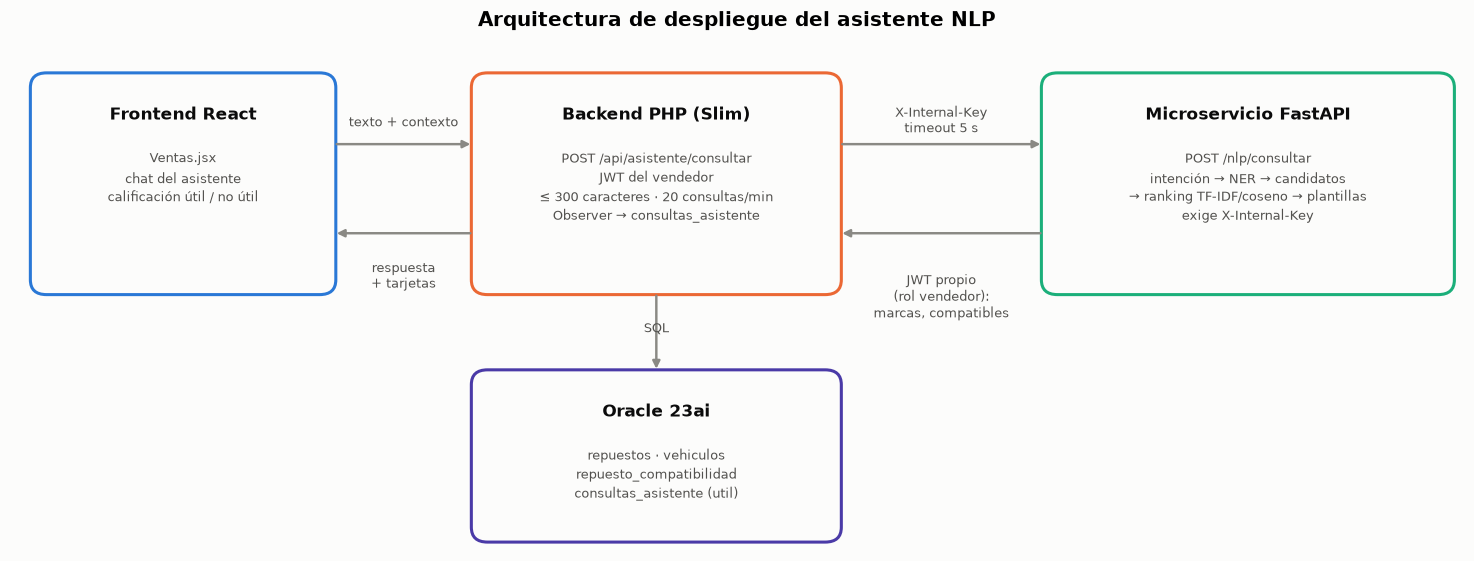

In [61]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13.5, 5.2))
ax.set_xlim(0, 13.5); ax.set_ylim(0, 5.2); ax.axis("off")

def caja(x, y, w, h, titulo, detalle, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                facecolor="#fcfcfb", edgecolor=color, linewidth=2))
    ax.text(x + w / 2, y + h - 0.32, titulo, ha="center", va="top", fontsize=11, fontweight="bold", color="#0b0b0b")
    ax.text(x + w / 2, y + h - 0.75, detalle, ha="center", va="top", fontsize=8.6, color="#52514e", linespacing=1.45)

def flecha(x1, y1, x2, y2, texto, dy=0.18):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color=GRIS, lw=1.6))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2 + dy, texto, ha="center", fontsize=8.3, color="#52514e")

caja(0.2, 2.6, 2.8, 2.2, "Frontend React", "Ventas.jsx\nchat del asistente\ncalificación útil / no útil", AZUL)
caja(4.3, 2.6, 3.4, 2.2, "Backend PHP (Slim)", "POST /api/asistente/consultar\nJWT del vendedor\n≤ 300 caracteres · 20 consultas/min\nObserver → consultas_asistente", NARANJA)
caja(9.6, 2.6, 3.8, 2.2, "Microservicio FastAPI", "POST /nlp/consultar\nintención → NER → candidatos\n→ ranking TF-IDF/coseno → plantillas\nexige X-Internal-Key", AQUA)
caja(4.3, 0.1, 3.4, 1.7, "Oracle 23ai", "repuestos · vehiculos\nrepuesto_compatibilidad\nconsultas_asistente (util)", VIOLETA)

flecha(3.0, 4.1, 4.3, 4.1, "texto + contexto")
flecha(4.3, 3.2, 3.0, 3.2, "respuesta\n+ tarjetas", dy=-0.55)
flecha(7.7, 4.1, 9.6, 4.1, "X-Internal-Key\ntimeout 5 s", dy=0.12)
flecha(9.6, 3.2, 7.7, 3.2, "JWT propio\n(rol vendedor):\nmarcas, compatibles", dy=-0.85)
flecha(6.0, 2.6, 6.0, 1.8, "SQL", dy=0)
ax.set_title("Arquitectura de despliegue del asistente NLP", fontsize=13)
plt.tight_layout(); plt.show()

Puntos clave de despliegue:

- **Contenedor:** `nlp-service/Dockerfile` (Python 3.11-slim, `uvicorn app.main:app`, healthcheck en `/health`), orquestado con `docker/docker-compose.yml` y `docker-compose.prod.yml`.
- **Seguridad entre servicios:** backend → microservicio con `X-Internal-Key`; microservicio → backend con un JWT autofirmado de **rol vendedor** (mínimo privilegio, `app/config.py`). El microservicio nunca toca Oracle directamente.
- **Degradación controlada:** si el catálogo no responde, `BackendNoDisponibleError` produce un mensaje amable en vez de un error 500; si el microservicio cae, el backend responde 503 y la venta sigue funcionando.
- **Riesgo R7 (ver §5.1):** la imagen copia `models/` tal cual; el `.pkl` local está desactualizado.

### 6.2 Demostración con consultas de ejemplo

`procesar_consulta()` (en `app/pipeline.py`) necesita el backend para el diccionario dinámico y los candidatos. Aquí se demuestran las piezas que no lo necesitan, con las mismas funciones del proyecto: intención (modelo en memoria + umbral), entidades (catálogo semilla de `eval_ner.py`), la plantilla fija para saludo/fuera de dominio y la memoria de contexto multi-turno (`_fusionar_entidades`).

In [62]:
consultas_demo = [
    "No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recomienda?",
    "¿Tienen pastillas de freno para Mazda 3 2020?",
    "¿Todavía quedan baterías Mac 48D?",
    "¿Cuánto cuesta el HP-1002?",
    "¿El 90915-YZZD4 le sirve a una toyta Fortuner?",
    "Buenas tardes",
    "¿Quién ganó el partido de ayer?",
    "correa para nissan",
]
filas = []
for t in consultas_demo:
    intencion, conf = predecir_intencion(t, pipeline=modelo)
    ent = extraer_entidades(t, marcas_conocidas=MARCAS, modelos_conocidos=MODELOS, categorias_conocidas=CATEGORIAS)
    filas.append({"consulta": t, "intención": intencion, "confianza": round(conf, 2),
                  "entidades": {k: v for k, v in ent.items() if v is not None},
                  "pide más datos": _falta_vehiculo(intencion, ent),
                  "¿frase del dataset?": normalizar(t) in tr_norm})
pd.set_option("display.max_colwidth", 90)
display(pd.DataFrame(filas))
print("Respuesta fija para saludo_despedida:", templates.responder_fijo("saludo_despedida"))
print("Respuesta fija para fuera_de_dominio:", templates.responder_fijo("fuera_de_dominio"))

,consulta,intención,confianza,entidades,pide más datos,¿frase del dataset?
0,"No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recom...",recomendar_sustituto,0.88,"{'marca': 'Toyota', 'modelo': 'Hilux', 'anio': 2024, 'motor': '2.7', 'combustible': 'g...",False,False
1,¿Tienen pastillas de freno para Mazda 3 2020?,buscar_repuesto,0.68,"{'marca': 'Mazda', 'modelo': '3', 'anio': 2020, 'categoria': 'Frenos'}",False,False
2,¿Todavía quedan baterías Mac 48D?,consultar_stock,0.88,{'categoria': 'Baterías'},False,False
3,¿Cuánto cuesta el HP-1002?,consultar_precio,0.89,{'codigo': 'HP-1002'},False,False
4,¿El 90915-YZZD4 le sirve a una toyta Fortuner?,consultar_compatibilidad,0.62,"{'marca': 'Toyota', 'modelo': 'Fortuner', 'codigo': '90915-YZZD4'}",False,False
5,Buenas tardes,saludo_despedida,0.89,{},False,False
6,¿Quién ganó el partido de ayer?,fuera_de_dominio,0.79,{},False,False
7,correa para nissan,buscar_repuesto,0.40,"{'marca': 'Nissan', 'categoria': 'Correas y Bandas'}",True,False


Respuesta fija para saludo_despedida: ¡Hola! Puedo ayudarte a buscar repuestos, consultar precio o stock, verificar compatibilidad con un vehículo, o recomendar un sustituto si algo está agotado. ¿Qué necesitas?
Respuesta fija para fuera_de_dominio: No tengo información sobre eso. Puedo ayudarte con repuestos: buscar disponibilidad, precio, stock, compatibilidad o sustitutos.


In [63]:
# Diálogo de dos turnos: el primer mensaje no trae el vehículo; el segundo solo trae el vehículo
turno1 = "No hay correa de distribución, ¿qué le ofrezco al cliente?"
turno2 = "Es para un Nissan Sentra 2018"
e1 = extraer_entidades(turno1, marcas_conocidas=MARCAS, modelos_conocidos=MODELOS, categorias_conocidas=CATEGORIAS)
i1, c1 = predecir_intencion(turno1, pipeline=modelo)
print(f"Turno 1: {i1} ({c1:.2f}) | faltan datos del vehículo: {_falta_vehiculo(i1, e1)}")
e2 = extraer_entidades(turno2, marcas_conocidas=MARCAS, modelos_conocidos=MODELOS, categorias_conocidas=CATEGORIAS)
fusion = _fusionar_entidades(e2, e1)
print("Turno 2, entidades fusionadas con el contexto:", {k: v for k, v in fusion.items() if v})
print(f"¿Ya se puede buscar sustituto? {not _falta_vehiculo(i1, fusion)}")

Turno 1: recomendar_sustituto (0.88) | faltan datos del vehículo: True
Turno 2, entidades fusionadas con el contexto: {'marca': 'Nissan', 'modelo': 'Sentra', 'anio': 2018, 'categoria': 'Correas y Bandas'}
¿Ya se puede buscar sustituto? True


Ninguna de las consultas de la demostración está en el dataset (última columna). Para la sustentación:

- La consulta del enunciado se clasifica como `recomendar_sustituto` con confianza alta y extrae las cinco entidades del vehículo.
- «toyta Fortuner» se corrige a Toyota gracias a la búsqueda difusa, y el código `90915-YZZD4` sale por regex.
- «correa para nissan» queda cerca del umbral y sin modelo de vehículo: el pipeline marcaría `esperando_datos` y pediría el modelo en el siguiente turno, como muestra la celda de diálogo.
- «¿Todavía quedan baterías Mac 48D?» extrae la categoría Baterías pero no un vehículo, lo cual es correcto: Mac es la marca del repuesto, no del carro.

### 6.3 Recorrido completo de una consulta: de la entrada a la salida

Se sigue **una sola consulta** por cada paso del flujo de §2.1, mostrando lo que entra y lo que sale en cada uno. Al final la consulta se guarda en `consultas_asistente` con el mismo formato que usa el backend en producción: `AsistenteLogObserver.php` guarda el texto, la intención, las entidades en JSON y la respuesta en JSON.

PASO 1 · ENTRADA: texto que escribe el vendedor
   «No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recomienda?»

PASO 2 · normalizar(): minúsculas, sin tildes ni signos
   «no hay filtro de aceite original de toyota para hilux 2 7 gasolina 2024 que me recomienda»

PASO 3 · preprocesar(): 11 tokens útiles (se quitan las stopwords, se conserva «no»)
   ['no', 'filtro', 'aceite', 'original', 'toyota', 'hilux', '2', '7', 'gasolina', '2024', 'recomienda']

PASO 4 · TF-IDF: vector de 502 posiciones, solo 11 distintas de cero (los tokens que no están en el vocabulario se ignoran)


término,2024,7,toyota,recomienda,hilux,gasolina,2,aceite,original,filtro,no
peso TF-IDF,0.362,0.362,0.347,0.325,0.302,0.302,0.296,0.285,0.24,0.237,0.217


PASO 5 · regresión logística: probabilidad de cada intención (suman 1)


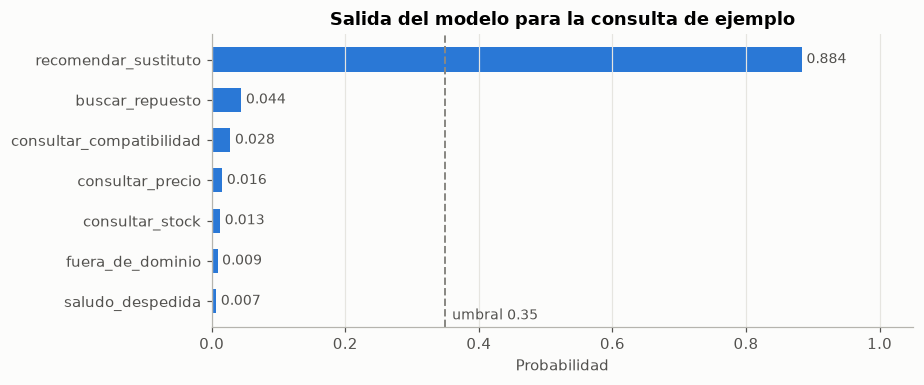

PASO 6 · umbral: la probabilidad máxima es 0.884 ≥ 0.35 → intención final = recomendar_sustituto

PASO 7 · extractor de entidades (NER):
   {'marca': 'Toyota', 'modelo': 'Hilux', 'anio': 2024, 'motor': '2.7', 'combustible': 'gasolina', 'categoria': 'Filtros'}

PASO 8 · SALIDA: respuesta JSON del microservicio
   (sin 'sugerencias' ni 'respuesta_texto', que dependen del catálogo que entrega el backend)
{
  "intencion": "recomendar_sustituto",
  "confianza": 0.8837,
  "entidades": {
    "marca": "Toyota",
    "modelo": "Hilux",
    "anio": 2024,
    "motor": "2.7",
    "combustible": "gasolina",
    "codigo": null,
    "categoria": "Filtros"
  },
  "esperando_datos": false
}

PASO 9 · REGISTRO: INSERT INTO consultas_asistente → fila con id 1


,vendedor,texto_consulta,intencion_detectada,entidades_json,util,creado_en
id,,,,,,
1,Carlos Vendedor,"No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recom...",recomendar_sustituto,"{""marca"": ""Toyota"", ""modelo"": ""Hilux"", ""anio"": 2024, ""motor"": ""2.7"", ""combustible"": ""g...",None,2026-09-29 22:49:31


In [64]:
consulta = "No hay filtro de aceite original de Toyota para Hilux 2.7 gasolina 2024, ¿qué me recomienda?"

print("PASO 1 · ENTRADA: texto que escribe el vendedor")
print(f"   «{consulta}»")
print("\nPASO 2 · normalizar(): minúsculas, sin tildes ni signos")
print(f"   «{normalizar(consulta)}»")
tokens_consulta = preprocesar(consulta)
print(f"\nPASO 3 · preprocesar(): {len(tokens_consulta)} tokens útiles (se quitan las stopwords, se conserva «no»)")
print(f"   {tokens_consulta}")
vec = tfidf.transform([consulta])
print(f"\nPASO 4 · TF-IDF: vector de {vec.shape[1]} posiciones, solo {vec.nnz} distintas de cero "
      f"(los tokens que no están en el vocabulario se ignoran)")
display(pd.DataFrame({"término": vocab_m[vec.indices], "peso TF-IDF": vec.data.round(3)})
        .sort_values("peso TF-IDF", ascending=False).set_index("término").T)

probas_consulta = pd.Series(modelo.predict_proba([consulta])[0], index=clf.classes_).sort_values()
print("PASO 5 · regresión logística: probabilidad de cada intención (suman 1)")
fig, ax = plt.subplots(figsize=(8.5, 3.6))
b = ax.barh(probas_consulta.index, probas_consulta.values, color=AZUL, height=0.6)
ax.bar_label(b, fmt="%.3f", padding=3, color="#52514e", fontsize=9)
ax.axvline(UMBRAL_CONFIANZA, color=GRIS, linestyle="--", linewidth=1.3)
ax.text(UMBRAL_CONFIANZA + 0.01, -0.45, f"umbral {UMBRAL_CONFIANZA}", color="#52514e", fontsize=9)
ax.set_xlim(0, 1.05); ax.set_xlabel("Probabilidad"); ax.grid(axis="y", visible=False)
ax.set_title("Salida del modelo para la consulta de ejemplo")
plt.tight_layout(); plt.show()

intencion, confianza = predecir_intencion(consulta, pipeline=modelo)
print(f"PASO 6 · umbral: la probabilidad máxima es {confianza:.3f} "
      f"{'≥' if confianza >= UMBRAL_CONFIANZA else '<'} {UMBRAL_CONFIANZA} → intención final = {intencion}")
entidades = extraer_entidades(consulta, marcas_conocidas=MARCAS, modelos_conocidos=MODELOS, categorias_conocidas=CATEGORIAS)
print("\nPASO 7 · extractor de entidades (NER):")
print("  ", {k: v for k, v in entidades.items() if v is not None})

respuesta = {"intencion": intencion, "confianza": round(confianza, 4), "entidades": entidades,
             "esperando_datos": _falta_vehiculo(intencion, entidades)}
print("\nPASO 8 · SALIDA: respuesta JSON del microservicio")
print("   (sin 'sugerencias' ni 'respuesta_texto', que dependen del catálogo que entrega el backend)")
print(json.dumps(respuesta, ensure_ascii=False, indent=2))

vendedor_id = con.execute("SELECT id FROM usuarios WHERE email = 'vendedor@electrisys.com'").fetchone()[0]
cur = con.execute("""INSERT INTO consultas_asistente
                         (usuario_id, texto_consulta, intencion_detectada, entidades_json, respuesta_json)
                     VALUES (?, ?, ?, ?, ?)""",
                  (vendedor_id, consulta, intencion, json.dumps(entidades, ensure_ascii=False),
                   json.dumps(respuesta, ensure_ascii=False)))
con.commit()
print(f"\nPASO 9 · REGISTRO: INSERT INTO consultas_asistente → fila con id {cur.lastrowid}")
display(pd.read_sql_query("""
    SELECT c.id, u.nombre AS vendedor, c.texto_consulta, c.intencion_detectada, c.entidades_json, c.util, c.creado_en
    FROM consultas_asistente c JOIN usuarios u ON u.id = c.usuario_id WHERE c.id = ?""",
    con, params=(cur.lastrowid,)).set_index("id"))

In [65]:
# Las consultas de la demostración (§6.2) también se registran, como lo haría el backend
for t in consultas_demo:
    i, c = predecir_intencion(t, pipeline=modelo)
    e = extraer_entidades(t, marcas_conocidas=MARCAS, modelos_conocidos=MODELOS, categorias_conocidas=CATEGORIAS)
    r = {"intencion": i, "confianza": round(c, 4), "entidades": e, "esperando_datos": _falta_vehiculo(i, e)}
    con.execute("""INSERT INTO consultas_asistente
                       (usuario_id, texto_consulta, intencion_detectada, entidades_json, respuesta_json)
                   VALUES (?, ?, ?, ?, ?)""",
                (vendedor_id, t, i, json.dumps(e, ensure_ascii=False), json.dumps(r, ensure_ascii=False)))
con.commit()
# json_extract es la función de SQLite; en Oracle la equivalente es JSON_VALUE(respuesta_json, '$.confianza')
display(consultar("""
    SELECT intencion_detectada, COUNT(*) AS consultas,
           ROUND(AVG(json_extract(respuesta_json, '$.confianza')), 3) AS confianza_media
    FROM consultas_asistente GROUP BY intencion_detectada ORDER BY consultas DESC, intencion_detectada"""))
print("Estas filas son una demostración: en producción las escribe el backend y son la base del monitoreo de §7.")

SQL> SELECT intencion_detectada, COUNT(*) AS consultas, ROUND(AVG(json_extract(respuesta_json, '$.confianza')), 3) AS confianza_media FROM consultas_asistente GROUP BY intencion_detectada ORDER BY consultas DESC, intencion_detectada


,intencion_detectada,consultas,confianza_media
0,buscar_repuesto,2,0.542
1,recomendar_sustituto,2,0.884
2,consultar_compatibilidad,1,0.619
3,consultar_precio,1,0.893
4,consultar_stock,1,0.881
5,fuera_de_dominio,1,0.790
6,saludo_despedida,1,0.893


Estas filas son una demostración: en producción las escribe el backend y son la base del monitoreo de §7.


**Lectura del recorrido**

- **Entrada → tokens:** de 16 palabras quedan 11 tokens útiles, y los 11 existen en el vocabulario del modelo (11 posiciones distintas de cero de 502). «2.7» se parte en «2» y «7» por la normalización (§3.1).
- **Tokens → números:** TF-IDF da más peso a los términos raros («2024», «7», «toyota») y menos a los comunes; «no» recibe el peso más bajo (0.217) porque es el término más frecuente del dataset.
- **Números → intención:** aun con poco peso TF-IDF, «no» tiene el coeficiente más alto de `recomendar_sustituto` (§4.4), y el modelo asigna a esa intención una probabilidad de 0.884, muy por encima del umbral de 0.35.
- **Entidades:** el NER extrae marca, modelo, año, motor, combustible y categoría. Como ya están la marca y el modelo, `esperando_datos` es `false` y el asistente no tiene que pedir más datos. Con esas entidades el backend busca en `repuesto_compatibilidad` los filtros que le sirven a la Hilux y tienen stock: `HP-1002` y `M1-102`, porque el original está agotado (§2.5 y §5.7).
- **Registro:** la consulta queda como una fila de `consultas_asistente`, con la columna `util` en `NULL` hasta que el vendedor la califique con 👍 o 👎 (§7.1).

## 7. Monitoreo y mantenimiento

### 7.1 Qué registra hoy el sistema

- Cada consulta queda en la tabla `consultas_asistente` (texto, intención detectada, entidades, respuesta JSON con la confianza), gracias al Observer `AsistenteLogObserver`.
- El vendedor puede calificar la respuesta con 👍/👎: `PATCH /api/asistente/consultar/{id}/feedback` escribe la columna `util` (1 = útil, 0 = no útil).
- `eval/exportar_feedback.py` descarga las consultas con 👎 **y confianza alta** (por defecto ≥ 0.6) a un CSV con el mismo formato del dataset, para revisión humana. No reentrena solo.

Este cuaderno **no tiene acceso a esas consultas** (requieren el backend y un JWT de rol dueño), así que no se muestran datos de uso real. Lo que sí se puede calcular aquí son las **líneas base** contra las cuales comparar el uso real.

In [66]:
es_negocio = (y != INTENCION_FALLBACK).values
linea_base = {
    "confianza media (CV)": conf_cv.mean(),
    "confianza mediana (CV)": np.median(conf_cv),
    "% de consultas enviadas a fallback por el umbral (CV)": 100 * (conf_cv < UMBRAL_CONFIANZA).mean(),
    "% de frases de negocio descartadas por el umbral (CV)": 100 * ((conf_cv < UMBRAL_CONFIANZA) & es_negocio).sum() / es_negocio.sum(),
    "accuracy con umbral (CV)": acc_cv,
}
display(pd.Series(linea_base).round(3).to_frame("valor de referencia"))

,valor de referencia
confianza media (CV),0.647
confianza mediana (CV),0.670
% de consultas enviadas a fallback por el umbral (CV),4.545
% de frases de negocio descartadas por el umbral (CV),4.630
accuracy con umbral (CV),0.807


### 7.2 Ciclo de mejora con la retroalimentación 👍/👎

1. **Recolectar**: los vendedores califican respuestas en la pantalla de ventas.
2. **Exportar**: `python -m eval.exportar_feedback --umbral-confianza 0.6` (con un JWT de rol dueño) genera `eval/feedback_para_revision.csv`.
3. **Curar a mano**: corregir la intención de cada fila (la exportada es la que predijo el modelo, posiblemente la equivocada) y descartar las que no sean fallas del clasificador (p. ej. falta de stock real).
4. **Agregar al dataset** solo las filas revisadas, cuidando que no sean casi-duplicados del holdout (reutilizar el chequeo de §3.3).
5. **Reentrenar** con `python -m app.intent.train` y **re-evaluar** ejecutando este cuaderno.
6. **Desplegar solo si** el F1 macro de validación cruzada no baja y el holdout congelado no empeora; reconstruir la imagen para que el `.pkl` nuevo viaje con ella.

### 7.3 Alertas sugeridas

| Indicador (sobre `consultas_asistente`) | Referencia | Alerta si… |
|---|---|---|
| % de respuestas con 👎 entre las calificadas, por semana | aún sin datos reales | > 20 %, o sube 10 puntos frente a la semana anterior |
| % de consultas clasificadas `fuera_de_dominio` | fallback de la línea base (§7.1) | se duplica frente a la línea base: posible vocabulario nuevo |
| Confianza media de las consultas reales | confianza media de la línea base (§7.1) | cae más de 0.10: posible deriva del lenguaje de los vendedores |
| 👎 con confianza ≥ 0.6 | — | cualquier caso: el modelo estaba «seguro» y falló; revisar |
| Consultas que terminan en «backend no disponible» | 0 | > 1 % en un día |
| Latencia del endpoint del asistente | p95 local de §5.8 + consulta al catálogo | p95 > 3 s (el backend corta a los 5 s) |
| Edad del modelo servido frente al último cambio del dataset | — | el dataset cambió y el `.pkl` no (el caso de §5.1) |

### 7.4 Mantenimiento: riesgos detectados en el código

- `tests/test_intent.py` llama a `entrenar()` en un *fixture*, y `entrenar()` **sobrescribe** `models/intent_classifier.pkl` y `models/metrics_intent.json`. Correr `pytest` cambia el modelo que se va a desplegar como efecto secundario. Propuesta: que el test entrene en un directorio temporal (parametrizar las rutas o usar `monkeypatch` sobre `MODEL_PATH`).
- Los comentarios de `train.py` y `test_intent.py` describen un dataset de ~60 ejemplos; deben actualizarse.

## 8. Conclusiones y trabajo futuro

Las cifras de esta sección se imprimen en la celda siguiente, a partir de las variables calculadas arriba.

In [67]:
print("RESULTADOS PRINCIPALES")
print(f"- Dataset: {len(df)} frases, {df['intencion'].nunique()} intenciones, razón mayor/menor {conteo.max() / conteo.min():.2f}.")
print(f"- Intención (config. del proyecto): F1 macro CV {f1_cv:.3f} ± {tabla_modelos.loc['A · Proyecto (unigramas, C=15)', '± F1']:.3f}; "
      f"accuracy con umbral CV {acc_cv:.3f}; holdout limpio {ACC_HOLDOUT:.3f} (n={len(res_limpio)}).")
print(f"- Mejor alternativa en F1 CV: {tabla_modelos.drop('Línea base · clase más frecuente')['F1 macro'].idxmax()}; "
      f"bigramas {tabla_modelos.loc['B · Unigramas + bigramas', 'F1 macro']:.3f}, Naive Bayes {tabla_modelos.loc['F · Naive Bayes multinomial', 'F1 macro']:.3f}.")
print(f"- Recall de recomendar_sustituto (CV): {RECALL_SUSTITUTO:.3f}; fuera de dominio tratadas como negocio: {FDD_COMO_NEGOCIO:.1%}.")
print(f"- NER: precisión global {PREC_NER:.3f} sobre {len(casos_ner)} casos. Recomendador: P@1 {P1:.3f}, P@3 {P3:.3f} ({reco['n_casos']} casos guardados).")
print(f"- Latencia local p95: {P95_MS:.1f} ms.")
print(f"- Base de datos: réplica SQLite de Oracle con {len(tablas)} tablas; dataset en nlp_frases "
      f"({con.execute('SELECT COUNT(*) FROM nlp_frases').fetchone()[0]} filas) y "
      f"{con.execute('SELECT COUNT(*) FROM nlp_predicciones').fetchone()[0]} predicciones en nlp_predicciones; "
      f"script para Oracle en notebooks/salida/{SCRIPT_ORACLE.name}.")
print(f"- Criterios cumplidos: {(resumen['cumple'] == 'sí').sum()} de {len(resumen)}; no cumplidos: {resumen.index[resumen['cumple'] == 'NO'].tolist()}.")
print()
print("PROBLEMAS ENCONTRADOS")
print(f"- Sesgo por nombres de vehículo: {(sesgo['coeficiente'] > 1).sum()} de {len(sesgo)} tokens de vehículo pesan > 1 hacia una intención "
      f"(máximo: '{sesgo.index[0]}' -> {sesgo.iloc[0]['clase a la que más empuja']}, {sesgo.iloc[0]['coeficiente']}).")
print(f"- El umbral 0.35 atrapa solo {int(round((barrido.loc[0.35, 'fuera de dominio atrapado'] - barrido.loc[0.0, 'fuera de dominio atrapado']) * es_fdd.sum()))} "
      f"frase(s) fuera de dominio más que no tener umbral.")
print(f"- Fuga exacta holdout/entrenamiento: {len(fugadas)} frase(s): {fugadas['texto_holdout'].tolist()}")
print(f"- El dataset se amplió con vocabulario de los errores del holdout -> holdout optimista.")
print(f"- models/intent_classifier.pkl desactualizado: {len(guardado.named_steps['tfidf'].vocabulary_)} términos vs {len(vocab_m)} "
      f"del dataset actual; coincide en {coinciden:.0%} de las predicciones del holdout.")
print(f"- models/metrics_intent.json dice {metricas_guardadas['n_ejemplos']} ejemplos; el dataset tiene {len(df)}.")
print(f"- docs/evaluacion.md reporta accuracy 0.821 con el dataset viejo; hoy el holdout limpio da {ACC_HOLDOUT:.3f} y la CV {acc_cv:.3f}.")

RESULTADOS PRINCIPALES
- Dataset: 374 frases, 7 intenciones, razón mayor/menor 1.12.
- Intención (config. del proyecto): F1 macro CV 0.820 ± 0.037; accuracy con umbral CV 0.807; holdout limpio 0.926 (n=27).
- Mejor alternativa en F1 CV: D · C=100 (menos regularización); bigramas 0.731, Naive Bayes 0.631.
- Recall de recomendar_sustituto (CV): 0.804; fuera de dominio tratadas como negocio: 32.0%.
- NER: precisión global 1.000 sobre 12 casos. Recomendador: P@1 1.000, P@3 1.000 (6 casos guardados).
- Latencia local p95: 2.9 ms.
- Base de datos: réplica SQLite de Oracle con 18 tablas; dataset en nlp_frases (402 filas) y 401 predicciones en nlp_predicciones; script para Oracle en notebooks/salida/12_dataset_nlp_oracle.sql.
- Criterios cumplidos: 6 de 8; no cumplidos: ['C3', 'C4'].

PROBLEMAS ENCONTRADOS
- Sesgo por nombres de vehículo: 24 de 29 tokens de vehículo pesan > 1 hacia una intención (máximo: 'hilux' -> recomendar_sustituto, 3.91).
- El umbral 0.35 atrapa solo 1 frase(s) fuera de d

**Conclusiones**

1. **El clasificador de intención funciona, con límites claros.** Con una técnica simple y explicable (TF-IDF + regresión logística) alcanza F1 macro 0.820 en validación cruzada, la evidencia más confiable disponible, y cumple 6 de los 8 criterios. La comparación de configuraciones respalda la elección del proyecto: los bigramas y Naive Bayes rinden peor, `balanced` no aporta y la ventaja de C=100 no es concluyente.
2. **No se cumplen dos criterios importantes para el negocio:** el recall de `recomendar_sustituto` (0.804 frente a 0.90) y el control de frases fuera de dominio (32 % tratadas como negocio frente a 15 %). Ambos se atacan con más datos y mejor dirigidos, no cambiando el algoritmo.
3. **La negación es la decisión de preprocesamiento más importante** del proyecto y los datos la respaldan (§2.11, §4.3).
4. **El modelo aprendió sesgos por nombres de vehículo** («hilux» empuja hacia `recomendar_sustituto`). Es una consecuencia directa de un dataset pequeño escrito a mano, y la interpretabilidad del modelo lineal es lo que permitió detectarlo.
5. **El umbral de 0.35 aporta poco** frente a las frases fuera de dominio: no hay evidencia para moverlo, pero tampoco para presentarlo como la defensa principal contra respuestas absurdas. Además está acoplado al valor de C.
6. **Las métricas del holdout son optimistas** por fuga exacta y por contaminación de vocabulario, y su intervalo de confianza baja de 0.80. No invalidan el modelo, pero no deben presentarse como «generalización a frases nunca vistas» sin esa aclaración.
7. **El NER y el recomendador tienen conjuntos de prueba demasiado pequeños** para conclusiones firmes: 12 casos (categoría ajustada al propio holdout) y 6 casos con a lo sumo 3 candidatos cada uno. El ranking sí ordenó bien los filtros del catálogo semilla frente a distractores (§5.7).
8. **Hay un riesgo operativo concreto**: el modelo guardado no corresponde al dataset actual y el `Dockerfile` lo copia tal cual.

**Correcciones propuestas (no aplicadas por este cuaderno)**

| # | Archivo | Corrección |
|---|---|---|
| 1 | `eval/holdout_intent.csv` | Quitar o reemplazar la frase con fuga exacta; a mediano plazo, redactar un holdout nuevo y congelarlo |
| 2 | `models/intent_classifier.pkl`, `models/metrics_intent.json` | Reentrenar con `python -m app.intent.train` |
| 3 | `nlp-service/Dockerfile` | Agregar `RUN python -m app.intent.train` tras `COPY data ./data` |
| 4 | `docs/evaluacion.md` | Actualizar con las cifras de este cuaderno y explicar la contaminación del holdout |
| 5 | `app/intent/train.py`, `tests/test_intent.py` | Actualizar los comentarios que hablan de ~60 ejemplos; que el test no sobrescriba el modelo real |
| 6 | `eval/eval_intent.py` | Llama a `predecir_intencion` dos veces por frase (una para la etiqueta y otra para la confianza); basta una |
| 7 | `data/intents_dataset.csv` | Quitar uno de cada par duplicado tras preprocesar (§2.10); agregar frases de `recomendar_sustituto` sin «no» explícito («se me acabaron…», «ya no queda…») y frases fuera de dominio con palabras del negocio (§5.4) |
| 8 | `tests/test_dataset.py` | Detectar también duplicados tras `preprocesar()`, no solo exactos |
| 9 | `oracle/` | Agregar `notebooks/salida/12_dataset_nlp_oracle.sql` como `oracle/12_dataset_nlp.sql` y cargarlo en la base real, para que el dataset quede versionado junto al resto del esquema (§2.3) |

**Trabajo futuro**

- Reducir el sesgo por vehículos: reemplazar la marca y el modelo que ya detecta el NER por un marcador (p. ej. `<vehiculo>`) antes de clasificar la intención, y comparar con validación cruzada.

- Incorporar consultas reales de vendedores (vía 👍/👎) y medir el desempeño **por separado** sobre ellas.
- Ampliar el holdout de intención (al menos ~20 frases por clase) para que un error no mueva varios puntos, y el del NER con sinónimos no vistos y más casos de motor y código.
- Evaluar el recomendador con un catálogo real en el que haya más de tres candidatos por consulta, midiendo también NDCG o MRR.
- Revisar C=100 y el umbral juntos cuando haya más datos, con una curva de calibración.
- Mantener el patrón Strategy del recomendador como puerta para probar otra técnica de similitud sin tocar el pipeline, siempre dentro de la restricción de no usar modelos de lenguaje externos.

In [68]:
# Verificación final: ningún archivo protegido cambió durante la ejecución
con.close()
HUELLA_FINAL = huella(PROTEGIDOS)
cambiados = [k for k in HUELLA_INICIAL if HUELLA_FINAL.get(k) != HUELLA_INICIAL[k]]
nuevos_en_eval = sorted(p.name for p in (RAIZ / "eval").iterdir()
                        if p.is_file() and p.relative_to(RAIZ.parent).as_posix() not in HUELLA_INICIAL)
assert not cambiados, f"Se modificaron archivos protegidos: {cambiados}"
assert not nuevos_en_eval, f"Aparecieron archivos nuevos en eval/: {nuevos_en_eval}"
print(f"OK: los {len(HUELLA_INICIAL)} archivos protegidos (models/, eval/, el dataset y oracle/*.sql) "
      f"están intactos (SHA-256 idéntico).")
print("Archivos que escribió el cuaderno:", ", ".join(sorted(f"notebooks/salida/{p.name}" for p in SALIDA.iterdir())))

OK: los 25 archivos protegidos (models/, eval/, el dataset y oracle/*.sql) están intactos (SHA-256 idéntico).
Archivos que escribió el cuaderno: notebooks/salida/12_dataset_nlp_oracle.sql, notebooks/salida/electrisys_nlp.sqlite
